In [ ]:
# python 3.9.6
import argparse
import glob
import os
import sys
from math import exp

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
import torch
import torch.nn.functional as F
from mahotas.thresholding import bernsen
from PIL import Image as PIL_Image
from PIL import ImageOps
from pytorch_msssim import ms_ssim
from scipy.ndimage import gaussian_filter, shift
from scipy.stats import kendalltau
from skimage import img_as_float
from skimage.color import rgb2gray, rgba2rgb
from skimage.filters import threshold_local, threshold_otsu
from skimage.io import imread

# from ssim import SSIM
from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity,
)
from skimage.util import random_noise
from ssim.compat import Image, ImageOps
from ssim.utils import convolve_gaussian_2d, get_gaussian_kernel, to_grayscale

from ssim import compat

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')      


In [ ]:
# data prep
uncropped_images = []
# crop images
for image_path in glob.glob("./OneDrive_1_5-19-2025/**/*.png", recursive=True):
    uncropped_images.append(imread(image_path))
    with PIL_Image.open(image_path) as img:
        width, height = img.size
        crop_box = (0, int(height * 0.1), width, height)
        cropped_img = img.crop(crop_box)

        # Build a filename with all subfolders after the root
        rel_path = os.path.relpath(image_path, start="./OneDrive_1_5-19-2025")
        rel_parts = rel_path.split(os.sep)
        folder_part = "__".join(rel_parts[:-1])  # Join all folder names with __
        orig_filename = rel_parts[-1]

        # Compose new filename
        if folder_part:
            new_filename = f"{folder_part}__{orig_filename}"
        else:
            new_filename = orig_filename

        grayscale_img = img_as_float(rgb2gray(rgba2rgb(cropped_img)))
        np.save(os.path.join("./cropped_grayscale", new_filename.replace('.png', '.npy')), grayscale_img)

# some files only have up to PA6, we remove those
folder = "./cropped_grayscale"
all_files = [f for f in os.listdir(folder) if os.path.isfile(os.path.join(folder, f))]


pa7_base_list=set()
for fname in all_files:
    if "PA7" in fname:
        pa7_base_list.add(fname.split("__PA7")[0])

PA_from_base = dict()
for fname in pa7_base_list:
    PA_from_base[fname] = dict()
    for i in range(1, 8):
        PA_from_base[fname][f"PA{i}"] = np.load(os.path.join(folder, fname + f"__PA{i}.npy"))

greyscaleImages = [x["PA1"] for x in PA_from_base.values()]  

In [ ]:

class SSIMImage:
    """Wraps a PIL Image object with SSIM state.

    Attributes:
      img: Original PIL Image.
      img_gray: grayscale Image.
      img_gray_squared: squared img_gray.
      img_gray_mu: img_gray convolved with gaussian kernel.
      img_gray_mu_squared: squared img_gray_mu.
      img_gray_sigma_squared: img_gray convolved with gaussian kernel -
                              img_gray_mu_squared.
    """
    def __init__(self, img, gaussian_kernel_1d=None, size=None):
        """Create an SSIMImage.

        Args:
          img (str or PIL.Image): PIL Image object or file name.
          gaussian_kernel_1d (np.ndarray, optional): Gaussian kernel
          that was generated with utils.get_gaussian_kernel is used
          to precompute common objects for SSIM computation
          size (tuple, optional): New image size to resize image to.
        """
        # Use existing or create a new PIL.Image
        self.img = img if not isinstance(img, compat.basestring) \
            else compat.Image.open(img)

        # Resize image if size is defined and different
        # from original image
        if size and size != self.img.size:
            self.img = self.img.resize(size, Image.LANCZOS)

        # Set the size of the image
        self.size = self.img.size # This will be (width, height)

        # If gaussian kernel is defined we create
        # common SSIM objects
        if gaussian_kernel_1d is not None:

            self.gaussian_kernel_1d = gaussian_kernel_1d

            # np.array of grayscale and alpha image
            self.img_gray, self.img_alpha = to_grayscale(self.img)
            if self.img_alpha is not None:
                self.img_gray[self.img_alpha == 255] = 0

            # Squared grayscale
            self.img_gray_squared = self.img_gray ** 2

            # Convolve grayscale image with gaussian
            self.img_gray_mu = convolve_gaussian_2d(
                self.img_gray, self.gaussian_kernel_1d)

            # Squared mu
            self.img_gray_mu_squared = self.img_gray_mu ** 2

            # Convolve squared grayscale with gaussian
            self.img_gray_sigma_squared = convolve_gaussian_2d(
                self.img_gray_squared, self.gaussian_kernel_1d)

            # Substract squared mu
            self.img_gray_sigma_squared -= self.img_gray_mu_squared

        # If we don't define gaussian kernel, we create
        # common CW-SSIM objects
        else:
            # Grayscale PIL.Image
            self.img_gray = ImageOps.grayscale(self.img)

class SSIM:
    """Computes SSIM between two images."""
    def __init__(self, img, gaussian_kernel_1d=None, size=None,
                 l=255, k_1=0.01, k_2=0.03, k=0.01):
        """Create an SSIM object.

        Args:
          img (str or PIL.Image): Reference image to compare other images to.
          l, k_1, k_2 (float): SSIM configuration variables.
          k (float): CW-SSIM configuration variable (default 0.01)
          gaussian_kernel_1d (np.ndarray, optional): Gaussian kernel
          that was generated with utils.get_gaussian_kernel is used
          to precompute common objects for SSIM computation
          size (tuple, optional): resize the image to the tuple size
        """
        self.k = k
        # Set k1,k2 & c1,c2 to depend on L (width of color map).
        self.c_1 = (k_1 * l) ** 2
        self.c_2 = (k_2 * l) ** 2
        self.gaussian_kernel_1d = gaussian_kernel_1d
        self.img = SSIMImage(img, gaussian_kernel_1d, size)

    def ssim_value(self, target):
        """Compute the SSIM value from the reference image to the target image.

        Args:
          target (str or PIL.Image): Input image to compare the reference image
          to. This may be a PIL Image object or, to save time, an SSIMImage
          object (e.g. the img member of another SSIM object).

        Returns:
          Computed SSIM float value.
        """
        # Performance boost if handed a compatible SSIMImage object.
        if not isinstance(target, SSIMImage) \
            or not np.array_equal(self.gaussian_kernel_1d,
                                   target.gaussian_kernel_1d):
            target = SSIMImage(target, self.gaussian_kernel_1d, self.img.size)

        img_mat_12 = self.img.img_gray * target.img_gray
        img_mat_sigma_12 = convolve_gaussian_2d(
            img_mat_12, self.gaussian_kernel_1d)
        img_mat_mu_12 = self.img.img_gray_mu * target.img_gray_mu
        img_mat_sigma_12 = img_mat_sigma_12 - img_mat_mu_12

        # Numerator of SSIM
        num_ssim = ((2 * img_mat_mu_12 + self.c_1) *
                    (2 * img_mat_sigma_12 + self.c_2))

        # Denominator of SSIM
        den_ssim = (
            (self.img.img_gray_mu_squared + target.img_gray_mu_squared +
             self.c_1) *
            (self.img.img_gray_sigma_squared +
             target.img_gray_sigma_squared + self.c_2))

        ssim_map = num_ssim / den_ssim
        index = np.average(ssim_map)
        return index

    def cw_ssim_map(self, target, width=30) -> np.ndarray: # Changed return type hint
        """Compute the complex wavelet SSIM (CW-SSIM) map from the reference
        image to the target image.

        Args:
          target (str or PIL.Image): Input image to compare the reference image
          to. This may be a PIL Image object or, to save time, an SSIMImage
          object (e.g. the img member of another SSIM object).
          width: width for the wavelet convolution (default: 30)

        Returns:
          np.ndarray: A 2D NumPy array representing the CW-SSIM map,
                      with dimensions (Height, Width) of the original image.
        """
        if not isinstance(target, SSIMImage):
            target = SSIMImage(target, size=self.img.size)

        # Define a width for the wavelet convolution
        widths = np.arange(1, width + 1)

        # Use the image data as arrays
        # .getdata() flattens the image into a 1D sequence of pixels
        sig1 = np.asarray(self.img.img_gray.getdata())
        sig2 = np.asarray(target.img_gray.getdata())

        # Convolution (Continuous Wavelet Transform)
        cwtmatr1, freqs1 = pywt.cwt(sig1, widths, 'mexh')
        cwtmatr2, freqs2 = pywt.cwt(sig2, widths, 'mexh')

        # Compute the first term
        c1c2 = np.multiply(np.abs(cwtmatr1), np.abs(cwtmatr2)) # Added np.abs
        c1_2 = np.square(np.abs(cwtmatr1)) # Added np.abs
        c2_2 = np.square(np.abs(cwtmatr2)) # Added np.abs
        num_ssim_1 = 2 * np.sum(c1c2, axis=0) + self.k
        den_ssim_1 = np.sum(c1_2, axis=0) + np.sum(c2_2, axis=0) + self.k

        # Compute the second term
        c1c2_conj = np.multiply(cwtmatr1, np.conjugate(cwtmatr2))
        num_ssim_2 = 2 * np.abs(np.sum(c1c2_conj, axis=0)) + self.k
        den_ssim_2 = 2 * np.sum(np.abs(c1c2_conj), axis=0) + self.k

        # Construct the per-pixel result (still 1D at this point)
        ssim_map_1d = (num_ssim_1 / den_ssim_1) * (num_ssim_2 / den_ssim_2)

        # Reshape the 1D ssim_map back to 2D image dimensions
        # self.img.size is (width, height), so reshape needs (height, width)
        img_width, img_height = self.img.size
        ssim_map_2d = ssim_map_1d.reshape((img_height, img_width))

        return ssim_map_2d # Return the 2D map

def main():
    """Main function for pyssim."""

    description = '\n'.join([
        'Compares an image with a list of images using the SSIM metric.',
        '  Example:',
        '    pyssim test-images/test1-1.png "test-images/*"'
    ])

    parser = argparse.ArgumentParser(
        prog='pyssim', formatter_class=argparse.RawTextHelpFormatter,
        description=description)
    parser.add_argument('--cw', help='compute the complex wavelet SSIM',
                        action='store_true')
    parser.add_argument(
        'base_image', metavar='image1.png', type=argparse.FileType('r'))
    parser.add_argument(
        'comparison_images', metavar='image path with* or image2.png')
    parser.add_argument('--width', type=int, default=None,
                        help='scales the image before computing SSIM')
    parser.add_argument('--height', type=int, default=None,
                        help='scales the image before computing SSIM')

    args = parser.parse_args()

    if args.width and args.height:
        size = (args.width, args.height)
    else:
        size = None

    if not args.cw:
        gaussian_kernel_sigma = 1.5
        gaussian_kernel_width = 11
        gaussian_kernel_1d = get_gaussian_kernel(
            gaussian_kernel_width, gaussian_kernel_sigma)

    comparison_images = glob.glob(args.comparison_images)
    is_a_single_image = len(comparison_images) == 1

    for comparison_image in comparison_images:

        if args.cw:
            ssim = SSIM(args.base_image.name, size=size)
            # This will now return the 2D map
            ssim_map = ssim.cw_ssim_value(comparison_image)
            # If you still need the average, you can compute it here:
            ssim_value = np.average(ssim_map)
        else:
            ssim = SSIM(args.base_image.name, gaussian_kernel_1d, size=size)
            ssim_value = ssim.ssim_value(comparison_image)

        if is_a_single_image:
            sys.stdout.write('%.7g' % ssim_value) # This line still prints the average
        else:
            sys.stdout.write('%s - %s: %.7g' % (
                args.base_image.name, comparison_image, ssim_value))
        sys.stdout.write('\n')


def cw_ssim(img1, img2):
    img_ref_pil = Image.fromarray((img1 * 255).astype(np.uint8)).convert('L')
    img_dist_pil = Image.fromarray((img2 * 255).astype(np.uint8)).convert('L')

    width, height = img_ref_pil.size
    # Instantiate the SSIM class with the reference image
    # For CW-SSIM, gaussian_kernel_1d is None, as per the original code
    ssim_calculator = SSIM(img_ref_pil, size=(width, height))


    # Get the CW-SSIM map
    return ssim_calculator.cw_ssim_map(img_dist_pil)


In [5]:
import numpy as np


def mask_square_over_roi(image: np.ndarray, roi_mask: np.ndarray, distortion_level: float = 0.25):
    """
    Applies a zero-mask square block centered around a position overlapping the ROI.
    If no overlap is found, places the block centered at the bottom-right.

    Args:
        image (np.ndarray): Float image (H, W) or (H, W, C), values in [0, 1].
        roi_mask (np.ndarray): Binary mask (H, W), where 1 indicates ROI.
        distortion_level (float): Fraction of image area to mask.

    Returns:
        np.ndarray: Image with a masked block.
        (int, int, int): (x, y, square_size) — top-left coordinates and size.
    """
    assert image.shape[:2] == roi_mask.shape, "ROI mask must match image shape"
    assert 0 <= distortion_level <= 1.0, "Distortion level must be between 0 and 1"
    assert np.any(roi_mask), "ROI mask is empty (all zeros)."

    h, w = image.shape[:2]
    block_area = distortion_level * h * w
    square_size = int(np.sqrt(block_area))
    square_size = min(square_size, h, w)  # Ensure block fits in image

    result = image.copy()

    y_start = int(0.1 * h)
    x_start = int(0.1 * w)

    # Try to find first position with any overlap with ROI
    for y in range(y_start, h - square_size):
        for x in range(x_start, w - square_size):
            if roi_mask[y,x]:  # Partial overlap allowed
                # Center the square around (x, y)
                cx = x + square_size // 2
                cy = y + square_size // 2
                top_left_x = max(0, min(w - square_size, cx - square_size // 2))
                top_left_y = max(0, min(h - square_size, cy - square_size // 2))

                if image.ndim == 2:
                    result[top_left_y:top_left_y+square_size, top_left_x:top_left_x+square_size] = 0.0
                else:
                    result[top_left_y:top_left_y+square_size, top_left_x:top_left_x+square_size, :] = 0.0

                return result, (top_left_x, top_left_y, square_size)

    # Fallback: center at bottom-right
    cx = w - 1
    cy = h - 1
    top_left_x = max(0, min(w - square_size, cx - square_size // 2))
    top_left_y = max(0, min(h - square_size, cy - square_size // 2))

    if image.ndim == 2:
        result[top_left_y:top_left_y+square_size, top_left_x:top_left_x+square_size] = 0.0
    else:
        result[top_left_y:top_left_y+square_size, top_left_x:top_left_x+square_size, :] = 0.0

    return result, (top_left_x, top_left_y, square_size)




In [43]:

def calculate_combined_mask(img1, img2, sensitivity=0.48, and_or="or"):
    patch_size = 2 * (np.array(img1.shape) // 16) + 1

    # Adaptive thresholding (Gaussian mean)
    block_size = int(np.mean(patch_size))
    if block_size % 2 == 0:
        block_size += 1

    # Compute adaptive thresholds
    mean_thresh1 = threshold_local(img1, block_size, method='gaussian', offset=-(0.5 - sensitivity))
    mean_thresh2 = threshold_local(img2, block_size, method='gaussian', offset=-(0.5 - sensitivity))

    mask1 = img1 > mean_thresh1
    mask2 = img2 > mean_thresh2
    Mask = np.logical_or(mask1, mask2)

    return Mask

def calculate_single_mask(img1, sensitivity=0.5, and_or="or"):
    patch_size = 2 * (np.array(img1.shape) // 16) + 1

    # Adaptive thresholding (Gaussian mean)
    block_size = int(np.mean(patch_size))
    if block_size % 2 == 0:
        block_size += 1

    # Compute adaptive thresholds
    mean_thresh1 = threshold_local(img1, block_size, method='gaussian', offset=-(0.5 - sensitivity))

    mask1 = img1 > mean_thresh1

    return mask1


In [7]:
def s3im(img1, img2, sensitivity=0.5, window_size=7, SSIM_variant=structural_similarity, ms=False, increased_sensitivity=False, increase_sensitivity=True):
    """
    Sparse SSIM (S3IM) implementation in Python
    Inputs:
        img1: test image (grayscale, float)
        img2: reference image (grayscale, float)
        sensitivity: float between 0 and 1 (default 0.5)
    Outputs:
        S3IM_val: scalar SSIM over sparse regions
        S3IM_map: SSIM map (masked)
        Mask: binary mask of significant regions
    """
    Mask = calculate_combined_mask(img1, img2, sensitivity)
    if np.sum(Mask) == 0:
        if increase_sensitivity == True:
            # TODO fallback strategy
            print('inc (1): ', sensitivity)
            increased_sensitivity = True
            return s3im(img1, img2, sensitivity=sensitivity+0.1, window_size=window_size, SSIM_variant=SSIM_variant, increase_sensitivity=increase_sensitivity, increased_sensitivity=increased_sensitivity)
        else:
            return np.nan, 0, False

    if SSIM_variant == structural_similarity:
        # Use standard SSIM
        _, ssim_map = SSIM_variant(img1, img2, full=True, win_size=window_size, data_range=1.0)
        S3IM_map = ssim_map * Mask

    elif SSIM_variant == cw_ssim:
        # Use wavelet-based SSIM (W-SSIM)
        cw_ssim_map = SSIM_variant(img1, img2)


        S3IM_map = cw_ssim_map * Mask

    else:
        raise ValueError("Unknown SSIM variant passed.")

    # Compute final S3IM value
    if np.any(S3IM_map):
        S3IM_val = np.sum(S3IM_map) / np.sum(S3IM_map != 0)
    else:
        if increase_sensitivity == True:
            print('inc (2): ', sensitivity)
            increased_sensitivity=True
            return s3im(img1, img2, sensitivity=sensitivity+0.1, window_size=window_size, SSIM_variant=SSIM_variant,
                        increased_sensitivity=increased_sensitivity, increase_sensitivity=increase_sensitivity)
        else:
            return np.nan, 0, False

    return S3IM_val, Mask, S3IM_map


In [8]:
def msssim(img1, img2):
    ref = torch.from_numpy(img1).unsqueeze(0).unsqueeze(0).float()   # [batch, channel, height, width]
    distorted = torch.from_numpy(img2).unsqueeze(0).unsqueeze(0).float()

    # Move to GPU if available
    # device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    ref = ref.to(device)
    distorted = distorted.to(device)

    # Calculate MS-SSIM
    msssim_value = np.float64(ms_ssim(ref, distorted, data_range=1.0, size_average=False).item())

    return msssim_value

In [ ]:
def gaussian(window_size, sigma):
    gauss = torch.Tensor([exp(-(x - window_size // 2) ** 2 / float(2 * sigma ** 2)) for x in range(window_size)])
    return gauss / gauss.sum()


def create_window(window_size, channel=1):
    _1D_window = gaussian(window_size, 1.5).unsqueeze(1)
    _2D_window = _1D_window.mm(_1D_window.t()).float().unsqueeze(0).unsqueeze(0)
    window = _2D_window.expand(channel, 1, window_size, window_size).contiguous()
    return window


def mss3im_ssim(img1, img2, window_size=11, window=None, size_average=True, full=False, val_range=None, mask=None):
    if val_range is None:
        if torch.max(img1) > 128:
            max_val = 255
        else:
            max_val = 1

        if torch.min(img1) < -0.5:
            min_val = -1
        else:
            min_val = 0
        L = max_val - min_val
    else:
        L = val_range

    padd = window_size // 2 
    (_, channel, height, width) = img1.size()
    if window is None:
        real_size = min(window_size, height, width)
        window = create_window(real_size, channel=channel).to(img1.device)

    mu1 = F.conv2d(img1, window, padding=padd, groups=channel)
    mu2 = F.conv2d(img2, window, padding=padd, groups=channel)

    mu1_sq = mu1.pow(2)
    mu2_sq = mu2.pow(2)
    mu1_mu2 = mu1 * mu2

    sigma1_sq = F.conv2d(img1 * img1, window, padding=padd, groups=channel) - mu1_sq
    sigma2_sq = F.conv2d(img2 * img2, window, padding=padd, groups=channel) - mu2_sq
    sigma12 = F.conv2d(img1 * img2, window, padding=padd, groups=channel) - mu1_mu2

    C1 = (0.01 * L) ** 2
    C2 = (0.03 * L) ** 2

    v1 = 2.0 * sigma12 + C2
    v2 = sigma1_sq + sigma2_sq + C2
    cs = v1 / v2
    ssim_map = ((2 * mu1_mu2 + C1) * v1) / ((mu1_sq + mu2_sq + C1) * v2)

    if mask is not None:
        ssim_map = ssim_map * mask
        cs = cs * mask
        denom = torch.sum(mask)
        if denom > 0:
            ssim_score = torch.sum(ssim_map) / denom
            cs_score = torch.sum(cs) / denom
        else:
            ssim_score, cs_score = torch.tensor(0.0), torch.tensor(0.0)
    else:
        if size_average:
            cs_score = cs.mean()
            ssim_score = ssim_map.mean()
        else:
            cs_score = cs.mean(1).mean(1).mean(1)
            ssim_score = ssim_map.mean(1).mean(1).mean(1)

    if full:
        return ssim_score, cs_score, ssim_map
    return ssim_score


def run_mss3im(img1, img2, mask_np, window_size=11, size_average=True, val_range=None, roi=True):
    device = img1.device
    weights = torch.FloatTensor([0.0448, 0.2856, 0.3001, 0.2363, 0.1333]).to(device)
    levels = weights.size()[0]
    ssims = []
    mcs = []

    # Original mask (keep fixed, always resize based on current image shape)
    original_mask = torch.from_numpy(mask_np).unsqueeze(0).unsqueeze(0).float().to(device)
    maps = []
    _, _, original_h, original_w = img1.shape

    for _ in range(levels):
        _, _, h, w = img1.shape

        if roi:
            # Resize original mask to match current image shape
            resized_mask = F.interpolate(original_mask, size=(h, w), mode='nearest')
        else:
            resized_mask = torch.ones((1, 1, h, w), device=device)

        sim, cs, ssim_map = mss3im_ssim(
            img1, img2,
            window_size=window_size,
            size_average=size_average,
            full=True,
            val_range=val_range,
            mask=resized_mask,
        )

        ssims.append(sim)
        mcs.append(cs)
        upsampled_map = F.interpolate(ssim_map, size=(original_h, original_w), mode='bilinear', align_corners=False)
        maps.append(upsampled_map)

        img1 = F.avg_pool2d(img1, (2, 2))
        img2 = F.avg_pool2d(img2, (2, 2))

    ssims = torch.stack(ssims)
    mcs = torch.stack(mcs)

    weight_tensor = weights.view(-1, 1, 1, 1)
    map_stack = torch.stack(maps)  # shape: (5, 1, 1, H, W)
    weight_tensor = weights.view(-1, 1, 1, 1, 1)  # shape: (5, 1, 1, 1, 1)
    weighted_map = torch.prod(map_stack ** weight_tensor, dim=0) 
    np_map = weighted_map.squeeze().detach().cpu().numpy().astype(np.float32)

    output = torch.prod(mcs[:-1] ** weights[:-1]) * (ssims[-1] ** weights[-1])
    return output, np_map, maps

def mss3im(img1, img2, roi=True):
    ref = torch.from_numpy(img1).unsqueeze(0).unsqueeze(0).float()
    distorted = torch.from_numpy(img2).unsqueeze(0).unsqueeze(0).float()

    # Move to GPU if available
    # device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    ref = ref.to(device)
    distorted = distorted.to(device)

    np_mask = calculate_combined_mask(img1, img2)

    # Calculate MS-SSIM
    return  run_mss3im(ref, distorted, np_mask, val_range=1.0, roi=roi)

In [10]:
def drop_pixels(img, drop_fraction=0.5, seed=42):
    """
    Randomly zeroes out a fraction of pixels from the image.
    
    Parameters:
        img: 2D numpy array (grayscale)
        drop_fraction: fraction of pixels to drop (e.g., 0.3 = 30%)
        seed: optional random seed for reproducibility
        
    Returns:
        distorted_img: image with pixels dropped (set to 0)
        mask: binary mask indicating kept pixels
    """
    np.random.seed(seed)
    mask = np.random.rand(*img.shape) > drop_fraction
    distorted = img * mask
    return distorted

In [11]:
def snr_reference(ref_img, test_img): # signal is determined by ground truth noise determined by distorted img
    signal_power = np.var(ref_img)
    noise_power = np.var(ref_img - test_img)
    return 10 * np.log10(signal_power / (noise_power + 1e-12))


In [12]:
def plot_results_and_calculate_kendall(
        levels,
        avg_ssim_scores,
        avg_wssim_scores,
        avg_msssim_scores,
        avg_s3im_scores,
        avg_ws3im_scores,
        avg_mss3im_scores,
        avg_mse_scores,
        avg_psnr_scores,
        distortion_type,
        distortion_level
):
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Left Y-axis: SSIM and S3IM
    ax1.set_xlabel(distortion_level)
    ax1.set_ylabel('IQA Scores', color='blue')
    ax1.plot(levels, avg_ssim_scores, 'o-', label='SSIM', color='tab:blue')
    ax1.plot(levels, avg_wssim_scores, 'o-', label='CW-SSIM', color='yellow')
    ax1.plot(levels, avg_msssim_scores, 'o-', label='MS-SSIM', color='black')
    ax1.plot(levels, avg_mss3im_scores, 'o-', label='MS-S3IM', color='tab:brown')
    ax1.plot(levels, avg_s3im_scores, 's-', label='S3IM', color='tab:green')
    ax1.plot(levels, avg_ws3im_scores, 's-', label='CW-S3IM', color='tab:orange')
    ax1.tick_params(axis='y', labelcolor='blue')
    ax1.set_ylim(0, 1)

    # First right Y-axis: PSNR
    ax2 = ax1.twinx()
    ax2.set_ylabel('PSNR (dB)', color='red')
    ax2.plot(levels, avg_psnr_scores, 'x-', label='PSNR', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='red')
    ax2.set_ylim(0, 80)

    # Second right Y-axis (MSE) — using offset
    ax3 = ax1.twinx()
    ax3.spines.right.set_position(("outward", 60))  # Offset to create third axis
    ax3.set_ylabel('1 - RMSE', color='purple')
    ax3.plot(levels, [1-(x**0.5) for x in avg_mse_scores], '^-', label='RMSE', color='tab:purple')
    ax3.tick_params(axis='y', labelcolor='purple')
    ax3.set_ylim(0, 1)

    # Title and layout
    plt.title(f'Image Quality Metrics Under {distortion_type}')
    fig.tight_layout()

    # Combine all legends
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    lines_3, labels_3 = ax3.get_legend_handles_labels()
    fig.legend(lines_1 + lines_2 + lines_3, labels_1 + labels_2 + labels_3, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.08),)
    # plt.gca().invert_xaxis()
#     plt.xscale('log')
    plt.grid(True)
    plt.show()

In [13]:
def plot_results_snr_based(
        snr_linear_levels,
        avg_ssim_scores,
        avg_wssim_scores,
        avg_msssim_scores,
        avg_s3im_scores,
        avg_ws3im_scores,
        avg_mss3im_scores,
        avg_mse_scores,
        avg_psnr_scores,
        distortion_type,
        distortion_level
):
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # X-axis is SNR (linear)
    ax1.set_xlabel(distortion_level)
    ax1.set_ylabel('Quality Metric Scores', color='blue')
    ax1.plot(snr_linear_levels, avg_ssim_scores, 'o-', label='SSIM', color='tab:blue')
    ax1.plot(snr_linear_levels, avg_wssim_scores, 'o-', label='CW-SIM', color='yellow')
    ax1.plot(snr_linear_levels, avg_msssim_scores, 'o-', label='MS-SSIM', color='black')
    ax1.plot(snr_linear_levels, avg_mss3im_scores, 'o-', label='MS-S3IM', color='tab:brown')
    ax1.plot(snr_linear_levels, avg_s3im_scores, 's-', label='S3IM', color='tab:green')
    ax1.plot(snr_linear_levels, avg_ws3im_scores, 's-', label='CW-S3IM', color='tab:orange')
    ax1.tick_params(axis='y', labelcolor='blue')
    ax1.set_ylim(0, 1)

    # First right Y-axis: PSNR
    ax2 = ax1.twinx()
    ax2.set_ylabel('PSNR (dB)', color='red')
    ax2.plot(snr_linear_levels, avg_psnr_scores, 'x-', label='PSNR', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='red')
    ax2.set_ylim(0, 80)

    # Second right Y-axis (MSE) — using offset
    ax3 = ax1.twinx()
    ax3.spines.right.set_position(("outward", 60))
    ax3.set_ylabel('1 - RMSE', color='purple')
    ax3.plot(snr_linear_levels, [1-(x**0.5) for x in avg_mse_scores], '^-', label='RMSE', color='tab:purple')
    ax3.tick_params(axis='y', labelcolor='purple')
    ax3.set_ylim(0, 1)

    plt.title(f'Image Quality Metrics Under {distortion_type}')
    fig.tight_layout()

    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    lines_3, labels_3 = ax3.get_legend_handles_labels()
    fig.legend(lines_1 + lines_2 + lines_3, labels_1 + labels_2 + labels_3, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.08),)
    plt.gca().invert_xaxis()
    plt.grid(True)
    plt.show()

In [14]:
def evaluate_metrics_on_distortions(
    imgs_ref, 
    distort_fn, 
    levels,
    increase_sensitivity # increase sensitivity when empty mask found
):
    """
    imgs_ref: list or array of reference images (ndarray)
    distort_fn: function that takes (img, drop_fraction) -> distorted_img
    drop_fractions: iterable of float fractions
    *_fn: metric functions as used in your code
    """
    # Average scores storage
    avg_scores = {
        "ssim": [],
        "wssim": [],
        "msssim": [],
        "s3im": [],
        "mss3im": [],
        "ws3im": [],
        "mse": [],
        "psnr": [],
        "snr": [] 
    }
    scores = {
        "ssim": dict(), # {0: [0.68, 0.66, ...], 0: [0.68, 0.66, ...], ...} (0-19)
        "wssim": dict(),
        "msssim": dict(),
        "s3im": dict(),
        "mss3im": dict(),
        "ws3im": dict(),
        "mse": dict(),
        "psnr": dict(),
        "snr": dict() 
    }
    sparsities = {
        "ssim": dict(), # {0: [0.68, 0.66, ...], 0: [0.68, 0.66, ...], ...} (0-19)
        "wssim": dict(),
        "msssim": dict(),
        "s3im": dict(),
        "mss3im": dict(),
        "ws3im": dict(),
    }
    increases_sensitivities = {
        "s3im": {level: 0 for level in levels},
        "mss3im": {level: 0 for level in levels},
        "ws3im": {level: 0 for level in levels}
    }
    # Per-image per-drop-level storage
    scores_per_image = {
        idx: {k: [] for k in avg_scores if k not in ('mse', 'psnr', 'snr')} for idx in range(len(imgs_ref))
    }

    for i, level in enumerate(levels):
        ssim_scores, wssim_scores, msssim_scores = [], [], []
        s3im_scores, mss3im_scores, ws3im_scores = [], [], []
        mse_scores, psnr_scores, snr_scores  = [], [], []

        ssim_sparsities, wssim_sparsities, msssim_sparsities = [], [], []
        s3im_sparsities, mss3im_sparsities, ws3im_sparsities = [], [], []

        for idx, ref_img in enumerate(imgs_ref):
            if distort_fn == "drop":
                distorted_img = drop_pixels(ref_img, level, seed=42)
            elif distort_fn == "noise":
                distorted_img = random_noise(ref_img, mode='gaussian', var=level, clip=True, rng=42)
            elif distort_fn == "blur":
                distorted_img = gaussian_filter(ref_img, sigma=level)
            elif distort_fn == "noise inside":
                roi_mask = calculate_single_mask(ref_img)
                noisy_img = random_noise(ref_img, mode='gaussian', var=level, clip=True, rng=42)
                distorted_img = ref_img * (1 - roi_mask) + noisy_img * roi_mask
            elif distort_fn == "noise outside":
                roi_mask = calculate_single_mask(ref_img)
                noisy_img = random_noise(ref_img, mode='gaussian', var=level, clip=True, rng=42)
                distorted_img = ref_img * roi_mask + noisy_img * (1 - roi_mask)
            elif distort_fn == "blur inside":
                roi_mask = calculate_single_mask(ref_img)
                noisy_img = gaussian_filter(ref_img, sigma=level)
                distorted_img = ref_img * (1 - roi_mask) + noisy_img * roi_mask
            elif distort_fn == "blur outside":
                roi_mask = calculate_single_mask(ref_img)
                noisy_img = gaussian_filter(ref_img, sigma=level)
                distorted_img = ref_img * roi_mask + noisy_img * (1 - roi_mask)
            elif distort_fn == "shift":
                distorted_img = shift(ref_img, shift=(1.5, 0.5), mode='reflect')
            elif distort_fn == "block":
                roi_mask = calculate_single_mask(ref_img)
                distorted_img, _ = mask_square_over_roi(ref_img, roi_mask, level)
                            
            ssim_score = structural_similarity(ref_img, distorted_img, data_range=1.0)
            wssim_score = np.average(cw_ssim(ref_img, distorted_img))
            msssim_score = msssim(ref_img, distorted_img)
            mss3im_score, _ = mss3im(ref_img, distorted_img)
            s3im_score, _, increases_s3im = s3im(ref_img, distorted_img, increase_sensitivity=increase_sensitivity)
            ws3im_score, _, increases_ws3im = s3im(ref_img, distorted_img, SSIM_variant=cw_ssim, increase_sensitivity=increase_sensitivity)

            mse_score = mean_squared_error(ref_img, distorted_img)
            psnr_score = peak_signal_noise_ratio(ref_img, distorted_img, data_range=1.0)
            snr_score = snr_reference(ref_img, distorted_img)


            # if increases_s3im:
            #     increases_sensitivities["s3im"][level] += 1
            # if increases_ws3im:
            #     increases_sensitivities["ws3im"][level] += 1

            ssim_scores.append(ssim_score)
            wssim_scores.append(wssim_score)
            msssim_scores.append(msssim_score)
            mss3im_scores.append(mss3im_score)
            s3im_scores.append(s3im_score)
            ws3im_scores.append(ws3im_score)
            mse_scores.append(mse_score)
            psnr_scores.append(psnr_score)
            snr_scores.append(snr_score)

            roi_mask = calculate_combined_mask(ref_img, distorted_img)
            ssim_sparsities.append(roi_mask.mean())

            scores_per_image[idx]["ssim"].append(ssim_score)
            scores_per_image[idx]["wssim"].append(wssim_score)
            scores_per_image[idx]["msssim"].append(msssim_score)
            scores_per_image[idx]["mss3im"].append(mss3im_score)
            scores_per_image[idx]["s3im"].append(s3im_score)
            scores_per_image[idx]["ws3im"].append(ws3im_score)

        # Store average for this drop fraction
        avg_scores["ssim"].append(np.nanmean(ssim_scores))
        avg_scores["wssim"].append(np.nanmean(wssim_scores))
        avg_scores["msssim"].append(np.nanmean(msssim_scores))
        
        avg_scores["mss3im"].append(np.nanmean(mss3im_scores))
        if np.nanmean(mss3im_scores) != 0 and level == levels[0]:
            print(mss3im_scores, np.nanmean(mss3im_scores))
        avg_scores["s3im"].append(np.nanmean(s3im_scores))
        avg_scores["ws3im"].append(np.nanmean(ws3im_scores))

        avg_scores["mse"].append(np.nanmean(mse_scores))
        avg_scores["psnr"].append(np.nanmean(psnr_scores))
        avg_scores["snr"].append(np.nanmean(psnr_scores))

        scores["ssim"][i] = ssim_scores
        scores["s3im"][i] = s3im_scores
        scores["wssim"][i] = wssim_scores
        scores["ws3im"][i] = ws3im_scores
        scores["msssim"][i] = msssim_scores
        scores["mss3im"][i] = mss3im_scores

        if ssim_sparsities:
            sparsities["ssim"][i] = ssim_sparsities
            sparsities["s3im"][i] = ssim_sparsities
            sparsities["wssim"][i] = ssim_sparsities
            sparsities["ws3im"][i] = ssim_sparsities
            sparsities["msssim"][i] = ssim_sparsities
            sparsities["mss3im"][i] = ssim_sparsities
        else:
            print(roi_mask, sparsities)
            raise Exception("fuck")



    # Compute mean Kendall's tau for each metric (per image)
    mean_taus = {}
    mean_ps = {}
    for metric in scores_per_image[0].keys():
        taus = []
        ps = []
        for idx in scores_per_image:
            tau, p = kendalltau(levels, scores_per_image[idx][metric])
            taus.append(tau)
            ps.append(p)
        mean_taus[metric] = np.nanmean(taus)
        mean_ps[metric] = np.nanmean(ps)

    return avg_scores, mean_taus, mean_ps, scores, sparsities

In [ ]:
# 1. Pixel Dropout
drop_fractions = np.linspace(0, 1.0, 20)
avg_scores_drop, mean_taus_drop, mean_ps_drop, scores_drop, sensitivities_drop = evaluate_metrics_on_distortions(
    imgs_ref=greyscaleImages,
    distort_fn="drop",
    levels=drop_fractions,
    increase_sensitivity=True
)
print("Pixel dropout")
for variant, score in mean_taus_drop.items():
    print(f"variant: {variant}, tau score: {score}")


# 2. Noise
variance_levels = np.logspace(np.log10(0.0001), np.log10(0.1), num=20)
avg_scores_noise, mean_taus_noise, mean_ps_noise, scores_noise, sensitivities_noise = evaluate_metrics_on_distortions(
    imgs_ref=greyscaleImages,
    distort_fn="noise",
    levels=variance_levels,
    increase_sensitivity=True
)
print("\nNoise:")
for variant, score in mean_taus_noise.items():
    print(f"variant: {variant}, tau score: {score}")


# 3. Blur
blur_levels = np.logspace(np.log10(0.5), np.log10(6), num=20)
avg_scores_blur, mean_taus_blur, mean_ps_blur, scores_blur, sensitivities_blur = evaluate_metrics_on_distortions(
    imgs_ref=greyscaleImages,
    distort_fn="blur",
    levels=blur_levels,
    increase_sensitivity=True
)
print("\nBlur:")
for variant, score in mean_taus_blur.items():
    print(f"variant: {variant}, tau score: {score}")

df_analysis = pd.DataFrame(
    {
        "avg_scores_blur": avg_scores_blur,
        "mean_taus_blur": mean_taus_blur,
        "mean_ps_blur": mean_ps_blur,
        "scores_blur": scores_blur,
        "sensitivities_blur": sensitivities_blur,
        "avg_scores_noise": avg_scores_noise,
        "mean_taus_noise": mean_taus_noise,
        "mean_ps_noise": mean_ps_noise,
        "scores_noise": scores_noise,
        "sensitivities_noise": sensitivities_noise,
        "avg_scores_drop": avg_scores_drop,
        "mean_taus_drop": mean_taus_drop,
        "mean_ps_drop": mean_ps_drop,
        "scores_drop": scores_drop,
        "sensitivities_drop": sensitivities_drop,
    }
)
df_analysis.to_csv("image_quality_metrics_analysis.csv")
df_analysis

In [ ]:
import pickle

analysis_results = {
    "avg_scores_blur": avg_scores_blur,
    "mean_taus_blur": mean_taus_blur,
    "mean_ps_blur": mean_ps_blur,
    "scores_blur": scores_blur,
    "sensitivities_blur": sensitivities_blur,
    "avg_scores_noise": avg_scores_noise,
    "mean_taus_noise": mean_taus_noise,
    "mean_ps_noise": mean_ps_noise,
    "scores_noise": scores_noise,
    "sensitivities_noise": sensitivities_noise,
    "avg_scores_drop": avg_scores_drop,
    "mean_taus_drop": mean_taus_drop,
    "mean_ps_drop": mean_ps_drop,
    "scores_drop": scores_drop,
    "sensitivities_drop": sensitivities_drop,
}

with open("vars.pkl", "wb") as f:
    pickle.dump(analysis_results, f)


In [15]:
import pickle

with open("vars.pkl", "rb") as f:
    loaded = pickle.load(f)

drop_fractions = np.linspace(0, 1.0, 20)
variance_levels = np.logspace(np.log10(0.0001), np.log10(0.1), num=20)
blur_levels = np.logspace(np.log10(0.5), np.log10(6), num=20)

avg_scores_blur = loaded["avg_scores_blur"]
mean_taus_blur = loaded["mean_taus_blur"]
mean_ps_blur = loaded["mean_ps_blur"]
scores_blur = loaded["scores_blur"]
sensitivities_blur = loaded["sensitivities_blur"]

avg_scores_noise = loaded["avg_scores_noise"]
mean_taus_noise = loaded["mean_taus_noise"]
mean_ps_noise = loaded["mean_ps_noise"]
scores_noise = loaded["scores_noise"]
sensitivities_noise = loaded["sensitivities_noise"]

avg_scores_drop = loaded["avg_scores_drop"]
mean_taus_drop = loaded["mean_taus_drop"]
mean_ps_drop = loaded["mean_ps_drop"]
scores_drop = loaded["scores_drop"]
sensitivities_drop = loaded["sensitivities_drop"]

In [16]:
from scipy.stats import linregress, wilcoxon


def compute_sensitivity_metrics(avg_scores, scores, levels):
    results = {}
    for metric, values in avg_scores.items():
        if metric in {'mse', 'psnr', 'snr'}:
            continue
        # Avg. score drop per step
        step_diffs = np.abs(np.diff(values))
        avg_drop = np.mean(step_diffs)
        max_drop = np.max(step_diffs)

        # Linear slope
        slope, _, r_value, _, _ = linregress(levels, values)

        # Adjacent-level sensitivity rate (Wilcoxon signed-rank test)
        significant_changes = 0
        for i in range(len(levels) - 1):
            scores1 = scores[metric][i]
            scores2 = scores[metric][i + 1]
            try:
                stat, p = wilcoxon(scores1, scores2)
                if p < 0.05:
                    significant_changes += 1
            except ValueError:
                continue  # skip cases with insufficient data

        sensitivity_rate = significant_changes / (len(levels) - 1)
        print(metric)
        results[metric] = {
            "Avg. Drop": avg_drop,
            "Max Drop": max_drop,
            "Slope": slope,
            "Adj-Level Sensitivity Rate": sensitivity_rate
        }
    return results

sensitivity_table = compute_sensitivity_metrics(avg_scores_drop, scores_drop, drop_fractions)

df = pd.DataFrame(sensitivity_table).T
print(df)

sensitivity_table = compute_sensitivity_metrics(avg_scores_noise, scores_noise, variance_levels)

df = pd.DataFrame(sensitivity_table).T
print(df)

sensitivity_table = compute_sensitivity_metrics(avg_scores_blur, scores_blur, blur_levels)

df = pd.DataFrame(sensitivity_table).T
print(df)
avg_scores_noise

ssim
wssim
msssim
s3im
mss3im
ws3im
        Avg. Drop  Max Drop     Slope  Adj-Level Sensitivity Rate
ssim     0.009599  0.011932 -0.180909                         1.0
wssim    0.023731  0.054246 -0.436580                         1.0
msssim   0.009670  0.016704 -0.184290                         1.0
s3im     0.038956  0.059742 -0.725395                         1.0
mss3im   0.027898  0.046702 -0.533225                         1.0
ws3im    0.051706  0.134250 -0.929784                         1.0
ssim
wssim
msssim
s3im
mss3im
ws3im
        Avg. Drop  Max Drop     Slope  Adj-Level Sensitivity Rate
ssim     0.044169  0.085212 -6.202804                         1.0
wssim    0.011045  0.011701 -1.929135                         1.0
msssim   0.038164  0.062158 -7.817342                         1.0
s3im     0.043478  0.081110 -6.185618                         1.0
mss3im   0.037582  0.060743 -7.695939                         1.0
ws3im    0.009720  0.012506 -1.772499                         1.0
ssim

{'ssim': [0.8606498572567165,
  0.812271581059932,
  0.7523374236491178,
  0.6812932901371366,
  0.6012830210119534,
  0.5161664200958596,
  0.4309543708917745,
  0.35076563958848417,
  0.27969252135949146,
  0.2200248848398858,
  0.1721203124045693,
  0.13486465107662537,
  0.10633876460747889,
  0.08448969724592957,
  0.06754425754096344,
  0.05415365372828074,
  0.043372690705225286,
  0.03457258401583582,
  0.027348879439188404,
  0.021446023395510834],
 'wssim': [0.3451776410384772,
  0.3359949445752171,
  0.326415914486684,
  0.3166045236180909,
  0.306409086063321,
  0.2958654390765296,
  0.28509557062598745,
  0.2740392655343351,
  0.2627082858794634,
  0.25125515219953704,
  0.23967004680209925,
  0.22802832378910587,
  0.21636102005780167,
  0.20470258878032302,
  0.19302008395761225,
  0.1813189451523651,
  0.16966370948917778,
  0.15810817805799418,
  0.14664737584563503,
  0.13531548658603132],
 'msssim': [0.9839012378301376,
  0.9775888094535241,
  0.9691223410459665,
  0

In [17]:
sensitivities_blur.keys()

dict_keys(['ssim', 'wssim', 'msssim', 's3im', 'mss3im', 'ws3im'])

In [18]:
import numpy as np

# diffs = {}
# for metric in [('ssim', 's3im'), ('wssim',  'ws3im'), ('msssim', 'mss3im')]:
#     diffs[metric] = {}
#     for level in sensitivities_noise[metric[0]]:
#         baseline = np.array(scores_noise[metric[0]][level])
#         roi = np.array(scores_noise[metric[1]][level])
#         diffs[metric][level] = (baseline - roi) * (1 - sensitivities_noise[metric[0]])

# # sparsity = 1-fractiuon of pixels active 

# diffs

In [19]:

def compute_differences(scores_dict, sparsity_dict):
    diffs = {}

    for (m1, m2, label) in [
        ("ssim", "s3im", "SSIM - S3IM"),
        ("msssim", "mss3im", "MS-SSIM - MS-S3IM"),
        ("wssim", "ws3im", "CW-SSIM - CW-S3IM")
    ]:
        diffs[label] = {"sparsity": [], "diff": [], "distortion": []}

        for level in scores_dict[m1].keys():
            ssim_vals = np.array(scores_dict[m1][level])
            s3im_vals = np.array(scores_dict[m2][level])
            diff_vals = ssim_vals - s3im_vals
            sparsity_vals = np.array(sparsity_dict[m1][level])

            diffs[label]["sparsity"].extend(sparsity_vals)
            diffs[label]["diff"].extend(diff_vals)
            diffs[label]["distortion"].extend([level]*len(diff_vals))

    return diffs

def plot_differences(diffs, title_suffix="(noise)"):
    for label, data in diffs.items():
        plt.figure(figsize=(8,6))

        levels = sorted(set(data["distortion"]))
        for lvl in levels:
            mask = np.array(data["distortion"]) == lvl
            x = np.array(data["sparsity"])[mask]
            y = np.array(data["diff"])[mask]

            plt.scatter(x, y, alpha=0.6, s=22, label=f"Distortion {lvl}")

            # regression line if variance exists
            if np.std(x) > 0:
                a, b = np.polyfit(x, y, 1)
                xs = np.linspace(x.min(), x.max(), 200)
                plt.plot(xs, a*xs+b, linestyle="--")

        plt.title(f"Effect of Sparsity on {label} {title_suffix}")
        plt.xlabel("Sparsity")
        plt.ylabel("Difference in Score")
        plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=min(4, len(levels)))
        plt.tight_layout()
        plt.show()

# diffs_noise = compute_differences(scores_noise, sensitivities_noise)
# plot_differences(diffs_noise, title_suffix="(noise)")

In [20]:
import math

import numpy as np
from scipy.stats import rankdata


def wilcoxon_z_r(x, y):
    """Perform Wilcoxon Signed-Rank Test with Z and effect size r."""
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)

    # Drop NaNs
    mask = ~np.isnan(x) & ~np.isnan(y)
    x, y = x[mask], y[mask]
    diffs = x - y
    n = len(diffs)

    # Wilcoxon test (exact for small samples)
    W, p = wilcoxon(diffs, zero_method='wilcox', method='auto')

    # Compute Z manually (normal approximation)
    abs_d = np.abs(diffs)
    ranks = rankdata(abs_d, method='average')
    signed_ranks = np.sign(diffs) * ranks
    W_plus = signed_ranks[signed_ranks > 0].sum()
    W_minus = -signed_ranks[signed_ranks < 0].sum()
    W_min = min(W_plus, W_minus)

    mean_W = n * (n + 1) / 4
    _, tie_counts = np.unique(abs_d, return_counts=True)
    T = np.sum(tie_counts * (tie_counts + 1) * (2 * tie_counts + 1))
    var_W = (n * (n + 1) * (2 * n + 1) - T) / 24
    sd_W = math.sqrt(var_W)
    Z = (W_min - mean_W) / sd_W if sd_W > 0 else np.nan

    r = Z / math.sqrt(n)

    return {
        "n": n,
        "W": W,
        "Z": Z,
        "p": p,
        "r": r,
        "mean_ssim": np.mean(x),
        "mean_s3im": np.mean(y),
        "sd_ssim": np.std(x, ddof=1),
        "sd_s3im": np.std(y, ddof=1),
        "median_diff": np.median(diffs),
        "max_abs_diff": np.max(np.abs(diffs))
    }

all_ssim = np.concatenate([np.array(v) for v in scores_noise["ssim"].values()])
all_s3im = np.concatenate([np.array(v) for v in scores_noise["s3im"].values()])

# Run the analysis
res = wilcoxon_z_r(all_ssim, all_s3im)

# 🔹 Display results
print("=== Overall SSIM vs S3IM ===")
print(f"n = {res['n']}")
print(f"W = {res['W']:.4f}")
print(f"Z = {res['Z']:.3f}")
print(f"p = {res['p']:.4g}")
print(f"r = {res['r']:.3f}")
print(f"SSIM mean = {res['mean_ssim']:.3f} ± {res['sd_ssim']:.3f}")
print(f"S3IM mean = {res['mean_s3im']:.3f} ± {res['sd_s3im']:.3f}")
print(f"Median diff = {res['median_diff']:.4f}")
print(f"Max |diff| = {res['max_abs_diff']:.4f}")

=== Overall SSIM vs S3IM ===
n = 780
W = 25472.0000
Z = -20.148
p = 2.809e-90
r = -0.721
SSIM mean = 0.313 ± 0.292
S3IM mean = 0.330 ± 0.286
Median diff = -0.0124
Max |diff| = 0.0709


In [21]:
import numpy as np
from scipy.stats import pearsonr, spearmanr


def test_correlation(scores_dict, sparsity_dict, metric1="ssim", metric2="s3im"):
    results = {}
    for level in scores_dict[metric1]:
        y1 = np.array(scores_dict[metric1][level])
        y2 = np.array(scores_dict[metric2][level])
        x  = np.array(sparsity_dict[metric1][level])

        n = min(len(x), len(y1), len(y2))
        x, y1, y2 = x[:n], y1[:n], y2[:n]
        diff = y1 - y2

        # Pearson correlation (linear)
        r, p = pearsonr(x, diff)
        # Spearman (monotonic, robust to non-linearity)
        rho, p_rho = spearmanr(x, diff)

        results[level] = {
            "pearson_r": r, "pearson_p": p,
            "spearman_rho": rho, "spearman_p": p_rho,
            "n": n
        }
    return results

# Example for NOISE
results_noise = test_correlation(scores_noise, sensitivities_noise)
for level, res in results_noise.items():
    print(f"Distortion {level}: n={res['n']}, "
          f"Pearson r={res['pearson_r']:.3f} (p={res['pearson_p']:.3g}), "
          f"Spearman rho={res['spearman_rho']:.3f} (p={res['spearman_p']:.3g})")


Distortion 0: n=39, Pearson r=-0.267 (p=0.1), Spearman rho=-0.206 (p=0.207)
Distortion 1: n=39, Pearson r=-0.279 (p=0.0853), Spearman rho=-0.235 (p=0.15)
Distortion 2: n=39, Pearson r=-0.280 (p=0.0846), Spearman rho=-0.251 (p=0.123)
Distortion 3: n=39, Pearson r=-0.272 (p=0.094), Spearman rho=-0.285 (p=0.0786)
Distortion 4: n=39, Pearson r=-0.253 (p=0.12), Spearman rho=-0.340 (p=0.0343)
Distortion 5: n=39, Pearson r=-0.228 (p=0.164), Spearman rho=-0.428 (p=0.00655)
Distortion 6: n=39, Pearson r=-0.196 (p=0.232), Spearman rho=-0.448 (p=0.00426)
Distortion 7: n=39, Pearson r=-0.166 (p=0.313), Spearman rho=-0.475 (p=0.00226)
Distortion 8: n=39, Pearson r=-0.137 (p=0.406), Spearman rho=-0.457 (p=0.00347)
Distortion 9: n=39, Pearson r=-0.113 (p=0.492), Spearman rho=-0.439 (p=0.00521)
Distortion 10: n=39, Pearson r=-0.096 (p=0.56), Spearman rho=-0.427 (p=0.00676)
Distortion 11: n=39, Pearson r=-0.087 (p=0.597), Spearman rho=-0.420 (p=0.00776)
Distortion 12: n=39, Pearson r=-0.085 (p=0.606), 

In [22]:
import numpy as np


def collect_pair_data(scores_dict, sparsity_dict, m1, m2):
    all_x, all_diff = [], []
    levels = set(scores_dict[m1].keys()) & set(scores_dict[m2].keys())
    for lvl in levels:
        y1 = np.array(scores_dict[m1][lvl], dtype=float)
        y2 = np.array(scores_dict[m2][lvl], dtype=float)
        x  = np.array(sparsity_dict[m1][lvl], dtype=float)
        n = min(len(x), len(y1), len(y2))
        if n == 0:
            continue
        all_x.extend(x[:n])
        all_diff.extend(y1[:n] - y2[:n])
    return np.array(all_x), np.array(all_diff)

import statsmodels.api as sm


def test_pair(scores_dict, sparsity_dict, m1, m2, label):
    x, diff = collect_pair_data(scores_dict, sparsity_dict, m1, m2)

    # Correlations
    print(x)
    print()
    print(diff)
    print()
    pearson_r, pearson_p = pearsonr(x, diff)
    spearman_r, spearman_p = spearmanr(x, diff)

    # Regression (slope significance)
    X = sm.add_constant(x)
    model = sm.OLS(diff, X).fit()
    slope = model.params[1]
    slope_p = model.pvalues[1]

    print(f"\n=== {label} ===")
    print(f"n={len(x)}")
    print(f"Pearson r={pearson_r:.3f} (p={pearson_p:.3g})")
    print(f"Spearman rho={spearman_r:.3f} (p={spearman_p:.3g})")
    print(f"Regression slope={slope:.4f} (p={slope_p:.3g})")

test_pair(scores_noise, sensitivities_noise, "ssim", "s3im", "SSIM - S3IM")
test_pair(scores_noise, sensitivities_noise, "msssim", "mss3im", "MS-SSIM - MS-S3IM")
test_pair(scores_noise, sensitivities_noise, "wssim", "ws3im", "CW-SSIM - CW-S3IM")


[0.33618921 0.34123264 0.33014329 0.33980126 0.3409381  0.43808102
 0.31806179 0.36975697 0.32457278 0.35731892 0.38555387 0.33250482
 0.36726626 0.3233791  0.31931748 0.43034534 0.32265049 0.32870157
 0.35238917 0.33229812 0.33433926 0.3321431  0.35030669 0.32216475
 0.36691488 0.34102595 0.34088642 0.33475266 0.34335647 0.34868928
 0.37301247 0.32896511 0.36509593 0.36403661 0.43667547 0.33337812
 0.33835954 0.33294405 0.36443967 0.34106729 0.34623474 0.33443228
 0.34067456 0.34147035 0.44909802 0.32190638 0.37383409 0.32981258
 0.36223317 0.39261778 0.33493352 0.37054759 0.32702732 0.32324991
 0.43608638 0.32681545 0.3323498  0.35531395 0.33564146 0.33656127
 0.3332696  0.35341233 0.32513603 0.37412864 0.34225063 0.3420646
 0.33620988 0.34364068 0.35026535 0.37642815 0.3323963  0.36922989
 0.3717051  0.44708788 0.33474233 0.34315494 0.33668012 0.36895602
 0.34619856 0.35144869 0.33857657 0.3413825  0.34190958 0.46051292
 0.32602483 0.37781303 0.33506787 0.36673402 0.39902542 0.33745

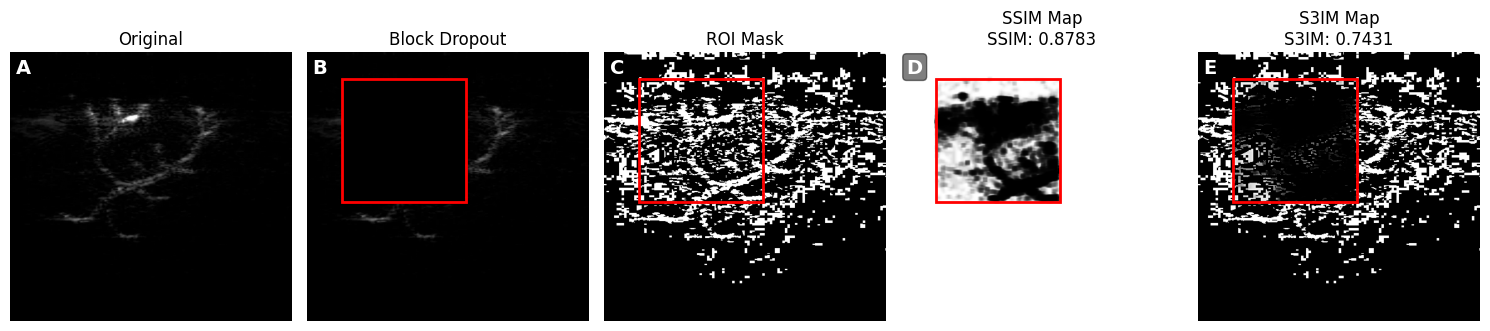

In [23]:
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

# === Load and preprocess ===
with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# === Apply dropout ===
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# === Compute SSIM and S3IM ===
SSIM_score, ssim_map = structural_similarity(
    original_img, block_dropped_img, win_size=7, full=True, data_range=1.0
)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# === Prepare visualization ===
titles = ["Original", "Block Dropout", "ROI Mask", "SSIM Map", "S3IM Map"]
images = [original_img, block_dropped_img, s3im_mask, ssim_map, s3im_map]
labels = ['A', 'B', 'C', 'D', 'E']  # per-image labels

# === Plot ===
fig, axes = plt.subplots(1, 5, figsize=(15, 8))
axes = axes.flatten()

for idx, (ax, title, img, label) in enumerate(zip(axes, titles, images, labels)):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')

    # Add ROI rectangle everywhere except the Original
    if idx != 0:
        rect = Rectangle((x, y), size, size, linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)

    # Put (a)–(e) inside each subplot (top-left)
    ax.text(
        0.02, 0.98, label,
        transform=ax.transAxes,
        color='white',
        fontsize=14,
        fontweight='bold',
        va='top', ha='left',
        bbox=dict(facecolor='black', alpha=0.5, boxstyle='round,pad=0.2')
    )

    # Titles (with metrics where relevant)
    if idx == 3:
        ax.set_title(f"{title}\nSSIM: {SSIM_score:.4f}", fontsize=12)
    elif title == "S3IM Map":
        ax.set_title(f"{title}\nS3IM: {S3IM_score:.4f}", fontsize=12)
    else:
        ax.set_title(title, fontsize=12)

# Hide any unused axes (safety)
if len(images) < len(axes):
    for i in range(len(images), len(axes)):
        axes[i].axis("off")

plt.tight_layout()
plt.show()


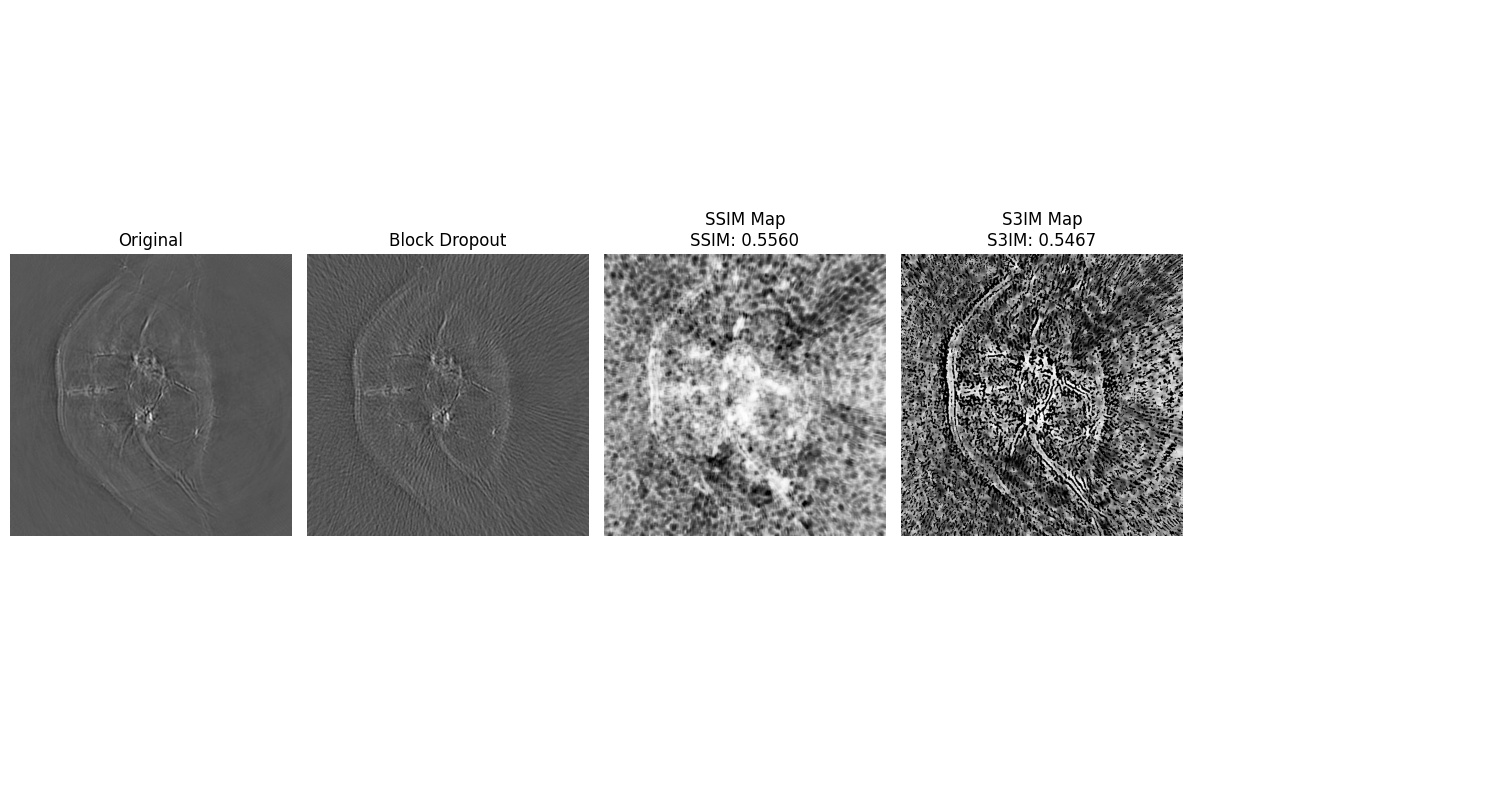

In [24]:
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# Apply dropout
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(original_img, block_dropped_img, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "ROI Mask", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    original_img, 
    block_dropped_img, 
    s3im_mask,
    ssim_map, 
    s3im_map
]

from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_full.webp") as img:
    ref_img = img.convert('L')
    ref_img = img_as_float(ref_img)
    # mask2 = calculate_single_mask(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_128.webp") as img:
    ref_img2 = img.convert('L')
    ref_img2 = img_as_float(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc_BP_slice0046.webp") as img:
    ref_img3 = img.convert('L')
    ref_img3 = img_as_float(ref_img3)
    # mask2 = calculate_single_mask(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc,ss32_BP_slice0046.webp") as img:
    ref_img4 = img.convert('L')
    ref_img4 = img_as_float(ref_img4)
# Apply dropout
# block_dropped_mask = calculate_single_mask(original_img)
# block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(ref_img, ref_img2, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(ref_img, ref_img2, window_size=7)

SSIM_score2, ssim_map2 = structural_similarity(ref_img3, ref_img4, win_size=7, full=True, data_range=1.0)
S3IM_score2, s3im_mask2, s3im_map2 = s3im(ref_img3, ref_img4, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    ref_img,
    ref_img2, 
    ssim_map, 
    s3im_map
]

# Plot in 2 rows (3 cols max)
fig, axes = plt.subplots(1, 5, figsize=(15, 8))
axes = axes.flatten()

for idx, (ax, title, img) in enumerate(zip(axes, titles, images)):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
    if title =="SSIM Map":
        ax.set_title(
            f"""{title}
SSIM: {SSIM_score:.4f}""",
            fontsize=12
        )
    elif title == "S3IM Map":
        ax.set_title(
            f"""{title}
S3IM: {S3IM_score:.4f}""",
            fontsize=12
        )
    else:
        ax.set_title(title, fontsize=12)

# Hide any extra subplot (if 6th is unused)
if len(images) < len(axes):
    for i in range(len(images), len(axes)):
        axes[i].axis("off")

plt.tight_layout()
plt.show()


C:\Users\SemKj\AppData\Local\Temp\ipykernel_3128\514832981.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


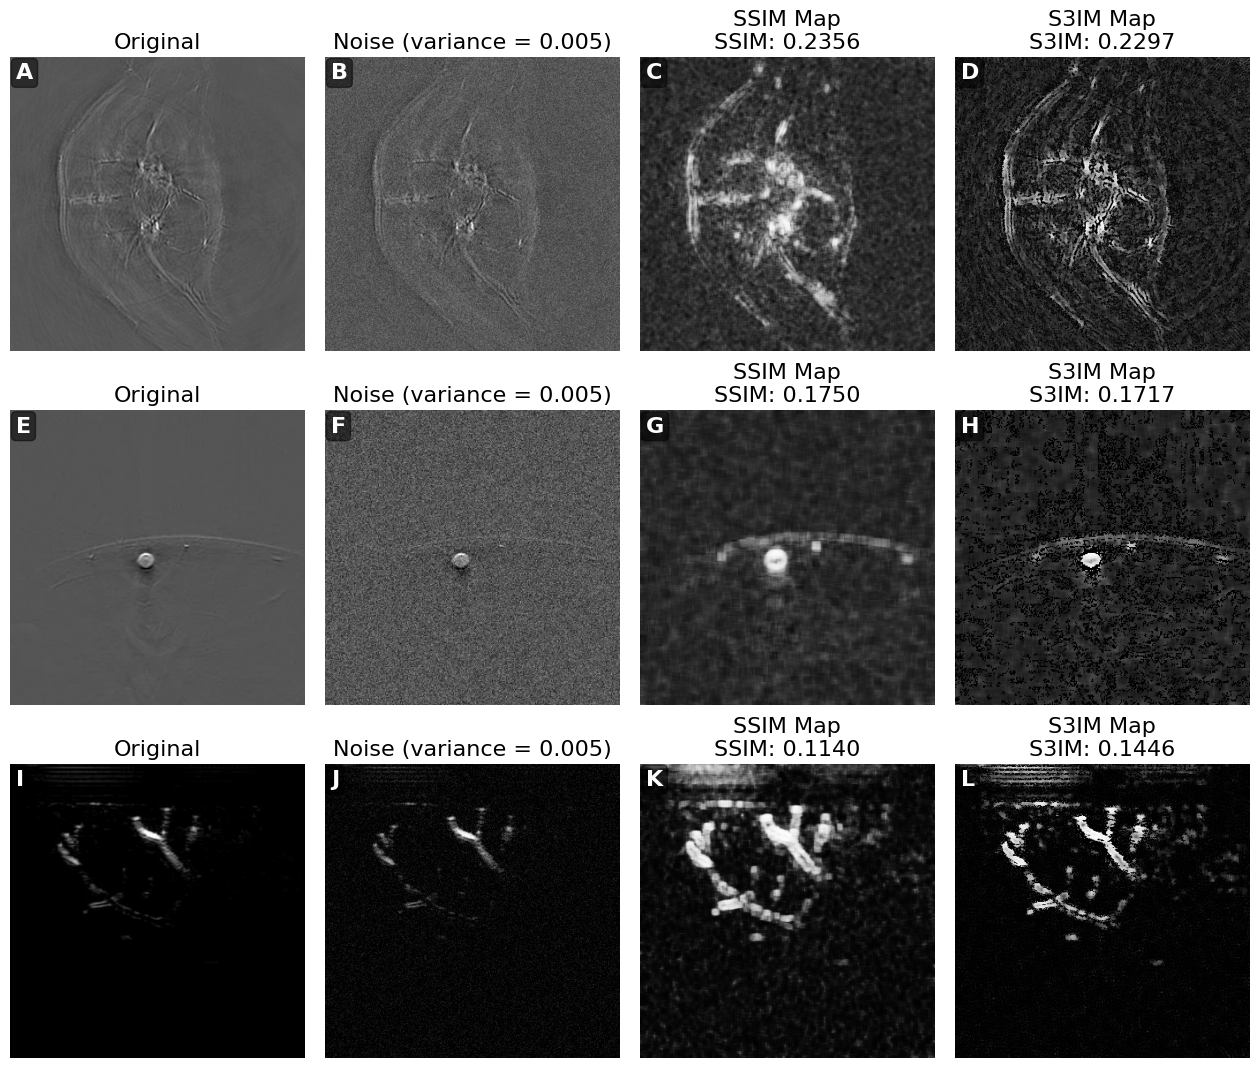

In [25]:
from matplotlib import pyplot as plt
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

# === Load and preprocess images ===
with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_full.webp") as img:
    ref_img = img.convert('L')
    ref_img = img_as_float(ref_img)

ref_img2 = random_noise(ref_img, mode='gaussian', var=0.005, clip=True, rng=42)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc_BP_slice0046.webp") as img:
    ref_img3 = img.convert('L')
    ref_img3 = img_as_float(ref_img3)

ref_img4 = random_noise(ref_img3, mode='gaussian', var=0.005, clip=True, rng=42)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5002/KWave_Rf_102622_011023 PA_GT.webp") as img:
    ref_img5 = img.convert('L')
    ref_img5 = img_as_float(ref_img5)

ref_img6 = random_noise(ref_img5, mode='gaussian', var=0.005, clip=True, rng=42)

# === Compute SSIM and S3IM ===
SSIM_score, ssim_map = structural_similarity(ref_img, ref_img2, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(ref_img, ref_img2, window_size=7)

SSIM_score2, ssim_map2 = structural_similarity(ref_img3, ref_img4, win_size=7, full=True, data_range=1.0)
S3IM_score2, s3im_mask2, s3im_map2 = s3im(ref_img3, ref_img4, window_size=7)

SSIM_score3, ssim_map3 = structural_similarity(ref_img5, ref_img6, win_size=7, full=True, data_range=1.0)
S3IM_score3, s3im_mask3, s3im_map3 = s3im(ref_img5, ref_img6, window_size=7)

# === Prepare visualization ===
titles = ["Original", "Noise (variance = 0.005)", "SSIM Map", "S3IM Map"]

images1 = [ref_img, ref_img2, ssim_map, s3im_map]
scores1 = [None, None, SSIM_score, S3IM_score]

images2 = [ref_img3, ref_img4, ssim_map2, s3im_map2]
scores2 = [None, None, SSIM_score2, S3IM_score2]

images3 = [ref_img5, ref_img6, ssim_map3, s3im_map3]
scores3 = [None, None, SSIM_score3, S3IM_score3]

# Labels (a)–(l)
labels = [f"{chr(97+i)}".upper() for i in range(12)]  # ['(a)', '(b)', ..., '(l)']

# === Create subplot grid: 3 rows × 4 cols ===
fig, axes = plt.subplots(3, 4, figsize=(18, 13), gridspec_kw={'wspace': -0.3, 'hspace': 0.2})

def plot_row(ax_row, titles, imgs, scores, row_labels):
    for idx, (ax, title, img, score, lab) in enumerate(zip(ax_row, titles, imgs, scores, row_labels)):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1, aspect='auto')
        ax.axis("off")
        ax.set_box_aspect(1)  # square subplot cell

        # Per-image label at top-left
        ax.text(
            0.02, 0.98, lab,
            transform=ax.transAxes,
            color='white', fontsize=16, fontweight='bold', va='top', ha='left',
            bbox=dict(facecolor='black', alpha=0.5, boxstyle='round,pad=0.2')
        )

        # Titles (include metric when available)
        if score is not None:
            ax.set_title(f"{title}\n{title.split()[0]}: {score:.4f}", fontsize=16)
        else:
            ax.set_title(title, fontsize=16)

# Plot rows with labels a–d, e–h, i–l
plot_row(axes[0], titles, images1, scores1, labels[0:4])
plot_row(axes[1], titles, images2, scores2, labels[4:8])
plot_row(axes[2], titles, images3, scores3, labels[8:12])

plt.tight_layout()
plt.show()


In [26]:
import matplotlib.pyplot as plt


def visualize_metric_maps(original_img, shifted_img,
                          SSIM_score, ssim_map,
                          cw_ssim_score, cw_ssim_map,
                          ms_ssim_score, ms_ssim_map,
                          S3IM_score, s3im_mask, s3im_map,
                          cw_s3im_score, cw_s3im_map,
                          ms_s3im_score, ms_s3im_map,
                          scene_title=""):
    """Return titles, images, and scores aligned for plotting"""
    titles = [
        "Original", 
        "Shifted", 
        "ROI Mask",
        "SSIM Map",
        "CW-SSIM Map", 
        "MS-SSIM Map",
        "S3IM Map",
        "CW-S3IM Map", 
        "MS-S3IM Map"
    ]
    scores = [
        None, None, None,
        SSIM_score,
        cw_ssim_score,
        ms_ssim_score,
        S3IM_score,
        cw_s3im_score,
        ms_s3im_score,
    ]
    images = [
        original_img,
        shifted_img,
        s3im_mask,
        ssim_map,
        cw_ssim_map,
        ms_ssim_map,
        s3im_map,
        cw_s3im_map,
        ms_s3im_map,
    ]
    return titles, images, scores, scene_title

In [31]:
# import numpy as np
# from scipy.ndimage import shift as scipy_shift
# from scipy.ndimage import rotate

# def shift_image(image: np.ndarray, shift_x: float = 1.0, shift_y: float = 1.0, mode: str = 'nearest') -> np.ndarray:
#     assert np.issubdtype(image.dtype, np.floating), "Image must be of float dtype"
#     assert image.min() >= 0.0 and image.max() <= 1.0, "Image values must be in [0, 1]"

#     # Define shift vector: (y, x) because ndarray is row-major
#     shift_vector = (shift_y, shift_x) if image.ndim == 2 else (shift_y, shift_x, 0)
    
#     shifted = scipy_shift(image, shift=shift_vector, mode=mode, order=1)
    
#     return np.clip(shifted, 0.0, 1.0)

# # Load image
# with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
#     original_img = img.convert('L')
#     original_img = img_as_float(original_img)

# # Apply dropout
# block_dropped_mask = calculate_single_mask(original_img)
# shifted_img = shift_image(original_img, 1, 1)

# cw_ssim_map = cw_ssim(original_img, shifted_img)
# cw_ssim_score = np.average(cw_ssim_map)
# cw_s3im_score, cw_s3im_mask, cw_s3im_map = s3im(original_img, shifted_img, SSIM_variant=cw_ssim)
# # Compute SSIM and S3IM maps
# SSIM_score, ssim_map = structural_similarity(original_img, shifted_img, full=True, data_range=1.0)
# S3IM_score, s3im_mask, s3im_map = s3im(original_img, shifted_img)

# ms_ssim_score, ms_ssim_map = mss3im(original_img, shifted_img, roi=False)
# ms_s3im_score, ms_s3im_map = mss3im(original_img, shifted_img)

# # Prepare visualization
# titles = [
#     "Original", 
#     "Shifted", 
#     "ROI Mask",
#     "SSIM Map",
#     "CW-SSIM Map", 
#     "MS-SSIM Map",
#     "S3IM Map",
#     "CW-S3IM Map", 
#     "MS-S3IM Map"
# ]

# # Collect scores aligned with the maps (None for those without scores)
# scores = [
#     None,  # Original
#     None,  # Shifted (already compared)
#     None,  # ROI Mask
#     SSIM_score,
#     cw_ssim_score,
#     ms_ssim_score,
#     S3IM_score,
#     cw_s3im_score,
#     ms_s3im_score,
# ]

# images = [
#     original_img, 
#     shifted_img,
#     s3im_mask,
#     ssim_map,
#     cw_ssim_map,
#     ms_ssim_map,
#     s3im_map,
#     cw_s3im_map,
#     ms_s3im_map, 
# ]

# viz1 = visualize_metric_maps(
#     original_img, shifted_img,
#     SSIM_score, ssim_map,
#     cw_ssim_score, cw_ssim_map,
#     ms_ssim_score, ms_ssim_map,
#     S3IM_score, s3im_mask, s3im_map,
#     cw_s3im_score, cw_s3im_map,
#     ms_s3im_score, ms_s3im_map,
#     scene_title="Pixel shift"
# )

In [47]:
# def rotate_image(image: np.ndarray, mode: str = 'nearest', angle=2.0):
#     assert np.issubdtype(image.dtype, np.floating), "Image must be of float dtype"
#     assert image.min() >= 0.0 and image.max() <= 1.0, "Image values must be in [0, 1]"

#     # Determine rotation axis for 3D vs 2D
#     axes = (0, 1) if image.ndim == 2 else (0, 1)

#     # scipy.ndimage.rotate preserves shape if reshape=False
#     rotated = rotate(image, angle=angle, axes=axes, reshape=False, mode=mode, order=1)

#     return np.clip(rotated, 0.0, 1.0)

# # Load image
# with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5001/DoranssoPhantom_Rf_101822_211937 PA_GT.webp") as img:
#     original_img = img.convert('L')
#     original_img = img_as_float(original_img)

# # Apply dropout
# block_dropped_mask = calculate_single_mask(original_img)
# shifted_img = rotate_image(original_img)

# cw_ssim_map = cw_ssim(original_img, shifted_img)
# cw_ssim_score = np.average(cw_ssim_map)
# cw_s3im_score, cw_s3im_mask, cw_s3im_map = s3im(original_img, shifted_img, SSIM_variant=cw_ssim)
# # Compute SSIM and S3IM maps
# SSIM_score, ssim_map = structural_similarity(original_img, shifted_img, full=True, data_range=1.0)
# S3IM_score, s3im_mask, s3im_map = s3im(original_img, shifted_img)

# ms_ssim_score, ms_ssim_map = mss3im(original_img, shifted_img, roi=False)
# ms_s3im_score, ms_s3im_map = mss3im(original_img, shifted_img)

# # Prepare visualization
# titles = [
#     "Original", 
#     "Rotated", 
#     "ROI Mask",
#     "SSIM Map",
#     "CW-SSIM Map", 
#     "MS-SSIM Map",
#     "S3IM Map",
#     "CW-S3IM Map", 
#     "MS-S3IM Map"
# ]

# # Collect scores aligned with the maps (None for those without scores)
# scores = [
#     None,  # Original
#     None,  # Shifted (already compared)
#     None,  # ROI Mask
#     SSIM_score,
#     cw_ssim_score,
#     ms_ssim_score,
#     S3IM_score,
#     cw_s3im_score,
#     ms_s3im_score,
# ]

# images = [
#     original_img, 
#     shifted_img,
#     s3im_mask,
#     ssim_map,
#     cw_ssim_map,
#     ms_ssim_map,
#     s3im_map,
#     cw_s3im_map,
#     ms_s3im_map, 
# ]


# viz2 = visualize_metric_maps(
#     original_img, shifted_img,
#     SSIM_score, ssim_map,
#     cw_ssim_score, cw_ssim_map,
#     ms_ssim_score, ms_ssim_map,
#     S3IM_score, s3im_mask, s3im_map,
#     cw_s3im_score, cw_s3im_map,
#     ms_s3im_score, ms_s3im_map,
#     scene_title="Rotation"
# )

In [49]:
# import matplotlib.pyplot as plt

# def visualize_metric_maps(original_img, shifted_img,
#                           SSIM_score, ssim_map,
#                           cw_ssim_score, cw_ssim_map,
#                           ms_ssim_score, ms_ssim_map,
#                           S3IM_score, s3im_mask, s3im_map,
#                           cw_s3im_score, cw_s3im_map,
#                           ms_s3im_score, ms_s3im_map,
#                           scene_title=""):
#     """Return titles, images, and scores aligned for plotting"""
#     titles = [
#         "Original", 
#         "Shifted", 
#         "ROI Mask",
#         "SSIM Map",
#         "CW-SSIM Map", 
#         "MS-SSIM Map",
#         "S3IM Map",
#         "CW-S3IM Map", 
#         "MS-S3IM Map"
#     ]
#     scores = [
#         None, None, None,
#         SSIM_score,
#         cw_ssim_score,
#         ms_ssim_score,
#         S3IM_score,
#         cw_s3im_score,
#         ms_s3im_score,
#     ]
#     images = [
#         original_img,
#         shifted_img,
#         s3im_mask,
#         ssim_map,
#         cw_ssim_map,
#         ms_ssim_map,
#         s3im_map,
#         cw_s3im_map,
#         ms_s3im_map,
#     ]
#     return titles, images, scores, scene_title

# import numpy as np
# from scipy.ndimage import shift as scipy_shift
# from scipy.ndimage import rotate

# def shift_image(image: np.ndarray, shift_x: float = 1.0, shift_y: float = 1.0, mode: str = 'nearest') -> np.ndarray:
#     assert np.issubdtype(image.dtype, np.floating), "Image must be of float dtype"
#     assert image.min() >= 0.0 and image.max() <= 1.0, "Image values must be in [0, 1]"

#     # Define shift vector: (y, x) because ndarray is row-major
#     shift_vector = (shift_y, shift_x) if image.ndim == 2 else (shift_y, shift_x, 0)
    
#     shifted = scipy_shift(image, shift=shift_vector, mode=mode, order=1)
    
#     return np.clip(shifted, 0.0, 1.0)

# # Load image
# with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
#     original_img = img.convert('L')
#     original_img = img_as_float(original_img)

# # Apply dropout
# block_dropped_mask = calculate_single_mask(original_img)
# shifted_img = shift_image(original_img, 1, 1)

# cw_ssim_map = cw_ssim(original_img, shifted_img)
# cw_ssim_score = np.average(cw_ssim_map)
# cw_s3im_score, cw_s3im_mask, cw_s3im_map = s3im(original_img, shifted_img, SSIM_variant=cw_ssim)
# # Compute SSIM and S3IM maps
# SSIM_score, ssim_map = structural_similarity(original_img, shifted_img, full=True, data_range=1.0)
# S3IM_score, s3im_mask, s3im_map = s3im(original_img, shifted_img)

# ms_ssim_score, ms_ssim_map = mss3im(original_img, shifted_img, roi=False)
# ms_s3im_score, ms_s3im_map = mss3im(original_img, shifted_img)

# # Prepare visualization
# titles = [
#     "Original", 
#     "Shifted", 
#     "ROI Mask",
#     "SSIM Map",
#     "CW-SSIM Map", 
#     "MS-SSIM Map",
#     "S3IM Map",
#     "CW-S3IM Map", 
#     "MS-S3IM Map"
# ]

# # Collect scores aligned with the maps (None for those without scores)
# scores = [
#     None,  # Original
#     None,  # Shifted (already compared)
#     None,  # ROI Mask
#     SSIM_score,
#     cw_ssim_score,
#     ms_ssim_score,
#     S3IM_score,
#     cw_s3im_score,
#     ms_s3im_score,
# ]

# images = [
#     original_img, 
#     shifted_img,
#     s3im_mask,
#     ssim_map,
#     cw_ssim_map,
#     ms_ssim_map,
#     s3im_map,
#     cw_s3im_map,
#     ms_s3im_map, 
# ]

# viz1 = visualize_metric_maps(
#     original_img, shifted_img,
#     SSIM_score, ssim_map,
#     cw_ssim_score, cw_ssim_map,
#     ms_ssim_score, ms_ssim_map,
#     S3IM_score, s3im_mask, s3im_map,
#     cw_s3im_score, cw_s3im_map,
#     ms_s3im_score, ms_s3im_map,
#     scene_title="Pixel shift"
# )


# def rotate_image(image: np.ndarray, mode: str = 'nearest', angle=2.0):
#     assert np.issubdtype(image.dtype, np.floating), "Image must be of float dtype"
#     assert image.min() >= 0.0 and image.max() <= 1.0, "Image values must be in [0, 1]"

#     # Determine rotation axis for 3D vs 2D
#     axes = (0, 1) if image.ndim == 2 else (0, 1)

#     # scipy.ndimage.rotate preserves shape if reshape=False
#     rotated = rotate(image, angle=angle, axes=axes, reshape=False, mode=mode, order=1)

#     return np.clip(rotated, 0.0, 1.0)

# # Load image
# with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5001/DoranssoPhantom_Rf_101822_211937 PA_GT.webp") as img:
#     original_img = img.convert('L')
#     original_img = img_as_float(original_img)

# # Apply dropout
# block_dropped_mask = calculate_single_mask(original_img)
# shifted_img = rotate_image(original_img)

# cw_ssim_map = cw_ssim(original_img, shifted_img)
# cw_ssim_score = np.average(cw_ssim_map)
# cw_s3im_score, cw_s3im_mask, cw_s3im_map = s3im(original_img, shifted_img, SSIM_variant=cw_ssim)
# # Compute SSIM and S3IM maps
# SSIM_score, ssim_map = structural_similarity(original_img, shifted_img, full=True, data_range=1.0)
# S3IM_score, s3im_mask, s3im_map = s3im(original_img, shifted_img)

# ms_ssim_score, ms_ssim_map = mss3im(original_img, shifted_img, roi=False)
# ms_s3im_score, ms_s3im_map = mss3im(original_img, shifted_img)

# # Prepare visualization
# titles = [
#     "Original", 
#     "Rotated", 
#     "ROI Mask",
#     "SSIM Map",
#     "CW-SSIM Map", 
#     "MS-SSIM Map",
#     "S3IM Map",
#     "CW-S3IM Map", 
#     "MS-S3IM Map"
# ]

# # Collect scores aligned with the maps (None for those without scores)
# scores = [
#     None,  # Original
#     None,  # Shifted (already compared)
#     None,  # ROI Mask
#     SSIM_score,
#     cw_ssim_score,
#     ms_ssim_score,
#     S3IM_score,
#     cw_s3im_score,
#     ms_s3im_score,
# ]

# images = [
#     original_img, 
#     shifted_img,
#     s3im_mask,
#     ssim_map,
#     cw_ssim_map,
#     ms_ssim_map,
#     s3im_map,
#     cw_s3im_map,
#     ms_s3im_map, 
# ]


# viz2 = visualize_metric_maps(
#     original_img, shifted_img,
#     SSIM_score, ssim_map,
#     cw_ssim_score, cw_ssim_map,
#     ms_ssim_score, ms_ssim_map,
#     S3IM_score, s3im_mask, s3im_map,
#     cw_s3im_score, cw_s3im_map,
#     ms_s3im_score, ms_s3im_map,
#     scene_title="Rotation"
# )

# fig, axes = plt.subplots(3, 6, figsize=(24, 14))  # 3 rows, 6 cols
# axes = axes.reshape(3, 6)

# for col_idx, (titles, images, scores, scene_title) in enumerate([viz1, viz2]):
#     col_offset = col_idx * 3  # left or right block
#     for idx, (title, img, score) in enumerate(zip(titles, images, scores)):
#         row = idx // 3
#         col = idx % 3 + col_offset
#         ax = axes[row, col]
#         ax.imshow(img, cmap='gray', vmin=0, vmax=1)
#         ax.axis('off')
#         if score is not None:
#             ax.set_title(f"{title}\nScore: {score:.4f}", fontsize=11)
#         else:
#             ax.set_title(title, fontsize=11)

#     # Add a big title centered above the block
#     # Use figure coordinates so both blocks get equal space
#     x_center = (col_offset + 1.5) / 6  # center of the 3 columns belonging to this block
#     fig.text(x_center, 0.93, scene_title,
#              ha='center', va='bottom', fontsize=16, fontweight="bold")

# plt.tight_layout(rect=[0, 0, 1, 0.94])  # leave space at top for block titles
# plt.show()

In [50]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.ndimage import shift as scipy_shift
# from scipy.ndimage import rotate
# from PIL import Image as PIL_Image
# from skimage.util import img_as_float

# # assumes you have: calculate_single_mask, structural_similarity, s3im, mss3im

# def visualize_metric_maps(original_img, shifted_img,
#                           SSIM_score, ssim_map,
#                           ms_ssim_score, ms_ssim_map,
#                           S3IM_score, s3im_mask, s3im_map,
#                           ms_s3im_score, ms_s3im_map,
#                           scene_title=""):
#     """Return titles/images/scores WITHOUT the ROI Mask panel."""
#     titles = [
#         "Original",
#         "Shifted" if scene_title == "Pixel shift" else "Rotated",
#         "SSIM Map",
#         "MS-SSIM Map",
#         "S3IM Map",
#         "MS-S3IM Map",
#     ]
#     images = [original_img, shifted_img, ssim_map, ms_ssim_map, s3im_map, ms_s3im_map]
#     scores = [None, None, SSIM_score, ms_ssim_score, S3IM_score, ms_s3im_score]
#     return titles, images, scores, scene_title

# def shift_image(image: np.ndarray, shift_x: float = 1.0, shift_y: float = 1.0, mode: str = 'nearest') -> np.ndarray:
#     assert np.issubdtype(image.dtype, np.floating), "Image must be of float dtype"
#     assert image.min() >= 0.0 and image.max() <= 1.0, "Image values must be in [0, 1]"
#     shift_vector = (shift_y, shift_x) if image.ndim == 2 else (shift_y, shift_x, 0)
#     shifted = scipy_shift(image, shift=shift_vector, mode=mode, order=1)
#     return np.clip(shifted, 0.0, 1.0)

# def rotate_image(image: np.ndarray, mode: str = 'nearest', angle=2.0):
#     assert np.issubdtype(image.dtype, np.floating), "Image must be of float dtype"
#     assert image.min() >= 0.0 and image.max() <= 1.0, "Image values must be in [0, 1]"
#     axes = (0, 1)
#     rotated = rotate(image, angle=angle, axes=axes, reshape=False, mode=mode, order=1)
#     return np.clip(rotated, 0.0, 1.0)

# # ---------- Block 1: Pixel shift ----------
# with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
#     original_img = img.convert('L')
#     original_img = img_as_float(original_img)

# _ = calculate_single_mask(original_img)  # compute if needed elsewhere; not plotted
# shifted_img = shift_image(original_img, 1, 1)

# SSIM_score, ssim_map = structural_similarity(original_img, shifted_img, full=True, data_range=1.0)
# S3IM_score, s3im_mask, s3im_map = s3im(original_img, shifted_img)
# ms_ssim_score, ms_ssim_map = mss3im(original_img, shifted_img, roi=False)
# ms_s3im_score, ms_s3im_map = mss3im(original_img, shifted_img)

# viz1 = visualize_metric_maps(
#     original_img, shifted_img,
#     SSIM_score, ssim_map,
#     ms_ssim_score, ms_ssim_map,
#     S3IM_score, s3im_mask, s3im_map,
#     ms_s3im_score, ms_s3im_map,
#     scene_title="Pixel shift"
# )

# # ---------- Block 2: Rotation ----------
# with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5001/DoranssoPhantom_Rf_101822_211937 PA_GT.webp") as img:
#     original_img = img.convert('L')
#     original_img = img_as_float(original_img)

# _ = calculate_single_mask(original_img)  # compute if needed; not plotted
# shifted_img = rotate_image(original_img)

# SSIM_score, ssim_map = structural_similarity(original_img, shifted_img, full=True, data_range=1.0)
# S3IM_score, s3im_mask, s3im_map = s3im(original_img, shifted_img)
# ms_ssim_score, ms_ssim_map = mss3im(original_img, shifted_img, roi=False)
# ms_s3im_score, ms_s3im_map = mss3im(original_img, shifted_img)

# viz2 = visualize_metric_maps(
#     original_img, shifted_img,
#     SSIM_score, ssim_map,
#     ms_ssim_score, ms_ssim_map,
#     S3IM_score, s3im_mask, s3im_map,
#     ms_s3im_score, ms_s3im_map,
#     scene_title="Rotation"
# )

# # --- Resize second block to match first block’s image shape (if needed) ---
# try:
#     from skimage.transform import resize as _resize
#     def _rescale(img, target_shape, is_mask=False):
#         return np.clip(
#             _resize(img, target_shape, order=1, mode='edge', anti_aliasing=True, preserve_range=True),
#             0.0, 1.0
#         )
# except Exception:
#     from scipy.ndimage import zoom as _zoom
#     def _rescale(img, target_shape, is_mask=False):
#         zoom_factors = (target_shape[0] / img.shape[0], target_shape[1] / img.shape[1])
#         return np.clip(_zoom(img, zoom_factors, order=1, mode='nearest'), 0.0, 1.0)

# def resize_block_to(viz_block, target_shape):
#     titles, images, scores, scene_title = viz_block
#     out_images = [ _rescale(img, target_shape, is_mask=False) if img is not None else None
#                    for img in images ]
#     return (titles, out_images, scores, scene_title)

# target_shape = viz1[1][0].shape
# viz2 = resize_block_to(viz2, target_shape)

# # --- Panel labeling helper ---
# import string
# def _panel_label(idx):
#     letters = string.ascii_uppercase
#     s = ""
#     n = idx
#     while True:
#         s = letters[n % 26] + s
#         n = n // 26 - 1
#         if n < 0:
#             break
#     return s

# # ---------- Plot (two 2-column blocks → 3 × 4 grid) ----------
# fig, axes = plt.subplots(3, 4, figsize=(14, 12))
# axes = np.asarray(axes)

# # Hide everything first
# for ax in axes.ravel():
#     ax.set_visible(False)

# # For each block (left: columns 0–1, right: columns 2–3),
# # we place 6 panels in positions below (row-major within the block):
# # (0,0) (0,1)
# # (1,0) (1,1)
# # (2,0) (2,1)
# positions_in_block = [(0,0), (0,1), (1,0), (1,1), (2,0), (2,1)]

# panel_idx = 0

# for block_idx, (titles, images, scores, scene_title) in enumerate([viz1, viz2]):
#     col_offset = block_idx * 2  # 0 or 2

#     for (title, img, score), (r, c) in zip(zip(titles, images, scores), positions_in_block):
#         ax = axes[r, c + col_offset]
#         ax.set_visible(True)
#         ax.imshow(img, cmap='gray', vmin=0, vmax=1)
#         ax.axis('off')

#         # Title with metric where available
#         if score is not None:
#             ax.set_title(f"{title}\nScore: {score:.4f}", fontsize=14)
#         else:
#             ax.set_title(title, fontsize=14)

#         # Panel label (A, B, C, ...) in top-left
#         label = _panel_label(panel_idx)
#         ax.text(0.02, 0.98, label, transform=ax.transAxes,
#                 ha='left', va='top', fontsize=14, fontweight='bold',
#                 bbox=dict(facecolor='white', edgecolor='none', alpha=0.6, boxstyle='square,pad=0.15'))
#         panel_idx += 1

#     # Block title centered above its 2 columns
#     x_center = (col_offset + 1) / 4.0
#     fig.text(x_center, 0.93, scene_title, ha='center', va='bottom',
#              fontsize=16, fontweight='bold')

# plt.tight_layout(rect=[0, 0, 1, 0.94])
# plt.show()



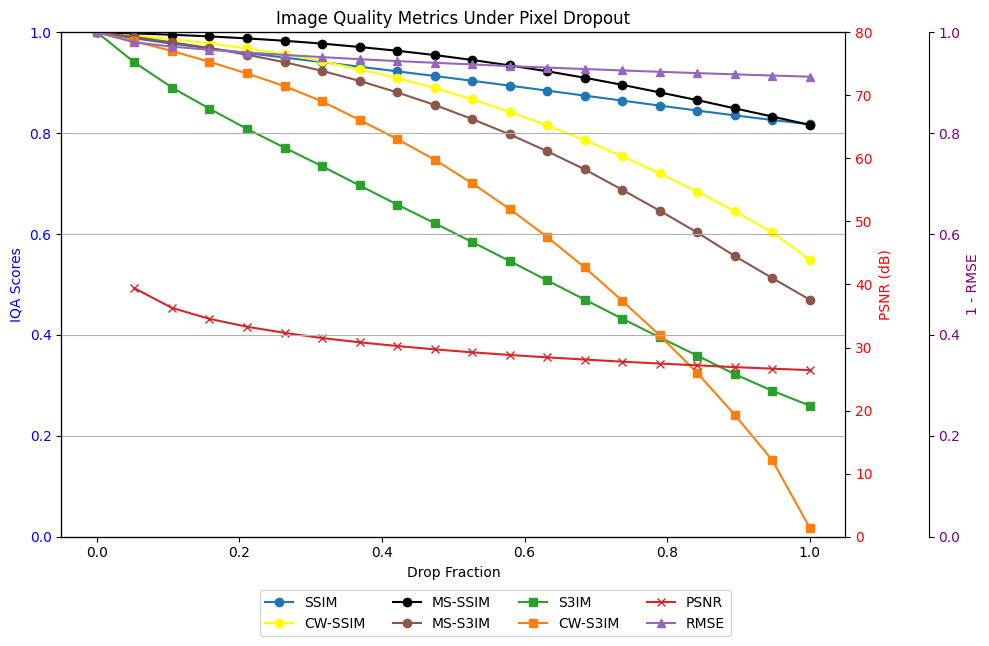

In [27]:
plot_results_and_calculate_kendall(
    levels=drop_fractions,
    avg_ssim_scores=avg_scores_drop['ssim'],
    avg_wssim_scores=avg_scores_drop['wssim'],
    avg_msssim_scores=avg_scores_drop['msssim'],
    avg_s3im_scores=avg_scores_drop['s3im'],
    avg_ws3im_scores=avg_scores_drop['ws3im'],
    avg_mss3im_scores=avg_scores_drop['mss3im'],
    avg_mse_scores=avg_scores_drop['mse'],
    avg_psnr_scores=avg_scores_drop['psnr'],
    distortion_type="Pixel Dropout",
    distortion_level="Drop Fraction"
)

In [52]:
# plot_results_snr_based(
#     snr_linear_levels=avg_scores_noise['snr'],
#     avg_ssim_scores=avg_scores_noise['ssim'],
#     avg_wssim_scores=avg_scores_noise['wssim'],
#     avg_msssim_scores=avg_scores_noise['msssim'],
#     avg_s3im_scores=avg_scores_noise['s3im'],
#     avg_ws3im_scores=avg_scores_noise['ws3im'],
#     avg_mss3im_scores=avg_scores_noise['mss3im'],
#     avg_mse_scores=avg_scores_noise['mse'],
#     avg_psnr_scores=avg_scores_noise['psnr'],
#     distortion_type="Noise applied to whole image",
#     distortion_level="Signal to Noise ratio"
# )

# plot_results_snr_based(
#     snr_linear_levels=avg_scores_noise_inside['snr'],
#     avg_ssim_scores=avg_scores_noise_inside['ssim'],
#     avg_wssim_scores=avg_scores_noise_inside['wssim'],
#     avg_msssim_scores=avg_scores_noise_inside['msssim'],
#     avg_s3im_scores=avg_scores_noise_inside['s3im'],
#     avg_ws3im_scores=avg_scores_noise_inside['ws3im'],
#     avg_mss3im_scores=avg_scores_noise_inside['mss3im'],
#     avg_mse_scores=avg_scores_noise_inside['mse'],
#     avg_psnr_scores=avg_scores_noise_inside['psnr'],
#     distortion_type="Noise applied inside ROI",
#     distortion_level="Signal to Noise ratio"
# )

# plot_results_snr_based(
#     snr_linear_levels=avg_scores_noise_outside['snr'],
#     avg_ssim_scores=avg_scores_noise_outside['ssim'],
#     avg_wssim_scores=avg_scores_noise_outside['wssim'],
#     avg_msssim_scores=avg_scores_noise_outside['msssim'],
#     avg_s3im_scores=avg_scores_noise_outside['s3im'],
#     avg_ws3im_scores=avg_scores_noise_outside['ws3im'],
#     avg_mss3im_scores=avg_scores_noise_outside['mss3im'],
#     avg_mse_scores=avg_scores_noise_outside['mse'],
#     avg_psnr_scores=avg_scores_noise_outside['psnr'],
#     distortion_type="Noise applied outside ROI",
#     distortion_level="Signal to Noise ratio"
# )

In [53]:
# plot_results_and_calculate_kendall(
#     levels=blur_levels,
#     avg_ssim_scores=avg_scores_blur['ssim'],
#     avg_wssim_scores=avg_scores_blur['wssim'],
#     avg_msssim_scores=avg_scores_blur['msssim'],
#     avg_s3im_scores=avg_scores_blur['s3im'],
#     avg_ws3im_scores=avg_scores_blur['ws3im'],
#     avg_mss3im_scores=avg_scores_blur['mss3im'],
#     avg_mse_scores=avg_scores_blur['mse'],
#     avg_psnr_scores=avg_scores_blur['psnr'],
#     distortion_type="Blur Whole Image",
#     distortion_level="Sigma"
# )

# plot_results_and_calculate_kendall(
#     levels=blur_levels,
#     avg_ssim_scores=avg_scores_blur_inside['ssim'],
#     avg_wssim_scores=avg_scores_blur_inside['wssim'],
#     avg_msssim_scores=avg_scores_blur_inside['msssim'],
#     avg_s3im_scores=avg_scores_blur_inside['s3im'],
#     avg_ws3im_scores=avg_scores_blur_inside['ws3im'],
#     avg_mss3im_scores=avg_scores_blur_inside['mss3im'],
#     avg_mse_scores=avg_scores_blur_inside['mse'],
#     avg_psnr_scores=avg_scores_blur_inside['psnr'],
#     distortion_type="Blur Inside ROI",
#     distortion_level="Sigma"
# )

# plot_results_and_calculate_kendall(
#     levels=blur_levels,
#     avg_ssim_scores=avg_scores_blur_outside['ssim'],
#     avg_wssim_scores=avg_scores_blur_outside['wssim'],
#     avg_msssim_scores=avg_scores_blur_outside['msssim'],
#     avg_s3im_scores=avg_scores_blur_outside['s3im'],
#     avg_ws3im_scores=avg_scores_blur_outside['ws3im'],
#     avg_mss3im_scores=avg_scores_blur_outside['mss3im'],
#     avg_mse_scores=avg_scores_blur_outside['mse'],
#     avg_psnr_scores=avg_scores_blur_outside['psnr'],
#     distortion_type="Blur Outside ROI",
#     distortion_level="Sigma"
# )

In [54]:
# avg_ssim_scores_PA = []
# avg_wssim_scores_PA = []
# avg_msssim_scores_PA = []
# avg_s3im_scores_PA = []
# avg_mss3im_scores_PA = []
# avg_ws3im_scores_PA = []

# avg_mse_scores_PA = []
# avg_psnr_scores_PA = []
# avg_snr_scores_PA = []

# ssim_scores_PA = []
# wssim_scores_PA = []
# msssim_scores_PA = []
# s3im_scores_PA = []
# mss3im_scores_PA = []
# ws3im_scores_PA = []

# PA_scores_per_item = {key: {
#     "ssim": [],
#     "wssim": [],
#     "msssim": [],
#     "s3im": [],
#     "mss3im": [],
#     "ws3im": []
# } for key in PA_from_base.keys()}

# PA_scores = {
#     "ssim": dict(), # {0: [0.68, 0.66, ...], 0: [0.68, 0.66, ...], ...} (0-19)
#     "wssim": dict(),
#     "msssim": dict(),
#     "s3im": dict(),
#     "mss3im": dict(),
#     "ws3im": dict()
# }
# PA_levels = [1, 7, 6, 5, 4, 3, 2]
# for i, level in enumerate(PA_levels):
#     ssim_scores = []
#     msssim_scores = []
#     wssim_scores = []
#     s3im_scores = []
#     mss3im_scores = []
#     ws3im_scores = []
#     mse_scores = []
#     psnr_scores = []
#     snr_scores = []

#     for key, img in PA_from_base.items():
#         ssim_score = structural_similarity(img["PA1"], img[f"PA{level}"], data_range=1.0)
#         msssim_score = msssim(img["PA1"], img[f"PA{level}"])
#         wssim_score = np.average(cw_ssim(img["PA1"], img[f"PA{level}"]))

#         s3im_score, _, _ = s3im(img["PA1"], img[f"PA{level}"], SSIM_variant=structural_similarity)
#         mss3im_score, _ = mss3im(img["PA1"], img[f"PA{level}"])
#         ws3im_score, _, _ = s3im(img["PA1"], img[f"PA{level}"], SSIM_variant=cw_ssim)

#         mse_score = mean_squared_error(img["PA1"], img[f"PA{level}"])
#         psnr_score = peak_signal_noise_ratio(img["PA1"], img[f"PA{level}"], data_range=1.0) if mse_score != 0 else np.nan
#         snr_score = snr_reference(img["PA1"], img[f"PA{level}"])

#         ssim_scores.append(ssim_score)
#         wssim_scores.append(wssim_score)
#         msssim_scores.append(msssim_score)

#         mss3im_scores.append(mss3im_score)
#         s3im_scores.append(s3im_score)
#         ws3im_scores.append(ws3im_score)

#         mse_scores.append(mse_score)
#         psnr_scores.append(psnr_score)
#         snr_scores.append(snr_score)

#         PA_scores_per_item[key]["ssim"].append(ssim_score)
#         PA_scores_per_item[key]["msssim"].append(msssim_score)
#         PA_scores_per_item[key]["wssim"].append(wssim_score)

#         PA_scores_per_item[key]["s3im"].append(s3im_score)
#         PA_scores_per_item[key]["mss3im"].append(mss3im_score)
#         PA_scores_per_item[key]["ws3im"].append(ws3im_score)

#     PA_scores["ssim"][i] = ssim_scores
#     PA_scores["s3im"][i] = s3im_scores

#     PA_scores["wssim"][i] = wssim_scores
#     PA_scores["ws3im"][i] = ws3im_scores

#     PA_scores["msssim"][i] = msssim_scores
#     PA_scores["mss3im"][i] = mss3im_scores

#     avg_ssim_scores_PA.append(np.mean(ssim_scores))
#     avg_wssim_scores_PA.append(np.mean(wssim_scores))
#     avg_msssim_scores_PA.append(np.mean(msssim_scores))

#     avg_s3im_scores_PA.append(np.mean(s3im_scores))
#     avg_ws3im_scores_PA.append(np.mean(ws3im_scores))
#     avg_mss3im_scores_PA.append(np.mean(mss3im_scores))

#     avg_mse_scores_PA.append(np.mean(mse_scores))
#     avg_psnr_scores_PA.append(np.mean(psnr_scores))
#     avg_snr_scores_PA.append(np.mean(snr_scores))

# taus_ssim = []
# taus_msssim = []
# taus_wssim = []
# taus_s3im = []
# taus_mss3im = []
# taus_ws3im = []

# distortion_levels = [1, 2, 3, 4, 5, 6, 7]
# for key, val in PA_scores_per_item.items():
#     ssim_score, ssim_p = kendalltau(distortion_levels, val["ssim"])
#     msssim_score, msssim_p = kendalltau(distortion_levels, val["msssim"])
#     wssim_score, wssim_p = kendalltau(distortion_levels, val["wssim"])

#     s3im_score, s3im_p = kendalltau(distortion_levels, val["s3im"])
#     mss3im_score, mss3im_p = kendalltau(distortion_levels, val["mss3im"])
#     ws3im_score, ws3im_p = kendalltau(distortion_levels, val["ws3im"])

#     taus_ssim.append(ssim_score)
#     taus_msssim.append(msssim_score)
#     taus_wssim.append(wssim_score)
#     taus_s3im.append(s3im_score)
#     taus_mss3im.append(mss3im_score)
#     taus_ws3im.append(ws3im_score)

# # Compute averages
# avg_tau_ssim = np.mean(taus_ssim)
# avg_tau_msssim = np.mean(taus_msssim)
# avg_tau_wssim = np.mean(taus_wssim)
# avg_tau_s3im = np.mean(taus_s3im)
# avg_tau_mss3im = np.mean(taus_mss3im)
# avg_tau_ws3im = np.mean(taus_ws3im)

# print("PA:")
# print(f"Average Kendall's tau (SSIM): {avg_tau_ssim:.3f}")
# print(f"Average Kendall's tau (MSSSIM): {avg_tau_msssim:.3f}")
# print(f"Average Kendall's tau (WSSIM): {avg_tau_wssim:.3f}")
# print(f"Average Kendall's tau (S3IM): {avg_tau_s3im:.3f}")
# print(f"Average Kendall's tau (MSS3IM): {avg_tau_mss3im:.3f}")
# print(f"Average Kendall's tau (WS3IM): {avg_tau_ws3im:.3f}")

In [28]:
im = PA_from_base['Small Animal__Tumor_Rf_110720_005952']['PA1']
im2 = PA_from_base['Small Animal__Tumor_Rf_110720_005952']['PA4']
plot_single_row_match_image_height(
    original_img=im,
    distorted_img=im2,
    x_levels=avg_scores_noise['snr'],
    avg_scores=avg_scores_noise,
    xlabel="Signal-to-Noise Ratio (linear)",
    title_curves="Noise — Metrics vs SNR (higher is cleaner)",
    compute_metrics_fn=compute_metrics,
    width_ratio=(2.4, 2.8),
    invert_x=True,
    start_label= 'A'
)

NameError: name 'plot_single_row_match_image_height' is not defined

In [56]:
# plot_results_snr_based(
#     snr_linear_levels=avg_snr_scores_PA[1:],
#     avg_ssim_scores=avg_ssim_scores_PA[1:],
#     avg_wssim_scores=avg_wssim_scores_PA[1:],
#     avg_msssim_scores=avg_msssim_scores_PA[1:],
#     avg_s3im_scores=avg_s3im_scores_PA[1:],
#     avg_ws3im_scores=avg_ws3im_scores_PA[1:],
#     avg_mss3im_scores=avg_mss3im_scores_PA[1:],
#     avg_mse_scores=avg_mse_scores_PA[1:],
#     avg_psnr_scores=avg_psnr_scores_PA[1:],
#     distortion_type="PA level"
# )

In [29]:
with PIL_Image.open("Ground_Truth.tif") as img:
    GT = img.convert('L')
    GT = img_as_float(GT)

with PIL_Image.open("Experiment_Water.tif") as img:
    WATER = img.convert('L')
    WATER = img_as_float(WATER)

with PIL_Image.open("Experiment_Phantom.tif") as img:
    PHANTOM = img.convert('L')
    PHANTOM = img_as_float(PHANTOM)

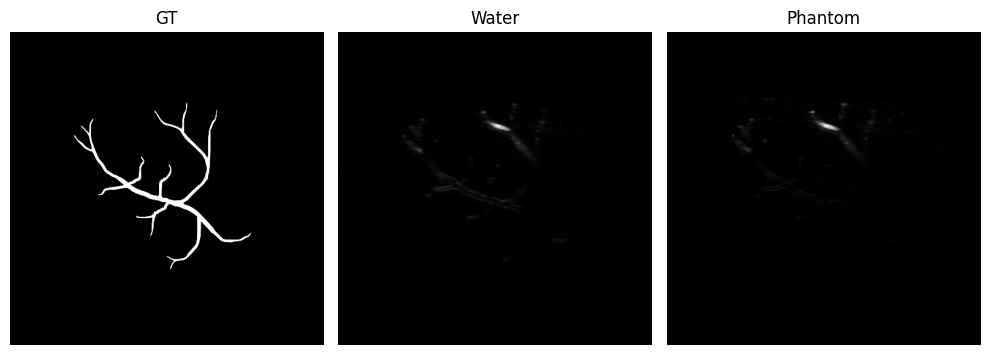

phantom
tensor(0.1114)


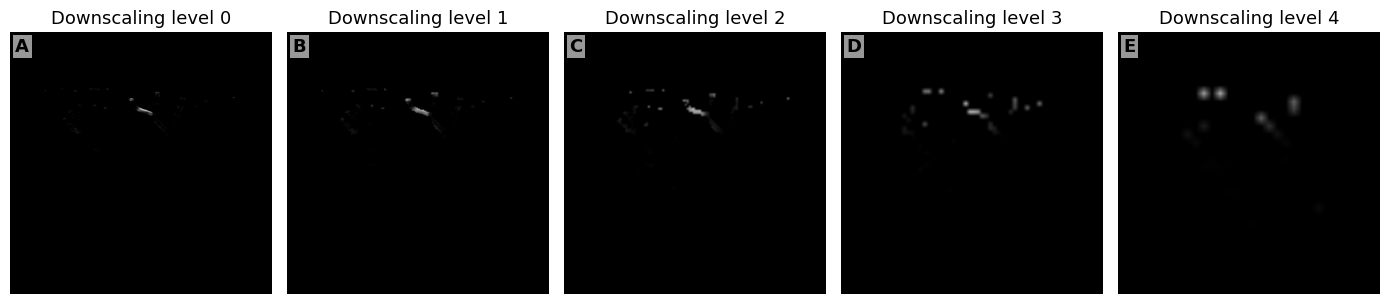

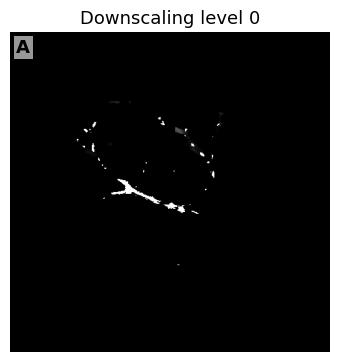

water
tensor(0.0992)


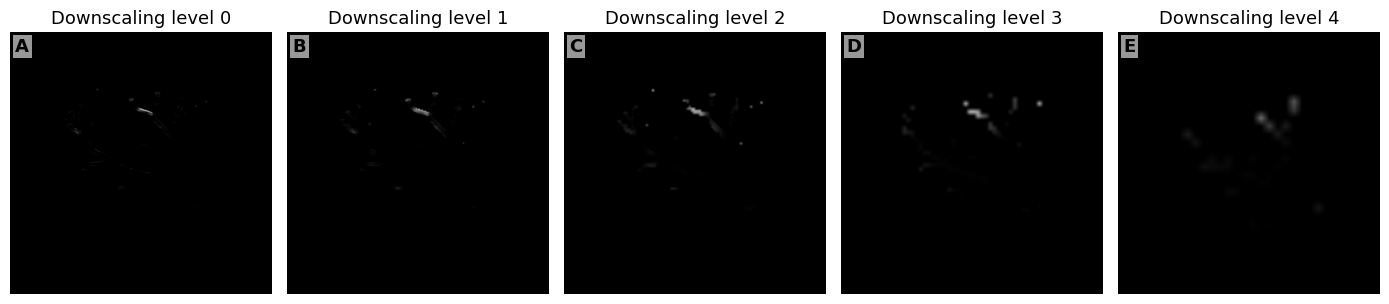

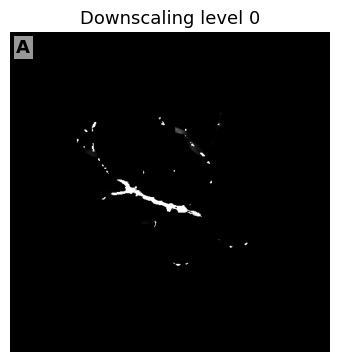

0.812897112674028


(0.8615616626631073,
 array([[1.        , 1.        , 1.        , ..., 1.        , 1.        ,
         1.        ],
        [0.99999968, 0.99999968, 0.99999968, ..., 1.        , 1.        ,
         1.        ],
        [0.99999206, 0.9999913 , 0.99999032, ..., 1.        , 1.        ,
         1.        ],
        ...,
        [1.        , 1.        , 1.        , ..., 1.        , 1.        ,
         1.        ],
        [1.        , 1.        , 1.        , ..., 1.        , 1.        ,
         1.        ],
        [1.        , 1.        , 1.        , ..., 1.        , 1.        ,
         1.        ]]))

In [30]:
from skimage.io import imread
from skimage.util import img_as_float

GT = img_as_float(imread("Ground_Truth.tif"))
WATER = img_as_float(imread("Experiment_Water.tif"))
PHANTOM = img_as_float(imread("Experiment_Phantom.tif"))

    
fig, axes = plt.subplots(1, 3, figsize=(10, 5))

axes[0].imshow(GT, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("GT")
axes[0].axis('off')

axes[1].imshow(WATER, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Water")
axes[1].axis('off')

axes[2].imshow(PHANTOM, cmap='gray', vmin=0, vmax=1)
axes[2].set_title("Phantom")
axes[2].axis('off')

plt.tight_layout()
plt.show()



def visualize_maps(maps, titles=None, scores=None, cmap='gray', figsize=(14, 4), ncols=5, scene_title=""):
    import string

    import matplotlib.pyplot as plt
    import numpy as np

    n = len(maps)
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)

    if titles is None:
        titles = [f"Downscaling level {i}" for i in range(n)]
    if scores is None:
        scores = [None] * n

    # Hide any extra axes
    for ax in axes[n:]:
        ax.set_visible(False)

    for idx, (img, title, score) in enumerate(zip(maps, titles, scores)):
        ax = axes[idx]

        # ✅ Fix: squeeze singleton dimensions like (1,1,H,W) → (H,W)
        img = np.squeeze(img)

        ax.imshow(img, cmap=cmap, vmin=0, vmax=1)
        ax.axis('off')

        # Title + optional score
        if score is not None:
            ax.set_title(f"{title}\nScore: {score:.4f}", fontsize=13)
        else:
            ax.set_title(title, fontsize=13)

        # Add panel label (A, B, C, …)
        label = string.ascii_uppercase[idx]
        ax.text(0.02, 0.98, label, transform=ax.transAxes,
                ha='left', va='top', fontsize=13, fontweight='bold',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.6, boxstyle='square,pad=0.15'))
    
        # print(img.mean())

    if scene_title:
        fig.text(0.5, 0.95, scene_title, ha='center', va='bottom',
                 fontsize=15, fontweight='bold')

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()


res_phantom = mss3im(GT, PHANTOM)
maps_phantom = res_phantom[2]
res_water = mss3im(GT, WATER)
maps_water = res_water[2]

print('phantom')
print(res_phantom[0])
visualize_maps(maps_phantom)
visualize_maps([res_phantom[1]])

print('water')
print(res_water[0])
visualize_maps(maps_water)
visualize_maps([res_water[1]])


s3im_score, _, _ = s3im(GT, WATER, SSIM_variant=structural_similarity)

print(s3im_score)

structural_similarity(GT, PHANTOM,win_size=7, full=True, data_range=1.0)
structural_similarity(GT, WATER,win_size=7, full=True, data_range=1.0)

# mss3im(GT, WATER, roi=False)[0]
# mss3im(GT, PHANTOM, roi=False)[0]

In [32]:
import matplotlib


def visualize_multiple_masks(image, masks, titles, alpha=0.6):
    """
    Display the original image with multiple mask overlays side-by-side.
    
    Args:
        image: Grayscale image (2D array)
        masks: List of masks (boolean 2D arrays)
        titles: List of titles (one per mask)
        alpha: Transparency level for the mask overlay
    """
    n = len(masks)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if (type(axes) == matplotlib.axes._axes.Axes):
        axes = [axes]
    for ax, mask, title in zip(axes, masks, titles):
        rgb_image = np.stack([image, image, image], axis=-1)
        overlay = rgb_image.copy()
        overlay[mask] = [1, 0, 0]  # Red where masked
        blended = (1 - alpha) * rgb_image + alpha * overlay

        ax.imshow(blended)
        ax.set_title(title, fontsize=32)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

def visualize_mask_overlay(image, mask, alpha=0.6, title="S3IM Mask Overlay"):
    # Create an RGB version of the grayscale image
    rgb_image = np.stack([image, image, image], axis=-1)

    # Create red overlay where mask == True
    overlay = rgb_image.copy()
    overlay[mask] = [1, 0, 0]  # Bright Red where mask is True

    # Blend the two images
    blended = (1 - alpha) * rgb_image + alpha * overlay

    plt.figure(figsize=(6, 6))
    plt.imshow(blended)
    plt.title(title)
    plt.axis('off')
    plt.show()

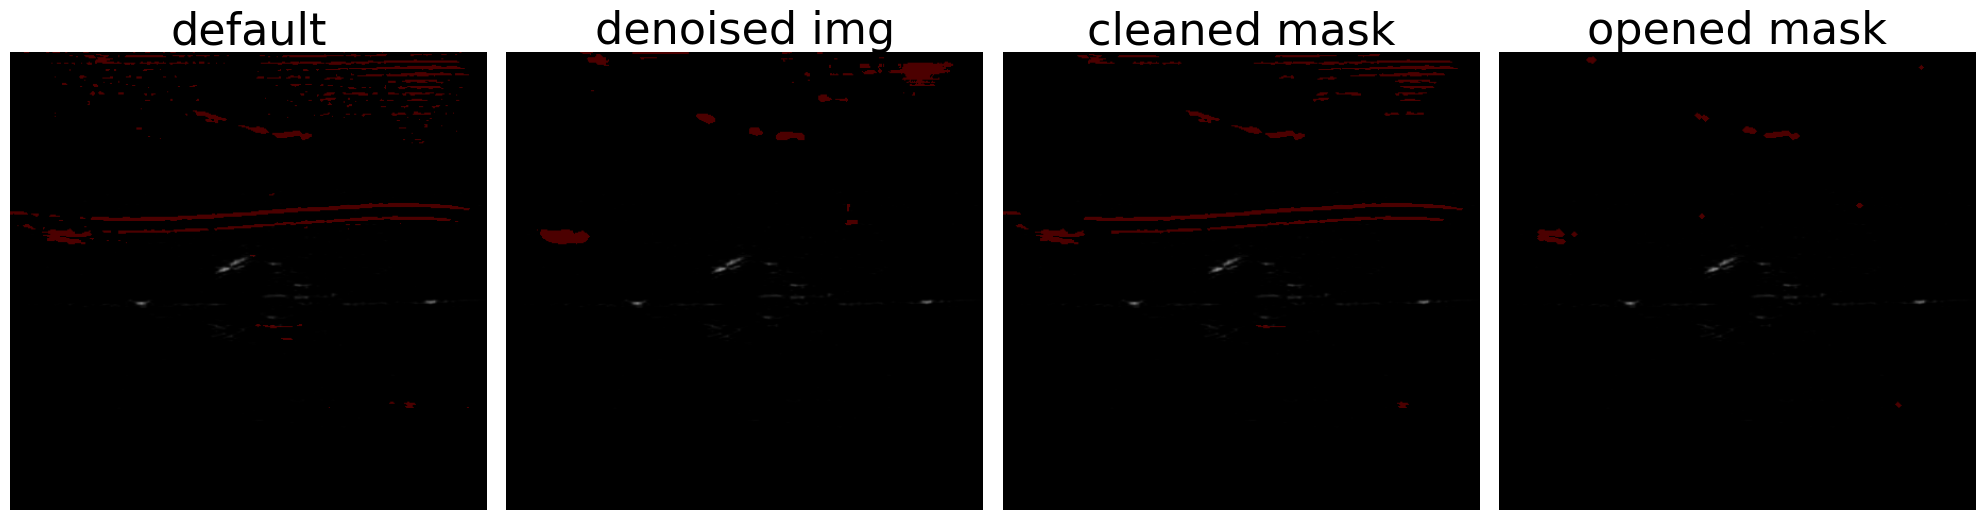

In [36]:
from scipy.ndimage import median_filter
from skimage.morphology import binary_opening, disk, remove_small_objects

default_mask = calculate_combined_mask(greyscaleImages[5], greyscaleImages[5], sensitivity=0.45)

# denoised img
img_denoised = median_filter(greyscaleImages[5], size=12)
denoised_mask = calculate_combined_mask(img_denoised, img_denoised, sensitivity=0.48)

mask_clean = remove_small_objects(default_mask, min_size=24)

mask_opened = binary_opening(default_mask, disk(2))

masks = [default_mask, denoised_mask, mask_clean, mask_opened]
# images = [greyscaleImages[0], greyscaleImages[0], greyscaleImages[0], greyscaleImages[0]]
titles = ["default", "denoised img", "cleaned mask", "opened mask"]

visualize_multiple_masks(greyscaleImages[0], masks, titles, 0.3)

In [37]:
import matplotlib.pyplot as plt
import numpy as np
from skimage.io import imread


def calculate_and_visualise_masks(img1, img2):
    mask_local = calculate_combined_mask(img1, img2)

    mask1 = bernsen(img1, radius=3, contrast_threshold=20)
    mask2 = bernsen(img2, radius=3, contrast_threshold=20)
    mask_bernsen = np.logical_or(mask1, mask2)

    thresh1 = threshold_otsu(img1)
    thresh2 = threshold_otsu(img2)
    mask1 = img1 > thresh1
    mask2 = img2 > thresh2
    mask_otsu = np.logical_or(mask1, mask2)

    visualize_multiple_masks(img2, [mask_local*0, mask_local, mask_bernsen, mask_otsu], alpha=0.3, titles=["Original", "AGT",  "Bernsen", "Otsu"])
    

In [38]:
# [VARIED SPLIT CONTENTS]
#   [Mouse Phantom]
#     22xx Mice x10 IN VIVO
#     23xx Phantom - 3 Circles x4 PHANTOM
#   [OADAT]
#     32xx SWFD_sc SEMICIRCLE x10 IN VIVO
#     33xx SWFD_ms MULTISEGMENT x10 IN VIVO
#   [ACOUSTICX]
#     50xx KWave x2 PHANTOM
#     50xx Doransso Phantom x1 PHANTOM
#     50xx BMPI Phantom x1 PHANTOM 
#     50xx BV Phantom x1 PHANTOM
#     51xx Wrist x1 IN VIVO
#     51xx Radial x1 IN VIVO
#     51xx Finger x1 IN VIVO
#   [VISUALSONICS]
#     6xxx Bladder x1 IN VIVO
#     6xxx Brain x1 IN VIVO
#     6xxx Hindlimb x1 IN VIVO
#     6xxx Kidney x1 IN VIVO
#     6xxx Liver x1 IN VIVO

oimg1 = PA_from_base["Invivo__BloodvesselDepth_Rf_061821_180645"]["PA1"]
oimg2 = PA_from_base["Invivo__BloodvesselDepth_Rf_061821_180645"]["PA7"]
# calculate_and_visualise_masks(img1, img2)

oimg3 = PA_from_base["Invivo__BloodvesselDepth_Rf_061821_180645"]["PA2"]
# calculate_and_visualise_masks(img1, img2)

#   [Mouse Phantom]
#     22xx Mice x10 IN VIVO
#     23xx Phantom - 3 Circles x4 PHANTOM
print("[Mouse Phantom]")
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_2201/image_113_full.webp") as img:
        img1 = img.convert('L')
        img1 = img_as_float(img1)
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_2201/image_113_256.webp") as img:
        img2 = img.convert('L')
        img2 = img_as_float(img2)
# calculate_and_visualise_masks(img1, img2)

with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_2201/image_113_16.webp") as img:
        img3 = img.convert('L')
        img3 = img_as_float(img2)
# calculate_and_visualise_masks(img1, img2)

#   [OADAT]
#     32xx SWFD_sc SEMICIRCLE x10 IN VIVO
#     33xx SWFD_ms MULTISEGMENT x10 IN VIVO
print("[OADAT]")
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_3203/SWFD_semicircle_sc_BP_slice0090.webp") as img:
        aimg1 = img.convert('L')
        aimg1 = img_as_float(aimg1)
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_3203/SWFD_semicircle_sc,lv128_BP_slice0090.webp") as img:
        aimg2 = img.convert('L')
        aimg2 = img_as_float(aimg2)
# calculate_and_visualise_masks(img1, img2)

with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_3203/SWFD_semicircle_sc,ss32_BP_slice0090.webp") as img:
        aimg3 = img.convert('L')
        aimg3 = img_as_float(aimg2)
# calculate_and_visualise_masks(img1, img2)


#   [ACOUSTICX]
#     50xx KWave x2 PHANTOM
#     50xx Doransso Phantom x1 PHANTOM
#     50xx BMPI Phantom x1 PHANTOM 
#     50xx BV Phantom x1 PHANTOM
#     51xx Wrist x1 IN VIVO
#     51xx Radial x1 IN VIVO
#     51xx Finger x1 IN VIVO
print("[ACOUSTICX]")
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
        bimg1 = img.convert('L')
        bimg1 = img_as_float(bimg1)
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA7.webp") as img:
        bimg2 = img.convert('L')
        bimg2 = img_as_float(bimg2)
# calculate_and_visualise_masks(img1, img2)

with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA2.webp") as img:
        bimg3 = img.convert('L')
        bimg3 = img_as_float(bimg2)
# calculate_and_visualise_masks(img1, img2)

#   [VISUALSONICS]
#     6xxx Bladder x1 IN VIVO
#     6xxx Brain x1 IN VIVO
#     6xxx Hindlimb x1 IN VIVO
#     6xxx Kidney x1 IN VIVO
#     6xxx Liver x1 IN VIVO
print("[VISUALSONICS]")
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_6003/Hindlimb 49-80.webp") as img:
        cimg1 = img.convert('L')
        cimg1.thumbnail((512, 512), resample=PIL_Image.BILINEAR)
        cimg1 = img_as_float(cimg1)
with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_6003/Hindlimb 53-80.webp") as img:
        cimg2 = img.convert('L')
        cimg2.thumbnail((512, 512), resample=PIL_Image.BILINEAR)
        cimg2 = img_as_float(cimg2)
# calculate_and_visualise_masks(img1, img2)

with PIL_Image.open("data/VARIED SPLIT V3 CURRENT/scene_6003/Hindlimb 59-80.webp") as img:
        cimg3 = img.convert('L')
        cimg3.thumbnail((512, 512), resample=PIL_Image.BILINEAR)
        cimg3 = img_as_float(cimg2)
# calculate_and_visualise_masks(img1, img2)

rows = [
    ("Invivo Bloodvessel", [
        ('High quality', oimg1, oimg2),   # HIGH
    ]),

    ("Mouse Phantom", [
        ('High quality',img1, img2),   # HIGH
    ]),

    ("OADAT", [
        ('High quality',aimg1, aimg2),   # HIGH
    ]),

    ("AcousticX", [
        ('High quality',bimg1, bimg2),   # HIGH
    ]),

    ("VisualSonics", [
        ('High quality',cimg1, cimg2),   # HIGH
    ]),
]


[Mouse Phantom]
[OADAT]
[ACOUSTICX]
[VISUALSONICS]


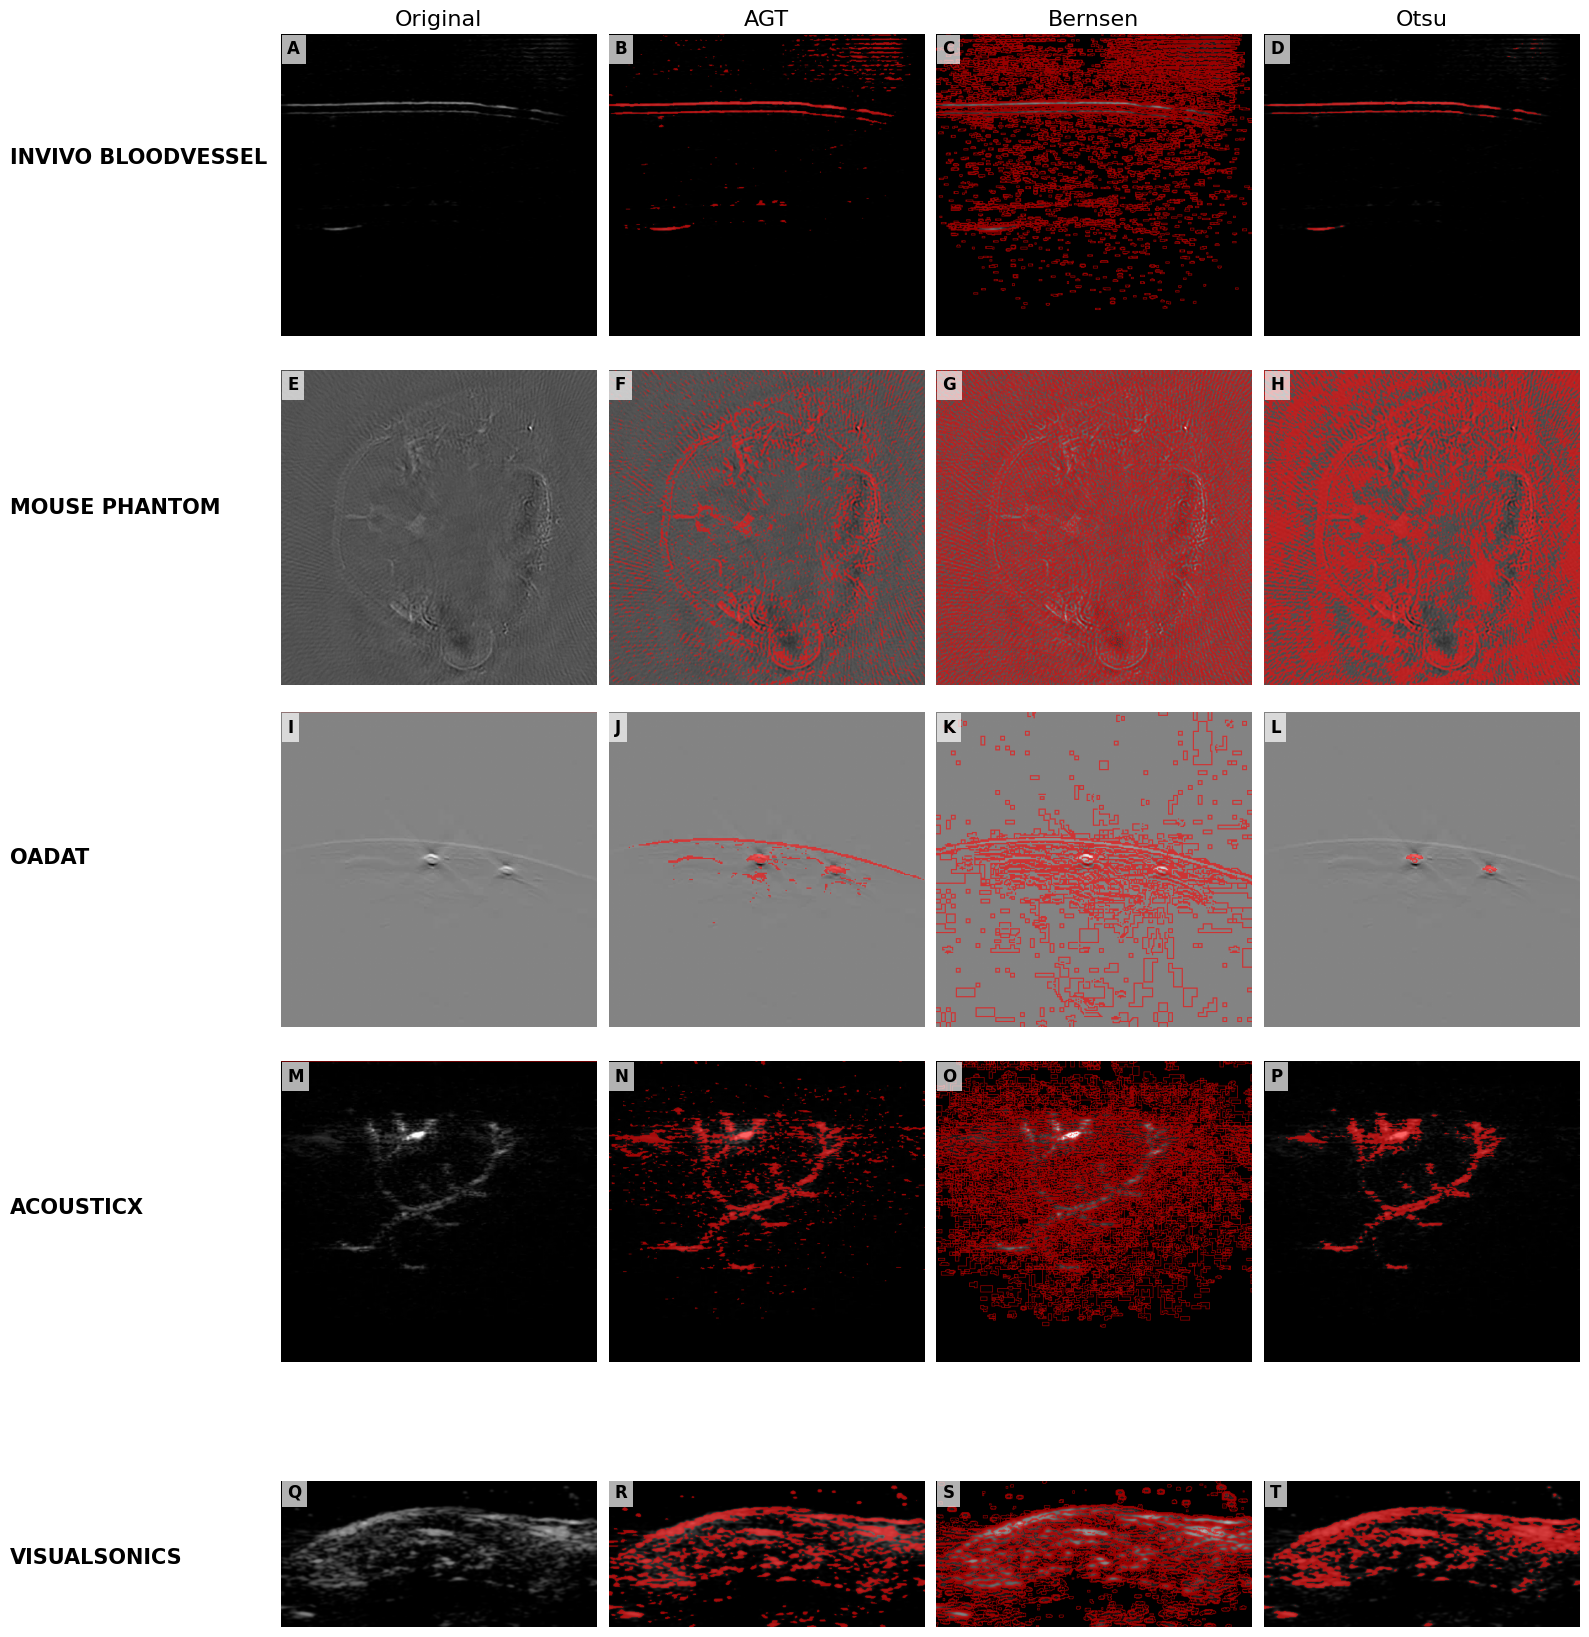

In [39]:
import string

import matplotlib.pyplot as plt
import numpy as np


def compute_masks_for_pair(img1, img2):
    """Compute the four masks + titles for one image pair."""
    mask_local = calculate_combined_mask(img1, img2)

    # Bernsen
    mask1_b = bernsen(img1, radius=2, contrast_threshold=5)
    mask2_b = bernsen(img2, radius=2, contrast_threshold=5)
    mask_bernsen = np.logical_or(mask1_b, mask2_b)

    # Otsu
    thresh1 = threshold_otsu(img1)
    thresh2 = threshold_otsu(img2)
    mask1_o = img1 > thresh1
    mask2_o = img2 > thresh2
    mask_otsu = np.logical_or(mask1_o, mask2_o)

    masks = [mask_local * 0, mask_local, mask_bernsen, mask_otsu]
    titles = ["Original", "AGT", "Bernsen", "Otsu"]
    return img2, masks, titles

import matplotlib.pyplot as plt
import numpy as np


def _panel_label(idx: int) -> str:
    letters = string.ascii_uppercase
    s = ""
    n = idx
    while True:
        s = letters[n % 26] + s
        n = n // 26 - 1
        if n < 0:
            break
    return s


def visualize_all_mask_rows(dataset_rows, alpha=0.6):
    """
    dataset_rows = [
        ("Dataset Name", [
            ("HIGH", img1, img2),
            ("LOW",  img1, img2),
        ]),
        ...
    ]
    """

    total_rows = sum(len(levels) for _, levels in dataset_rows)
    n_cols = 4  # Original, AGT, Bernsen, Otsu

    fig, axes = plt.subplots(total_rows, n_cols, figsize=(4 * n_cols, 3.5 * total_rows))
    axes = np.atleast_2d(axes)

    panel_idx = 0
    row_idx = 0

    for dataset_name, levels in dataset_rows:

        for level_idx, (level_name, img1, img2) in enumerate(levels):

            base_img, masks, titles = compute_masks_for_pair(img1, img2)

            # Convert grayscale → RGB once per row  
            base_rgb = np.stack([base_img, base_img, base_img], axis=-1)

            # =====================
            # Left-side labels
            # =====================

            # dataset label (only on first row of dataset)
            if level_idx == 0:
                y = 1 - (row_idx + 0.50) / total_rows
                fig.text(
                    0.01, y,
                    dataset_name.upper(),
                    ha="left", va="center",
                    fontsize=15, fontweight="bold"
                )

            # HIGH / LOW
            # y = 1 - (row_idx + 0.50) / total_rows
            # fig.text(
            #     0.06, y,
            #     level_name.upper(),
            #     ha="left", va="center",
            #     fontsize=13, fontweight="bold"
            # )


            # =====================
            # Draw 4 columns
            # =====================
            for col in range(n_cols):
                ax = axes[row_idx, col]

                # mask for this column
                mask = masks[col]

                # Create RED overlay
                overlay = base_rgb.copy()
                overlay[mask] = [1, 0, 0]  # pure red where mask is True

                # Blend
                blended = (1 - alpha) * base_rgb + alpha * overlay

                ax.imshow(blended, vmin=0, vmax=1)
                ax.axis('off')

                # titles on top row only
                if row_idx == 0:
                    ax.set_title(titles[col], fontsize=16)

                # Panel label A, B, C, …
                label = _panel_label(panel_idx)
                ax.text(
                    0.02, 0.98, label,
                    transform=ax.transAxes,
                    ha="left", va="top",
                    fontsize=12, fontweight="bold",
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.7)
                )

                panel_idx += 1

            row_idx += 1

    plt.tight_layout(rect=[0.17, 0, 1, 1])
    plt.subplots_adjust(wspace=0.04)
    plt.show()


visualize_all_mask_rows(rows)


In [84]:
# from scipy.stats import spearmanr, pearsonr, kendalltau
# import re
# import pandas as pd
# import os

# df = pd.read_csv("varied_split_per_image_metrics_2025-05-30_07-27-56.csv")
# # [VARIED SPLIT CONTENTS]
# #   [Mouse Phantom]
# #     22xx Mice x10 IN VIVO
# #     23xx Phantom - 3 Circles x4 PHANTOM
# #   [OADAT]
# #     32xx SWFD_sc SEMICIRCLE x10 IN VIVO
# #     33xx SWFD_ms MULTISEGMENT x10 IN VIVO
# # Helper to compute scores
# def compare(ref, rec, sens=0.5):
#     ssim_score = structural_similarity(ref, rec, data_range=1.0)
#     msssim_score = msssim(ref, rec)
#     wssim_score = np.average(cw_ssim(ref, rec))
#     s3im_score, _, _ = s3im(ref, rec, SSIM_variant=structural_similarity, sensitivity=sens, increase_sensitivity=False)
#     mss3im_score, _ = mss3im(ref, rec)
#     ws3im_score, _, _ = s3im(ref, rec, SSIM_variant=cw_ssim, sensitivity=sens)
#     return ssim_score, msssim_score, wssim_score, s3im_score, mss3im_score, ws3im_score

# # Store results
# scores_ssim = []
# scores_msssim = []
# scores_wssim = []
# scores_s3im = []
# scores_mss3im = []
# scores_ws3im = []
# names = []

# # Iterate over samples
# for i, row in df.iterrows():
#     rec_path = row['image_path']
#     ref_path = os.path.join(os.path.dirname(rec_path), row['ground_truth'])
#     if not os.path.exists(ref_path) or not os.path.exists(rec_path):
#         continue
#     if int(ref_path.split('scene_')[1][:2]) > 33:
#         continue
#     print(ref_path, rec_path)
#     with PIL_Image.open(ref_path) as img:
#         ref_img = img.convert('L')
#         ref_img = img_as_float(ref_img)
#         print(ref_img.max(), ref_img.min(), ref_img.mean())

#     with PIL_Image.open(rec_path) as img:
#         # data/VARIED SPLIT V3 CURRENT/scene_2201/image_113_full.webp
#         rec_img = img.convert('L')
#         rec_img = img_as_float(rec_img)

#     # mask = calculate_combined_mask(ref_img, rec_img, and_or="or")
#     # visualize_mask_overlay(rec_img, mask, alpha=0.6, title="S3IM Mask Overlay")

#     # Get quality scores
#     ssim_val, msssim_val, wssim_val, s3im_val, mss3im_val, ws3im_val = compare(ref_img, rec_img)
#     names.append(rec_path)
#     scores_ssim.append(ssim_val)
#     scores_msssim.append(msssim_val)
#     scores_wssim.append(wssim_val)
#     scores_s3im.append(s3im_val)
#     scores_mss3im.append(mss3im_val)
#     scores_ws3im.append(ws3im_val)

# # Convert to numpy arrays
# scores_ssim = np.array(scores_ssim)
# scores_msssim = np.array(scores_msssim)
# scores_wssim = np.array(scores_wssim)
# scores_s3im = np.array(scores_s3im)
# scores_mss3im = np.array(scores_mss3im)
# scores_ws3im = np.array(scores_ws3im)



In [79]:
# for i in range(len(names)):
#     print("name   ", names[i])
#     print("SSIM   ", scores_ssim[i])
#     print("MS-SSIM", scores_msssim[i])
#     print("W-SSIM ", scores_wssim[i])
#     print("S3IM   ", scores_s3im[i])
#     print("MS-S3IM", scores_mss3im[i])
#     print("W-S3IM ", scores_ws3im[i])

# df = pd.DataFrame({
#     "img": [x.split('/')[-1] for x in names],
#     'ssim': scores_ssim,
#     'msssim': scores_msssim,
#     'wssim': scores_wssim,
#     's3im': scores_s3im,
#     'mss3im': scores_mss3im,
#     'ws3im': scores_ws3im
# })
# for variant in ["ssim", "msssim", 'wssim']:
#     print(variant, variant.replace('si', '3i'))
#     df[variant+'_ROI_diff'] = df[variant] - df[variant.replace('si', '3i')]
# max(df["ssim"] - df["s3im"])

In [ ]:
# from scipy.stats import shapiro
# from scipy.stats import ttest_rel, wilcoxon
# from scipy.stats import norm
# import math

# stat, p = shapiro(df["ssim"])  # `data` is a 1D array or Series
# print(f"Shapiro-Wilk test: W={stat:.4f}, p={p:.4f}")

# if p > 0.05:
#     print("Data appears to be normally distributed (p > 0.05)")
# else:
#     print("Data is likely not normally distributed (p ≤ 0.05)")


# stat, p = shapiro(df["s3im"])  # `data` is a 1D array or Series
# print(f"Shapiro-Wilk test: W={stat:.4f}, p={p:.4f}")

# if p > 0.05:
#     print("Data appears to be normally distributed (p > 0.05)")
# else:
#     print("Data is likely not normally distributed (p ≤ 0.05)\n")


# statistic, p_value = wilcoxon(df["ssim"], df["s3im"])

# # Calculate effect size r = Z / sqrt(N)
# # SciPy does not return Z directly, but it can be approximated from statistic and ranks
# # For now, we'll use a simplified approximation:
# N = len(df["s3im"])
# z_approx = statistic - (N * (N + 1)) / 4  # crude centering
# sd = math.sqrt((N * (N + 1) * (2 * N + 1)) / 24)
# z_value = z_approx / sd
# effect_size_r = abs(z_value) / math.sqrt(N)

# # Report
# print(f"A Wilcoxon signed-rank test indicated a difference between Variant A and Variant B, "
#       f"Z = {z_value:.2f}, p = {p_value:.3f}, r = {effect_size_r:.2f}")

# n = len(df["ssim"])
# print(n)
# # Z from p-value (two-sided)
# z = norm.ppf(1 - p_wilcoxon / 2)
# r = z / np.sqrt(n)
# print(f"Effect size r = {r:.4f}\n")

# # Step 1: Difference per sample
# diff = df["ssim"] - df["s3im"]

# # Step 2: Median
# median_diff = np.median(diff)

# # Step 3: 95% CI using bootstrapping
# n_bootstraps = 10000
# boot_diffs = np.random.choice(diff, size=(n_bootstraps, len(diff)), replace=True)
# boot_medians = np.median(boot_diffs, axis=1)
# ci_lower, ci_upper = np.percentile(boot_medians, [2.5, 97.5])
# print("ssim mean: ", np.mean(df["ssim"]), np.std(df["ssim"]))
# print("s3im mean: ", np.mean(df["s3im"]), np.std(df["s3im"]))
# print(f"The median difference was {median_diff:.3f} (95% CI [{ci_lower:.3f}, {ci_upper:.3f}]), suggesting the two metrics yield comparable values in practice.")

# max(np.abs(diff))
# min(diff)

KeyError: 'ssim'

In [ ]:
# # save as make_metrics_table_image.py and run with: python make_metrics_table_image.py
# import matplotlib.pyplot as plt
# from matplotlib.patches import Rectangle

# # ---------- 1) DATA ----------
# metrics = ["SSIM", "CW-SSIM", "MS-SSIM", "S3IM", "CW-S3IM", "MS-S3IM"]
# data = {
#     "SSIM":     [0.12, 0.25, -0.05, 0.30, 0.42, -0.10, 0.21, 0.35, -0.12, 0.09, 0.18, -0.03],
#     "CW-SSIM":  [0.10, 0.21, -0.04, 0.27, 0.40, -0.09, 0.18, 0.32, -0.10, 0.08, 0.16, -0.03],
#     "MS-SSIM":  [0.11, 0.23, -0.05, 0.28, 0.41, -0.10, 0.19, 0.33, -0.11, 0.08, 0.17, -0.03],
#     "S3IM":     [0.13, 0.26, -0.06, 0.29, 0.43, -0.11, 0.20, 0.34, -0.12, 0.09, 0.18, -0.04],
#     "CW-S3IM":  [0.12, 0.24, -0.05, 0.28, 0.41, -0.10, 0.19, 0.31, -0.11, 0.08, 0.16, -0.03],
#     "MS-S3IM":  [0.11, 0.22, -0.05, 0.27, 0.40, -0.09, 0.18, 0.30, -0.10, 0.08, 0.15, -0.03],
# }

# # ---------- 2) LAYOUT SETTINGS ----------
# group_titles = ["Pixel dropout", "Noise", "Blur", "Averaging"]
# sub_titles   = ["Avg drop", "Max drop", "Slope"]
# cols_per_group = 3
# G = len(group_titles)
# C = G * cols_per_group
# R = len(metrics)

# w_metric = 1.7          # left label column
# cell_w   = 1.2
# cell_h   = 0.6
# hdr_h1   = 0.55         # sub-header height
# hdr_h2   = 0.55         # group header height
# gap      = 0.35

# data_h   = R * cell_h
# table_w  = w_metric + C * cell_w
# table_h  = data_h + hdr_h1 + hdr_h2   # bottom -> data -> subhdr -> grouphdr
# fig_w    = table_w + 2 * gap
# fig_h    = table_h + 2 * gap

# # Baselines (from bottom up)
# x0, y0         = gap, gap
# y_data0        = y0                      # bottom of data block
# y_subhdr_mid   = y_data0 + data_h + hdr_h1 / 2
# y_grouphdr_mid = y_data0 + data_h + hdr_h1 + hdr_h2 / 2
# y_top          = y0 + table_h

# # ---------- 3) CANVAS ----------
# fig, ax = plt.subplots(figsize=(fig_w, fig_h))
# ax.set_xlim(0, fig_w)
# ax.set_ylim(0, fig_h)
# ax.axis("off")
# ax.add_patch(Rectangle((x0, y0), table_w, table_h, color="white", zorder=0))

# # ---------- 4) GRID LINES ----------
# # Outer verticals
# ax.plot([x0, x0], [y0, y_top], color="black", linewidth=1)
# ax.plot([x0 + w_metric, x0 + w_metric], [y0, y_top], color="black", linewidth=1)
# for c in range(C + 1):
#     x = x0 + w_metric + c * cell_w
#     ax.plot([x, x], [y0, y_top], color="black", linewidth=1)

# # Horizontal lines: data rows
# for r in range(R + 1):
#     y = y_data0 + r * cell_h
#     ax.plot([x0, x0 + table_w], [y, y], color="black", linewidth=1)

# # Separators for sub-header and group header
# ax.plot([x0, x0 + table_w], [y_data0 + data_h, y_data0 + data_h], color="black", linewidth=1)           # data ↔ subhdr
# ax.plot([x0, x0 + table_w], [y_data0 + data_h + hdr_h1, y_data0 + data_h + hdr_h1], color="black", linewidth=1) # subhdr ↔ grouphdr
# ax.plot([x0, x0 + table_w], [y_top, y_top], color="black", linewidth=1)                                    # top border

# # Optional separator between SSIM and S3IM (after 3 rows)
# sep_y = y_data0 + 3 * cell_h
# ax.plot([x0, x0 + table_w], [sep_y, sep_y], color="black", linewidth=1)

# # ---------- 5) TEXT ----------
# # Row labels
# for i, name in enumerate(metrics):
#     y = y_data0 + (i + 0.5) * cell_h
#     ax.text(x0 + 0.08, y, name, va="center", ha="left", fontsize=12, fontweight="bold")

# # Big "Metric" label
# ax.text(x0 - 0.35, y0 + table_h / 2, "Metric",
#         rotation=90, va="center", ha="center", fontsize=14, fontweight="bold")

# # Sub-headers (centered in their band just above data)
# for g in range(G):
#     for k, sub in enumerate(sub_titles):
#         col = g * cols_per_group + k
#         x = x0 + w_metric + col * cell_w + cell_w / 2
#         ax.text(x, y_subhdr_mid, sub, ha="center", va="center",
#                 fontsize=12, fontweight="bold")

# # Group headers (very top band)
# for g, title in enumerate(group_titles):
#     start_x = x0 + w_metric + g * cols_per_group * cell_w
#     end_x   = start_x + cols_per_group * cell_w
#     cx = (start_x + end_x) / 2
#     ax.text(cx, y_grouphdr_mid, title, ha="center", va="center",
#             fontsize=14, fontweight="bold")

# # Data cells
# for i, m in enumerate(metrics):
#     vals = data[m]
#     for j in range(C):
#         x = x0 + w_metric + j * cell_w + cell_w / 2
#         y = y_data0 + (i + 0.5) * cell_h
#         ax.text(x, y, str(vals[j]), ha="center", va="center", fontsize=11)

# # ---------- 6) SAVE ----------
# plt.savefig("metrics_table.png", dpi=200, bbox_inches="tight")
# print("Saved: metrics_table.png")


c:\Users\SemKj\Downloads\ssim\ssim\paper\lib\site-packages\skimage\metrics\simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


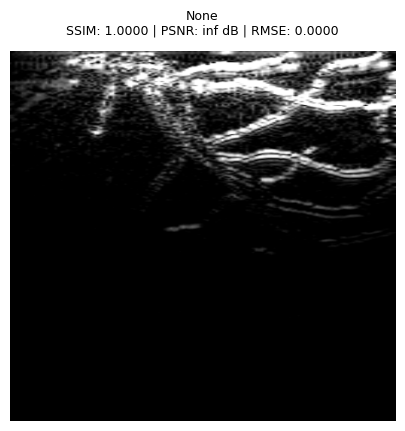

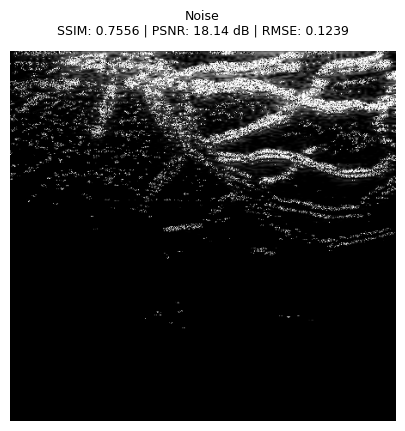

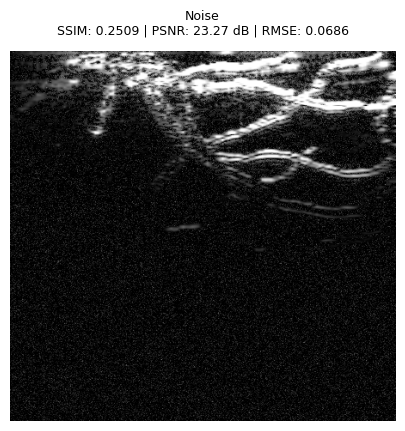

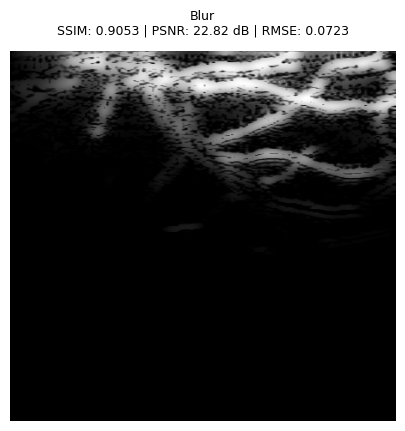

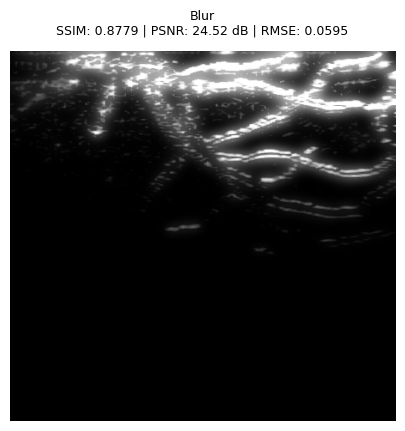

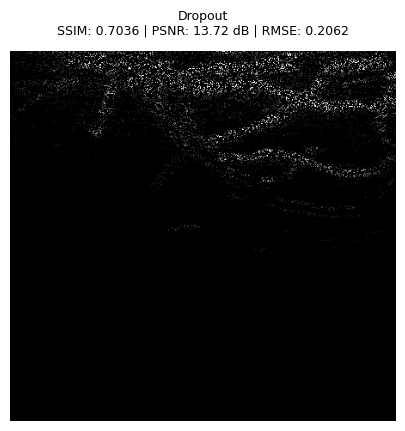

In [ ]:
original_img = greyscaleImages[0]
distorted_img = random_noise(original_img, mode='gaussian', var=0.2, clip=True, rng=42)

mask = calculate_combined_mask(original_img, original_img)
locally_distorted_img = distorted_img * mask + original_img * (1 - mask)

distorted_img = random_noise(original_img, mode='gaussian', var=0.01, clip=True, rng=42)
outside_distorted_img = distorted_img * (1 - mask) + original_img * mask



noisy_img = gaussian_filter(original_img, sigma=6)
locally_blur_img = original_img * (1 - mask) + noisy_img * mask
outside_blur_img = original_img * mask + noisy_img * (1-mask)


dropped = drop_pixels(original_img, 0.8)

def show_image_with_ssim(img, distorted_img, title, data_range=1.0):
    ssim_val = structural_similarity(distorted_img, img, data_range=data_range)
    rmse_score = mean_squared_error(distorted_img, img)**0.5
    psnr_score = peak_signal_noise_ratio(distorted_img, img, data_range=1.0)
    plt.imshow(distorted_img, cmap='gray')
    plt.axis('off')
    plt.title(f"{title}\nSSIM: {ssim_val:.4f} | PSNR: {psnr_score:.2f} dB | RMSE: {rmse_score:.4f}", fontsize=9, pad=12)
    plt.show()

show_image_with_ssim(original_img, original_img, "None")
show_image_with_ssim(original_img, locally_distorted_img, "Noise")
show_image_with_ssim(original_img, outside_distorted_img, "Noise")
show_image_with_ssim(original_img, locally_blur_img, "Blur")
show_image_with_ssim(original_img, outside_blur_img, "Blur")
show_image_with_ssim(original_img, dropped, "Dropout")

c:\Users\SemKj\Downloads\ssim\ssim\paper\lib\site-packages\skimage\metrics\simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


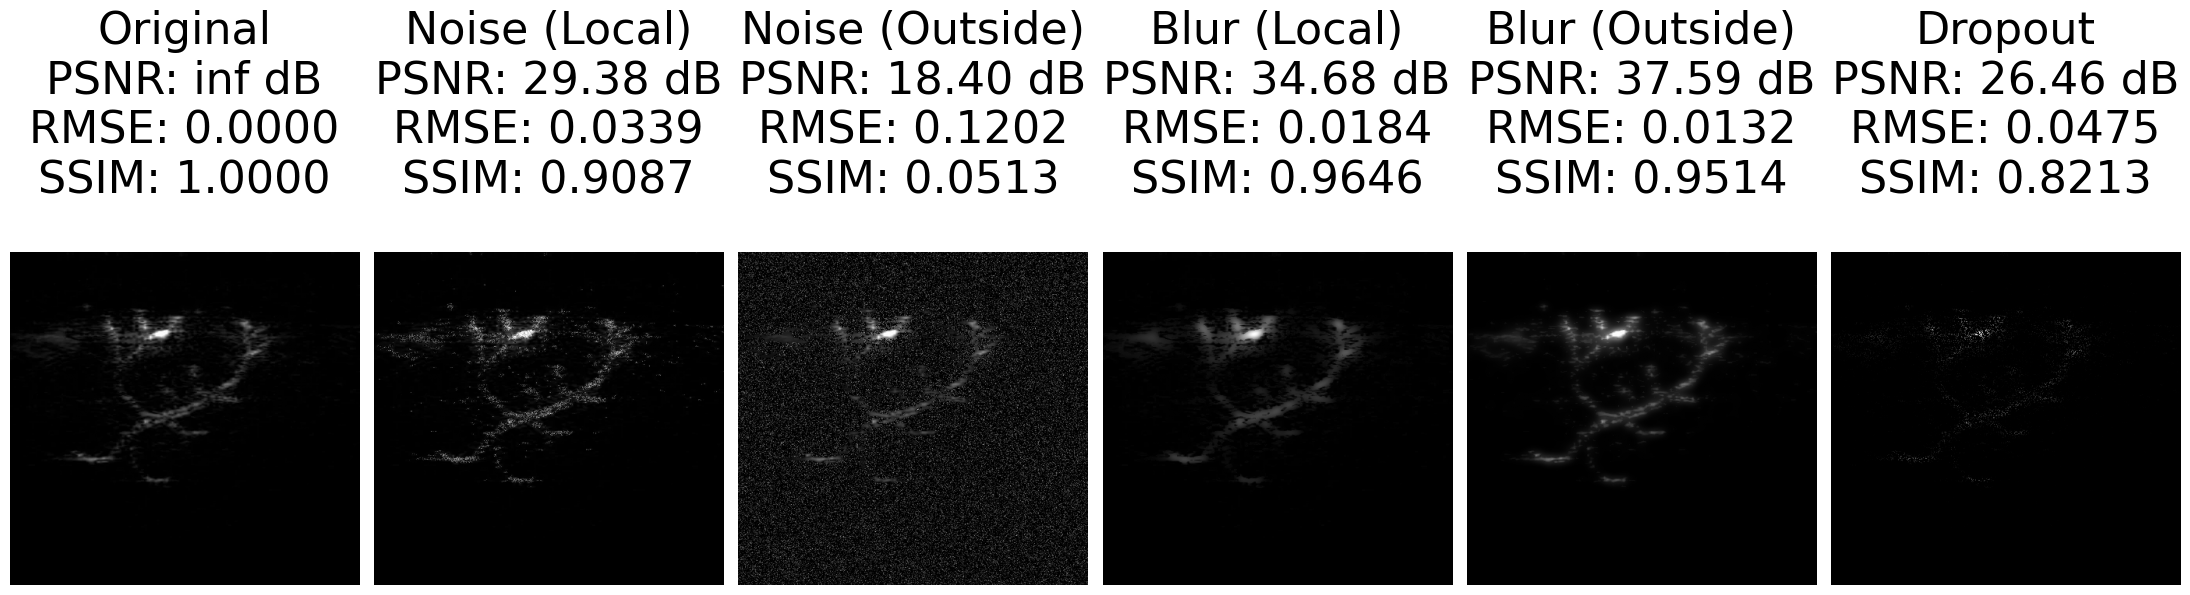

In [40]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity
from skimage.util import random_noise


def rmse(img1, img2):
    return np.sqrt(mean_squared_error(img1, img2))

def compute_metrics(original, distorted, data_range=1.0):
    return {
        'SSIM': structural_similarity(original, distorted, data_range=data_range),
        'PSNR': peak_signal_noise_ratio(original, distorted, data_range=data_range),
        'RMSE': rmse(original, distorted),
        "S3IM": s3im(original, distorted)[0],
        "MS-SSIM": msssim(original, distorted),
        "MS-S3IM": mss3im(original, distorted)[0],
        "CW-SSIM": np.average(cw_ssim(original, distorted)),
        "CW-S3IM": s3im(original, distorted, SSIM_variant=cw_ssim)[0],
        "SNR": snr_reference(original, distorted)
    }

# Image setup
with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)
noisy_img = random_noise(original_img, mode='gaussian', var=0.03, clip=True, rng=42)

mask = calculate_combined_mask(original_img, original_img)
locally_distorted_img = noisy_img * mask + original_img * (1 - mask)

outside_distorted_img = noisy_img * (1 - mask) + original_img * mask

blur_img = gaussian_filter(original_img, sigma=4)
locally_blur_img = original_img * (1 - mask) + blur_img * mask
outside_blur_img = original_img * mask + blur_img * (1 - mask)

dropped = drop_pixels(original_img, 0.8)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA3.webp") as img:
    pa_img = img.convert('L')
    pa_img = img_as_float(pa_img)

# Titles and images
titles = ["Original", "Noise (Local)", "Noise (Outside)", "Blur (Local)", "Blur (Outside)", "Dropout"]
images = [original_img, locally_distorted_img, outside_distorted_img, locally_blur_img, outside_blur_img, dropped]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(22, 6))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB
RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}
""",
fontsize=32
    )

plt.tight_layout()
plt.show()


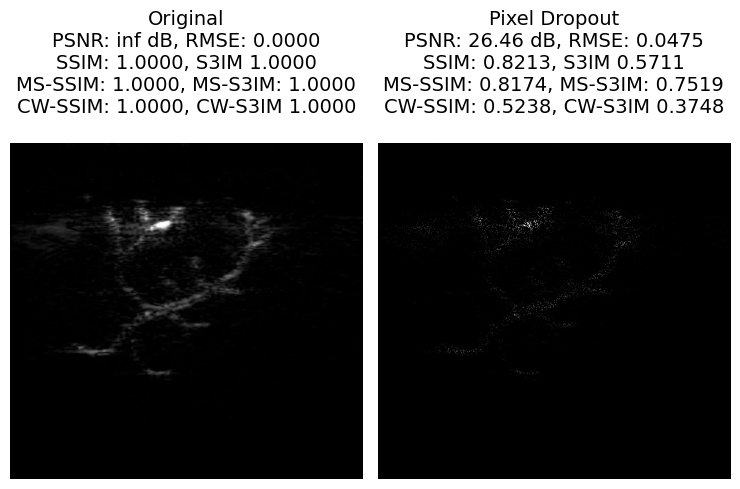

In [ ]:
titles = ["Original", "Pixel Dropout"]
images = [original_img, dropped]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(7.5, 6))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB, RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}, S3IM {metrics['S3IM']:.4f}
MS-SSIM: {metrics['MS-SSIM']:.4f}, MS-S3IM: {metrics['MS-S3IM']:.4f}
CW-SSIM: {metrics['CW-SSIM']:.4f}, CW-S3IM {metrics['CW-S3IM']:.4f}
""",
fontsize=14
    )

plt.tight_layout()
plt.show()

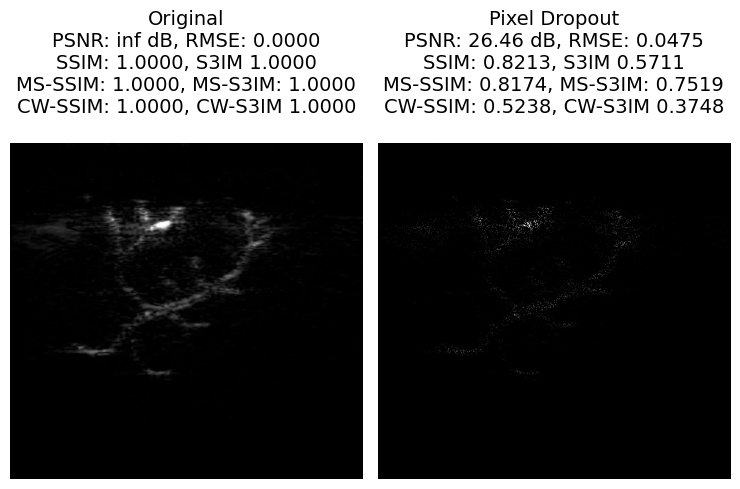

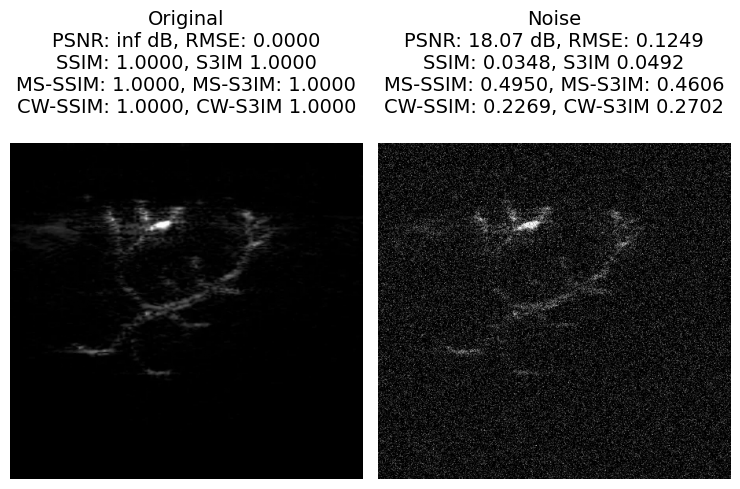

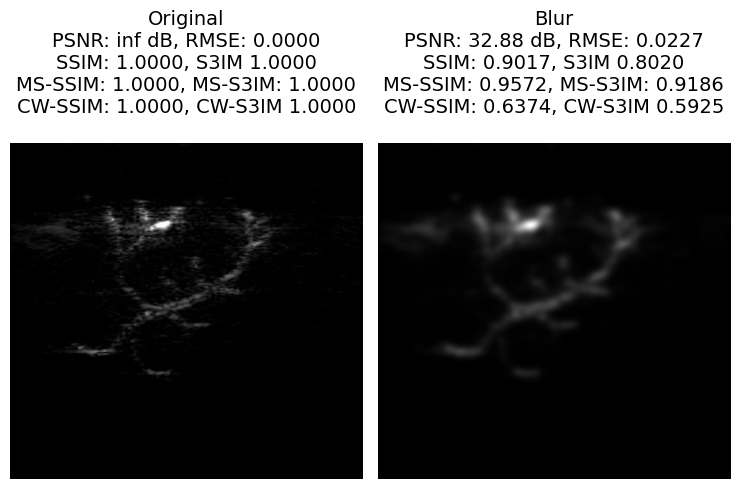

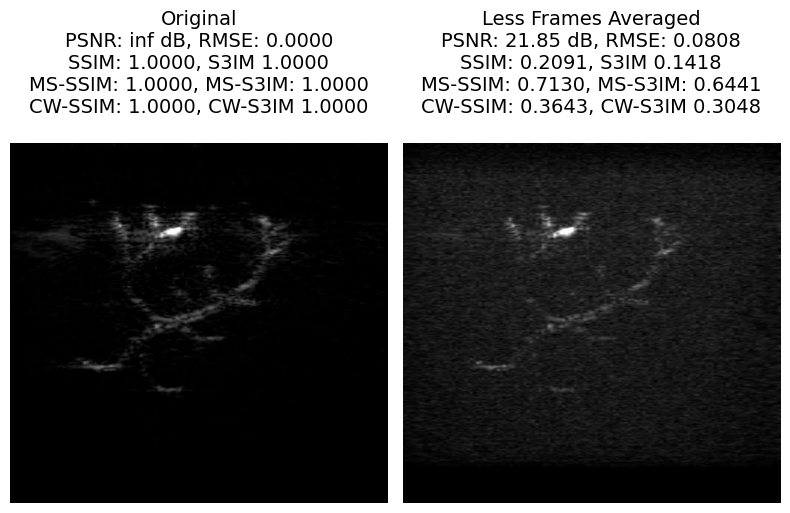

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity
from skimage.util import random_noise


def rmse(img1, img2):
    return np.sqrt(mean_squared_error(img1, img2))

def compute_metrics(original, distorted, data_range=1.0):
    return {
        'SSIM': structural_similarity(original, distorted, data_range=data_range),
        'PSNR': peak_signal_noise_ratio(original, distorted, data_range=data_range),
        'RMSE': rmse(original, distorted),
        "S3IM": s3im(original, distorted)[0],
        "MS-SSIM": msssim(original, distorted),
        "MS-S3IM": mss3im(original, distorted)[0],
        "CW-SSIM": np.average(cw_ssim(original, distorted)),
        "CW-S3IM": s3im(original, distorted, SSIM_variant=cw_ssim)[0],
        "SNR": snr_reference(original, distorted)
    }

# Image setup
with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)
noisy_img = random_noise(original_img, mode='gaussian', var=0.03, clip=True, rng=42)

mask = calculate_combined_mask(original_img, original_img)
locally_distorted_img = noisy_img * mask + original_img * (1 - mask)

outside_distorted_img = noisy_img * (1 - mask) + original_img * mask

blur_img = gaussian_filter(original_img, sigma=4)
locally_blur_img = original_img * (1 - mask) + blur_img * mask
outside_blur_img = original_img * mask + blur_img * (1 - mask)

dropped = drop_pixels(original_img, 0.8)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA3.webp") as img:
    pa_img = img.convert('L')
    pa_img = img_as_float(pa_img)

# Titles and images
titles = ["Original", "Noise (Local)", "Noise (Outside)", "Blur (Local)", "Blur (Outside)", "Dropout"]
images = [original_img, locally_distorted_img, outside_distorted_img, locally_blur_img, outside_blur_img, dropped]

titles = ["Original", "Pixel Dropout"]
images = [original_img, dropped]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(7.5, 6))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB, RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}, S3IM {metrics['S3IM']:.4f}
MS-SSIM: {metrics['MS-SSIM']:.4f}, MS-S3IM: {metrics['MS-S3IM']:.4f}
CW-SSIM: {metrics['CW-SSIM']:.4f}, CW-S3IM {metrics['CW-S3IM']:.4f}
""",
fontsize=14
    )

plt.tight_layout()
plt.show()

titles = ["Original", "Noise"]
images = [original_img, noisy_img]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(7.5, 6))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB, RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}, S3IM {metrics['S3IM']:.4f}
MS-SSIM: {metrics['MS-SSIM']:.4f}, MS-S3IM: {metrics['MS-S3IM']:.4f}
CW-SSIM: {metrics['CW-SSIM']:.4f}, CW-S3IM {metrics['CW-S3IM']:.4f}
""",
fontsize=14
    )

plt.tight_layout()
plt.show()

titles = ["Original", "Blur"]
images = [original_img, blur_img]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(7.5, 6))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB, RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}, S3IM {metrics['S3IM']:.4f}
MS-SSIM: {metrics['MS-SSIM']:.4f}, MS-S3IM: {metrics['MS-S3IM']:.4f}
CW-SSIM: {metrics['CW-SSIM']:.4f}, CW-S3IM {metrics['CW-S3IM']:.4f}
""",
fontsize=14
    )

plt.tight_layout()
plt.show()


titles = ["Original", "Less Frames Averaged"]
images = [original_img, pa_img]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(8, 8))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB, RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}, S3IM {metrics['S3IM']:.4f}
MS-SSIM: {metrics['MS-SSIM']:.4f}, MS-S3IM: {metrics['MS-S3IM']:.4f}
CW-SSIM: {metrics['CW-SSIM']:.4f}, CW-S3IM {metrics['CW-S3IM']:.4f}
""",
fontsize=14
    )

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np


def wilcoxon_with_effects(x, y, min_n_for_z=20):
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    
    # drop NaNs
    mask = ~np.isnan(x) & ~np.isnan(y)
    x, y = x[mask], y[mask]
    
    diffs = x - y
    n = len(diffs)

    # Wilcoxon Signed-Rank test
    stat, p = wilcoxon(diffs, zero_method="wilcox", method="auto")
    
    result = {
        "n": n,
        "W": stat,
        "p": p,
        "mean_x": np.mean(x),
        "sd_x": np.std(x, ddof=1),
        "mean_y": np.mean(y),
        "sd_y": np.std(y, ddof=1),
        "median_diff": np.median(diffs),
        "max_abs_diff": np.max(np.abs(diffs)),
    }

    # only compute Z + effect size r if enough data
    if n >= min_n_for_z:
        abs_d = np.abs(diffs)
        ranks = rankdata(abs_d, method="average")
        signed_ranks = np.sign(diffs) * ranks

        W_plus = signed_ranks[signed_ranks > 0].sum()
        W_minus = -signed_ranks[signed_ranks < 0].sum()
        W = min(W_plus, W_minus)

        mean_W = n * (n + 1) / 4
        T = sum((np.unique(abs_d, return_counts=True)[1]) * 
                (np.unique(abs_d, return_counts=True)[1] + 1) * 
                (2*np.unique(abs_d, return_counts=True)[1] + 1))
        var_W = (n * (n + 1) * (2*n + 1) - T) / 24
        sd_W = math.sqrt(var_W)

        Z = (W - mean_W) / sd_W if sd_W > 0 else np.nan
        r = Z / np.sqrt(n)

        result.update({"Z": Z, "r": r})
    else:
        result.update({"Z": None, "r": None})

    return result


# Example dictionary with SSIM/S3IM arrays
data_dict = {
    "ACOUSTICX": {
        "ssim": [0.72, 0.74, 0.70, 0.69],
        "s3im": [0.71, 0.74, 0.69, 0.68]
    },
    "MousePhantom": {
        "ssim": np.random.rand(50),   # example real-size data
        "s3im": np.random.rand(50)
    },
    "OADAT": {
        "ssim": np.random.rand(60),
        "s3im": np.random.rand(60)
    }
}

# Run analysis for each dataset
results = {}
for name, vals in data_dict.items():
    res = wilcoxon_with_effects(vals["ssim"], vals["s3im"])
    results[name] = res

# Display nicely
for name, res in results.items():
    print(f"\n=== {name} ===")
    for k, v in res.items():
        print(f"{k}: {v}")


usage: ipykernel_launcher.py [-h] [--csv CSV] [--ssim-col SSIM_COL]
                             [--s3im-col S3IM_COL] [--alpha ALPHA]
                             [--n_boot N_BOOT]
ipykernel_launcher.py: error: unrecognized arguments: --f=c:\Users\SemKj\AppData\Roaming\jupyter\runtime\kernel-v307abe5ac57f40fdc299f73abeffcd8086d0f187e.json


SystemExit: 2

c:\Users\SemKj\Downloads\ssim\ssim\paper\lib\site-packages\IPython\core\interactiveshell.py:3587: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


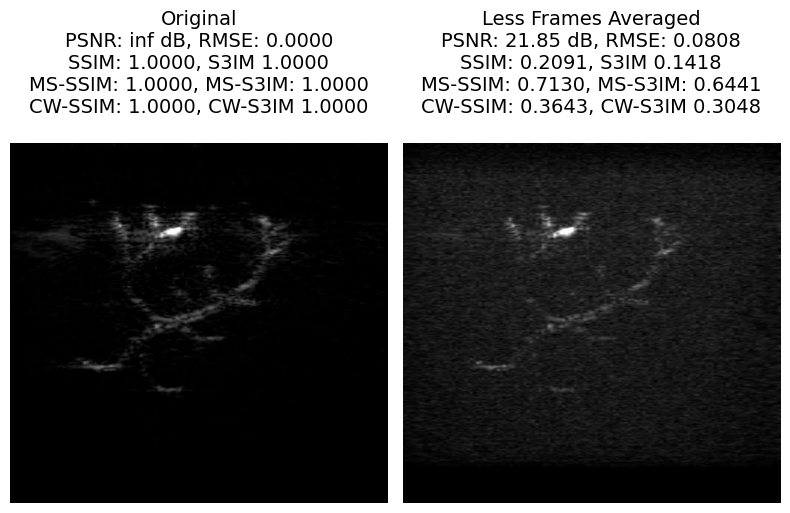

In [ ]:
titles = ["Original", "Less Frames Averaged"]
images = [original_img, pa_img]

# Plot all in one row
fig, axes = plt.subplots(1, len(images), figsize=(8, 8))

for ax, title, distorted_img in zip(axes, titles, images):
    metrics = compute_metrics(original_img, distorted_img)
    ax.imshow(distorted_img, cmap='gray')
    ax.axis('off')
    ax.set_title(
        f"""{title}
PSNR: {metrics['PSNR']:.2f} dB, RMSE: {metrics['RMSE']:.4f}
SSIM: {metrics['SSIM']:.4f}, S3IM {metrics['S3IM']:.4f}
MS-SSIM: {metrics['MS-SSIM']:.4f}, MS-S3IM: {metrics['MS-S3IM']:.4f}
CW-SSIM: {metrics['CW-SSIM']:.4f}, CW-S3IM {metrics['CW-S3IM']:.4f}
""",
fontsize=14
    )

plt.tight_layout()
plt.show()
# PA1 - 25600
# PA2 - 128
# PA3 - 256
# PA4 - 384
# PA5 - 640
# PA6 - 1280
# PA7 - 2560

In [ ]:
with PIL_Image.open("cropped/Invivo__PrintedPhantom_Rf_062323_192813__PA1.png") as img:
    original_img = img.convert('L')
    original_img = img_as_float(img1)
original_img.shape

NameError: name 'img1' is not defined

In [ ]:
# def calculate_combined_mask(img1, img2, sensitivity=0.5):
#     assert img1.ndim == 2 and img2.ndim == 2
#     assert img1.shape == img2.shape
#     # Define neighborhood size as in MATLAB
#     patch_size = 2 * (np.array(img1.shape) // 16) + 1

#     # Adaptive thresholding (Gaussian mean)
#     block_size = int(np.mean(patch_size))
#     if block_size % 2 == 0:
#         block_size += 1

#     # Compute adaptive thresholds
#     mean_thresh1 = threshold_local(img1, block_size, method='gaussian', offset=-(1 - sensitivity))
#     mean_thresh2 = threshold_local(img2, block_size, method='gaussian', offset=-(1 - sensitivity))

#     mask1 = img1 > mean_thresh1
#     mask2 = img2 > mean_thresh2
#     Mask = np.logical_or(mask1, mask2)

#     return Mask

In [ ]:
# i = 0
# for base_name, image_dict in PA_from_base.items():
#     for j in [1, 7, 6, 5, 4, 3, 2]:
#         mask_or = calculate_combined_mask(image_dict["PA1"], image_dict[f"PA{j}"], sensitivity=0.9)
#         mask_and = calculate_combined_mask_and(image_dict["PA1"], image_dict[f"PA{j}"], sensitivity=0.9)

#         masks = [mask_or, mask_and]
#         titles = ['or'+str(j), 'and'+str(j)]
#         # if (np.sum(mask_or) == 0):
#         print(f'or: {np.sum(mask_or)}   and: {np.sum(mask_and)}')
#         visualize_multiple_masks(image_dict[f"PA{j}"], masks, titles)


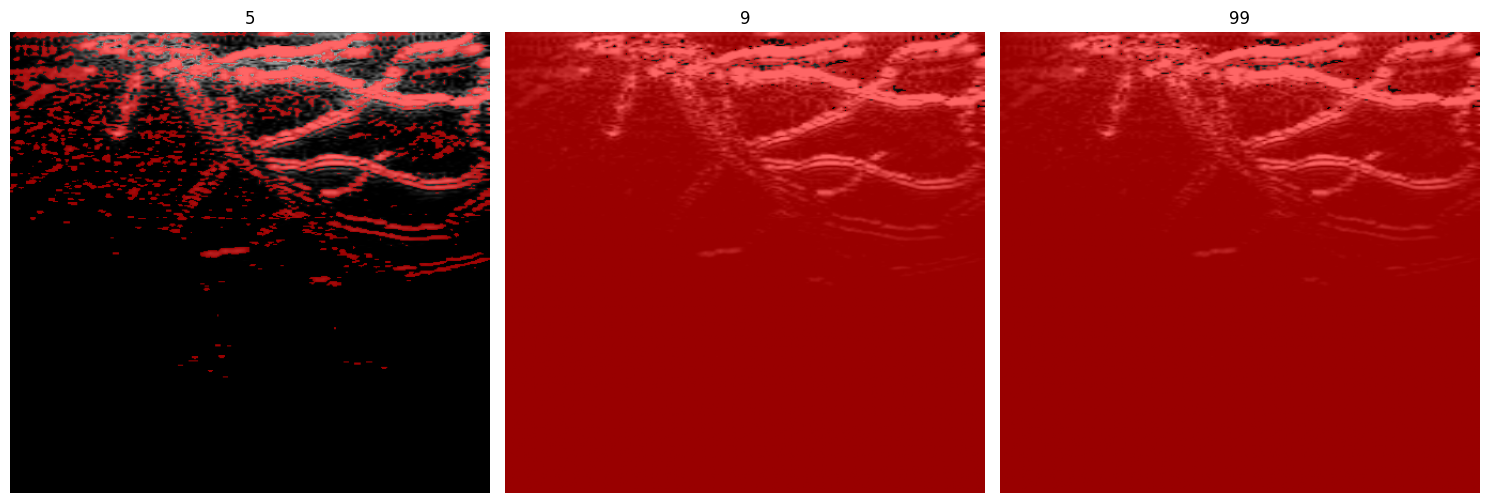

In [ ]:
mask_low = calculate_combined_mask(greyscaleImages[0], greyscaleImages[0], 0.5)
mask_mid = calculate_combined_mask(greyscaleImages[0], greyscaleImages[0], 0.90)
mask_high = calculate_combined_mask(greyscaleImages[0], greyscaleImages[0], 0.90)

masks = [mask_low, mask_mid, mask_high]
titles = ['5', '9', '99']

def visualize_multiple_masks(image, masks, titles, alpha=0.9):
    """
    Display the original image with multiple mask overlays side-by-side.
    
    Args:
        image: Grayscale image (2D array)
        masks: List of masks (boolean 2D arrays)
        titles: List of titles (one per mask)
        alpha: Transparency level for the mask overlay
    """
    n = len(masks)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if (type(axes) == matplotlib.axes._axes.Axes):
        axes = [axes]
    for ax, mask, title in zip(axes, masks, titles):
        rgb_image = np.stack([image, image, image], axis=-1)
        overlay = rgb_image.copy()
        overlay[mask] = [1, 0, 0]  # Red where masked
        blended = (1 - alpha) * rgb_image + alpha * overlay

        ax.imshow(blended)
        ax.set_title(title)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

visualize_multiple_masks(greyscaleImages[0], masks, titles, alpha=0.6)

In [ ]:
# variance_levels = np.linspace(0, 0.2, 20)  # for example: 0 (none) to 0.2

# # Prepare storage for average scores per variance level
# avg_ssim_scores_noise = []
# avg_wssim_scores_noise = []
# avg_msssim_scores_noise = []
# avg_mss3im_scores_noise = []
# avg_s3im_scores_noise = []
# avg_ws3im_scores_noise = []
# avg_mse_scores_noise = []
# avg_psnr_scores_noise = []

# # Per-image, per-noise-level metric storage (for Kendall tau etc.)
# scores_per_image_noise = {
#     idx: {
#         "ssim": [],
#         "wssim": [],
#         "msssim": [],
#         "mss3im": [],
#         "s3im": [],
#         "ws3im": [],
#     } for idx in range(len(greyscaleImages))
# }

# for variance in variance_levels:
#     ssim_scores = []
#     wssim_scores = []
#     msssim_scores = []
#     mss3im_scores = []
#     s3im_scores = []
#     ws3im_scores = []
#     mse_scores = []
#     psnr_scores = []

#     for idx, img in enumerate(greyscaleImages):
#         distorted = random_noise(img, mode='gaussian', var=variance, clip=True)
#         # Make sure the distorted image is in [0, 1] (random_noise should already do this)

#         ssim_score = structural_similarity(img, distorted, data_range=1.0)
#         wssim_score, _ = wssim(img, distorted)
#         msssim_score = msssim(img, distorted)
#         mss3im_score = ms_s3im(img, distorted)
#         s3im_score, _ = s3im(img, distorted, SSIM_variant=structural_similarity)
#         ws3im_score, _ = s3im(img, distorted, SSIM_variant=wssim)

#         mse_score = mean_squared_error(img, distorted)
#         psnr_score = peak_signal_noise_ratio(img, distorted, data_range=1.0) if mse_score != 0 else np.nan

#         ssim_scores.append(ssim_score)
#         wssim_scores.append(wssim_score)
#         msssim_scores.append(msssim_score)
#         mss3im_scores.append(mss3im_score)
#         s3im_scores.append(s3im_score)
#         ws3im_scores.append(ws3im_score)
#         mse_scores.append(mse_score)
#         psnr_scores.append(psnr_score)

#         # Store per-image, per-noise-level for tau calculation
#         scores_per_image_noise[idx]["ssim"].append(ssim_score)
#         scores_per_image_noise[idx]["wssim"].append(wssim_score)
#         scores_per_image_noise[idx]["msssim"].append(msssim_score)
#         scores_per_image_noise[idx]["mss3im"].append(mss3im_score)
#         scores_per_image_noise[idx]["s3im"].append(s3im_score)
#         scores_per_image_noise[idx]["ws3im"].append(ws3im_score)

#     # Store averages per noise variance
#     avg_ssim_scores_noise.append(np.mean(ssim_scores))
#     avg_wssim_scores_noise.append(np.mean(wssim_scores))
#     avg_msssim_scores_noise.append(np.mean(msssim_scores))
#     avg_mss3im_scores_noise.append(np.mean(mss3im_scores))
#     avg_s3im_scores_noise.append(np.mean(s3im_scores))
#     avg_ws3im_scores_noise.append(np.mean(ws3im_scores))
#     avg_mse_scores_noise.append(np.mean(mse_scores))
#     avg_psnr_scores_noise.append(np.mean(psnr_scores))

# # You can now plot average metrics vs. noise, and compute Kendall's tau as before:
# from scipy.stats import kendalltau

# taus_ssim_noise = []
# taus_wssim_noise = []
# taus_msssim_noise = []
# taus_mss3im_noise = []
# taus_s3im_noise = []
# taus_ws3im_noise = []

# for idx in scores_per_image_noise:
#     tau_ssim, _ = kendalltau(variance_levels, scores_per_image_noise[idx]["ssim"])
#     tau_wssim, _ = kendalltau(variance_levels, scores_per_image_noise[idx]["wssim"])
#     tau_msssim, _ = kendalltau(variance_levels, scores_per_image_noise[idx]["msssim"])
#     tau_mss3im, _ = kendalltau(variance_levels, scores_per_image_noise[idx]["mss3im"])
#     tau_s3im, _ = kendalltau(variance_levels, scores_per_image_noise[idx]["s3im"])
#     tau_ws3im, _ = kendalltau(variance_levels, scores_per_image_noise[idx]["ws3im"])

#     taus_ssim_noise.append(tau_ssim)
#     taus_wssim_noise.append(tau_wssim)
#     taus_msssim_noise.append(tau_msssim)
#     taus_mss3im_noise.append(tau_mss3im)
#     taus_s3im_noise.append(tau_s3im)
#     taus_ws3im_noise.append(tau_ws3im)

# # Means (optional)
# print("Mean Kendall's tau for SSIM (noise):", np.mean(taus_ssim_noise))
# print("Mean Kendall's tau for WSSIM (noise):", np.mean(taus_wssim_noise))
# print("Mean Kendall's tau for MSSSIM (noise):", np.mean(taus_msssim_noise))
# print("Mean Kendall's tau for S3IM (noise):", np.mean(taus_s3im_noise))
# print("Mean Kendall's tau for WS3IM (noise):", np.mean(taus_ws3im_noise))
# print("Mean Kendall's tau for MSS3IM (noise):", np.mean(taus_mss3im_noise))



# # Prepare storage for average scores per drop fraction
# avg_ssim_scores_drop = []
# avg_wssim_scores_drop = []
# avg_msssim_scores_drop = []
# avg_mss3im_scores_drop = []
# avg_s3im_scores_drop = []
# avg_ws3im_scores_drop = []
# avg_mse_scores_drop = []
# avg_psnr_scores_drop = []

# # Per-image, per-drop-level metric storage (for Kendall tau etc.)
# scores_per_image_drop = {
#     idx: {
#         "ssim": [],
#         "wssim": [],
#         "msssim": [],
#         "mss3im": [],
#         "s3im": [],
#         "ws3im": [],
#     } for idx in range(len(greyscaleImages))
# }

# for drop_fraction in drop_fractions:
#     ssim_scores = []
#     wssim_scores = []
#     msssim_scores = []
#     mss3im_scores = []
#     s3im_scores = []
#     ws3im_scores = []
#     mse_scores = []
#     psnr_scores = []

#     for idx, img in enumerate(greyscaleImages):
#         distorted = drop_pixels(img, drop_fraction)

#         ssim_score = structural_similarity(img, distorted, data_range=1.0)
#         wssim_score, _ = wssim(img, distorted)
#         msssim_score = msssim(img, distorted)
#         mss3im_score = ms_s3im(img, distorted)
#         s3im_score, _ = s3im(img, distorted, SSIM_variant=structural_similarity)
#         ws3im_score, _ = s3im(img, distorted, SSIM_variant=wssim)

#         mse_score = mean_squared_error(img, distorted)
#         psnr_score = peak_signal_noise_ratio(img, distorted, data_range=1.0) if mse_score != 0 else np.nan

#         ssim_scores.append(ssim_score)
#         wssim_scores.append(wssim_score)
#         msssim_scores.append(msssim_score)
#         mss3im_scores.append(mss3im_score)
#         s3im_scores.append(s3im_score)
#         ws3im_scores.append(ws3im_score)
#         mse_scores.append(mse_score)
#         psnr_scores.append(psnr_score)

#         # Store per-image, per-drop-level for tau calculation
#         scores_per_image_drop[idx]["ssim"].append(ssim_score)
#         scores_per_image_drop[idx]["wssim"].append(wssim_score)
#         scores_per_image_drop[idx]["msssim"].append(msssim_score)
#         scores_per_image_drop[idx]["mss3im"].append(mss3im_score)
#         scores_per_image_drop[idx]["s3im"].append(s3im_score)
#         scores_per_image_drop[idx]["ws3im"].append(ws3im_score)

#     # Store averages per drop fraction
#     avg_ssim_scores_drop.append(np.mean(ssim_scores))
#     avg_wssim_scores_drop.append(np.mean(wssim_scores))
#     avg_msssim_scores_drop.append(np.mean(msssim_scores))
#     avg_mss3im_scores_drop.append(np.mean(mss3im_scores))
#     avg_s3im_scores_drop.append(np.mean(s3im_scores))
#     avg_ws3im_scores_drop.append(np.mean(ws3im_scores))
#     avg_mse_scores_drop.append(np.mean(mse_scores))
#     avg_psnr_scores_drop.append(np.mean(psnr_scores))

# # Kendall's tau per image per metric
# from scipy.stats import kendalltau

# taus_ssim_drop = []
# taus_wssim_drop = []
# taus_msssim_drop = []
# taus_mss3im_drop = []
# taus_s3im_drop = []
# taus_ws3im_drop = []

# for idx in scores_per_image_drop:
#     tau_ssim, _ = kendalltau(drop_fractions, scores_per_image_drop[idx]["ssim"])
#     tau_wssim, _ = kendalltau(drop_fractions, scores_per_image_drop[idx]["wssim"])
#     tau_msssim, _ = kendalltau(drop_fractions, scores_per_image_drop[idx]["msssim"])
#     tau_mss3im, _ = kendalltau(drop_fractions, scores_per_image_drop[idx]["mss3im"])
#     tau_s3im, _ = kendalltau(drop_fractions, scores_per_image_drop[idx]["s3im"])
#     tau_ws3im, _ = kendalltau(drop_fractions, scores_per_image_drop[idx]["ws3im"])

#     taus_ssim_drop.append(tau_ssim)
#     taus_wssim_drop.append(tau_wssim)
#     taus_msssim_drop.append(tau_msssim)
#     taus_mss3im_drop.append(tau_mss3im)
#     taus_s3im_drop.append(tau_s3im)
#     taus_ws3im_drop.append(tau_ws3im)

# # Optional: print mean Kendall's tau
# print("Mean Kendall's tau for SSIM (pixel drop):", np.mean(taus_ssim_drop))
# print("Mean Kendall's tau for WSSIM (pixel drop):", np.mean(taus_wssim_drop))
# print("Mean Kendall's tau for MSSSIM (pixel drop):", np.mean(taus_msssim_drop))

# print("Mean Kendall's tau for S3IM (pixel drop):", np.mean(taus_s3im_drop))
# print("Mean Kendall's tau for WS3IM (pixel drop):", np.mean(taus_ws3im_drop))
# print("Mean Kendall's tau for MSS3IM (pixel drop):", np.mean(taus_mss3im_drop))

# blur_levels = np.linspace(0, 6, 20)

# # Prepare storage for average scores per blur level
# avg_ssim_scores_blur = []
# avg_wssim_scores_blur = []
# avg_msssim_scores_blur = []
# avg_mss3im_scores_blur = []
# avg_s3im_scores_blur = []
# avg_ws3im_scores_blur = []
# avg_mse_scores_blur = []
# avg_psnr_scores_blur = []

# # Per-image, per-blur-level metric storage (for Kendall tau etc.)
# scores_per_image_blur = {
#     idx: {
#         "ssim": [],
#         "wssim": [],
#         "msssim": [],
#         "mss3im": [],
#         "s3im": [],
#         "ws3im": [],
#         # add more if you want
#     } for idx in range(len(greyscaleImages))
# }

# for sigma in blur_levels:
#     ssim_scores = []
#     wssim_scores = []
#     msssim_scores = []
#     mss3im_scores = []
#     s3im_scores = []
#     ws3im_scores = []
#     mse_scores = []
#     psnr_scores = []

#     for idx, img in enumerate(greyscaleImages):
#         distorted = gaussian_filter(img, sigma=sigma)

#         ssim_score = structural_similarity(img, distorted, data_range=1.0)
#         wssim_score, _ = wssim(img, distorted)
#         msssim_score = msssim(img, distorted)
#         # Assuming mss3im, s3im, ws3im are defined like before:
#         mss3im_score = ms_s3im(img, distorted)
#         s3im_score, _ = s3im(img, distorted, SSIM_variant=structural_similarity)
#         ws3im_score, _ = s3im(img, distorted, SSIM_variant=wssim)

#         mse_score = mean_squared_error(img, distorted)
#         psnr_score = peak_signal_noise_ratio(img, distorted, data_range=1.0) if mse_score != 0 else np.nan

#         ssim_scores.append(ssim_score)
#         wssim_scores.append(wssim_score)
#         msssim_scores.append(msssim_score)
#         mss3im_scores.append(mss3im_score)
#         s3im_scores.append(s3im_score)
#         ws3im_scores.append(ws3im_score)
#         mse_scores.append(mse_score)
#         psnr_scores.append(psnr_score)

#         # Store per-image, per-blur-level for tau calculation
#         scores_per_image_blur[idx]["ssim"].append(ssim_score)
#         scores_per_image_blur[idx]["wssim"].append(wssim_score)
#         scores_per_image_blur[idx]["msssim"].append(msssim_score)
#         scores_per_image_blur[idx]["mss3im"].append(mss3im_score)
#         scores_per_image_blur[idx]["s3im"].append(s3im_score)
#         scores_per_image_blur[idx]["ws3im"].append(ws3im_score)

#     # Store averages per blur level
#     avg_ssim_scores_blur.append(np.mean(ssim_scores))
#     avg_wssim_scores_blur.append(np.mean(wssim_scores))
#     avg_msssim_scores_blur.append(np.mean(msssim_scores))
#     avg_mss3im_scores_blur.append(np.mean(mss3im_scores))
#     avg_s3im_scores_blur.append(np.mean(s3im_scores))
#     avg_ws3im_scores_blur.append(np.mean(ws3im_scores))
#     avg_mse_scores_blur.append(np.mean(mse_scores))
#     avg_psnr_scores_blur.append(np.mean(psnr_scores))

# taus_ssim_blur = []
# taus_wssim_blur = []
# taus_msssim_blur = []
# taus_mss3im_blur = []
# taus_s3im_blur = []
# taus_ws3im_blur = []

# for idx in scores_per_image_blur:
#     tau_ssim, _ = kendalltau(blur_levels, scores_per_image_blur[idx]["ssim"])
#     tau_wssim, _ = kendalltau(blur_levels, scores_per_image_blur[idx]["wssim"])
#     tau_msssim, _ = kendalltau(blur_levels, scores_per_image_blur[idx]["msssim"])
#     tau_mss3im, _ = kendalltau(blur_levels, scores_per_image_blur[idx]["mss3im"])
#     tau_s3im, _ = kendalltau(blur_levels, scores_per_image_blur[idx]["s3im"])
#     tau_ws3im, _ = kendalltau(blur_levels, scores_per_image_blur[idx]["ws3im"])

#     taus_ssim_blur.append(tau_ssim)
#     taus_wssim_blur.append(tau_wssim)
#     taus_msssim_blur.append(tau_msssim)
#     taus_mss3im_blur.append(tau_mss3im)
#     taus_s3im_blur.append(tau_s3im)
#     taus_ws3im_blur.append(tau_ws3im)

# avg_tau_ssim_blur = np.mean(taus_ssim_blur)
# avg_tau_wssim_blur = np.mean(taus_ssim_blur)
# avg_tau_msssim_blur = np.mean(taus_msssim_blur)
# avg_tau_mss3im_blur = np.mean(taus_mss3im_blur)
# avg_tau_s3im_blur = np.mean(taus_s3im_blur)
# avg_tau_ws3im_blur = np.mean(taus_ws3im_blur)

# print(f"Average Kendall's tau (SSIM) over blur:   {avg_tau_ssim_blur:.3f}")
# print(f"Average Kendall's tau (WSSIM) over blur:   {avg_tau_wssim_blur:.3f}")
# print(f"Average Kendall's tau (MSSSIM) over blur: {avg_tau_msssim_blur:.3f}")
# print(f"Average Kendall's tau (MSS3IM) over blur: {avg_tau_mss3im_blur:.3f}")
# print(f"Average Kendall's tau (S3IM) over blur:   {avg_tau_s3im_blur:.3f}")
# print(f"Average Kendall's tau (WS3IM) over blur:  {avg_tau_ws3im_blur:.3f}")

In [ ]:
# drop_fractions = np.linspace(0, 1.0, 20)
# avg_scores_drop_2, mean_taus_drop_2, mean_ps_drop_2 = evaluate_metrics_on_distortions(
#     imgs_ref=greyscaleImages,
#     distort_fn="drop",
#     levels=drop_fractions,
#     increase_sensitivity=True
# )
# print("Pixel dropout")
# for variant, score in mean_taus_drop_2.items():
#     print(f"variant: {variant}, tau score: {score}")
# for variant, p in mean_ps_drop_2.items():
#     print(f"variant: {variant}, tau score: {p}")

# # noise
# variance_levels = np.logspace(np.log10(0.0001), np.log10(0.1), num=10)

# avg_scores_noise_2, mean_taus_noise_2, mean_ps_noise_2 = evaluate_metrics_on_distortions(
#     imgs_ref=greyscaleImages,
#     distort_fn="noise",
#     levels=variance_levels,
#     increase_sensitivity=True
# )
# print("\nNoise:")
# for variant, score in mean_taus_noise_2.items():
#     print(f"variant: {variant}, tau score: {score}")
# for variant, p in mean_ps_noise_2.items():
#     print(f"variant: {variant}, tau score: {p}")

# avg_scores_noise_inside_2, mean_taus_noise_inside_2, mean_ps_noise_inside_2 = evaluate_metrics_on_distortions(
#     imgs_ref=greyscaleImages,
#     distort_fn="noise inside",
#     levels=variance_levels,
#     increase_sensitivity=True
# )
# print("\nNoise inside ROI:")
# for variant, score in mean_taus_noise_inside_2.items():
#     print(f"variant: {variant}, tau score: {score}")
# for variant, p in mean_ps_noise_inside_2.items():
#     print(f"variant: {variant}, tau score: {p}")

# avg_scores_noise_outside_2, mean_taus_noise_outside_2, mean_ps_noise_outside_2 = evaluate_metrics_on_distortions(
#     imgs_ref=greyscaleImages,
#     distort_fn="noise outside",
#     levels=variance_levels,
#     increase_sensitivity=True
# )
# print("\nNoise outside ROI:")
# for variant, score in mean_taus_noise_outside_2.items():
#     print(f"variant: {variant}, tau score: {score}")
# for variant, p in mean_ps_noise_outside_2.items():
#     print(f"variant: {variant}, tau score: {p}")

# # blur
# blur_levels = np.logspace(np.log10(0.5), np.log10(6), num=10)

# avg_scores_blur_2, mean_taus_blur_2, mean_ps_blur_2 = evaluate_metrics_on_distortions(
#     imgs_ref=greyscaleImages,
#     distort_fn="blur",
#     levels=blur_levels,
#     increase_sensitivity=True
# )
# print("\nBlur:")
# for variant, score in mean_taus_blur_2.items():
#     print(f"variant: {variant}, tau score: {score}")
# for variant, p in mean_ps_blur_2.items():
#     print(f"variant: {variant}, tau score: {p}")

# avg_scores_blur_inside_2, mean_taus_blur_inside_2, mean_ps_blur_inside_2 = evaluate_metrics_on_distortions(
#     imgs_ref=greyscaleImages,
#     distort_fn="blur inside",
#     levels=blur_levels,
#     increase_sensitivity=True
# )
# print("\nBlur inside ROI:")
# for variant, score in mean_taus_blur_inside_2.items():
#     print(f"variant: {variant}, tau score: {score}")
# for variant, score in mean_ps_blur_inside_2.items():
#     print(f"variant: {variant}, tau score: {score}")

# avg_scores_blur_outside_2, mean_taus_blur_outside_2, mean_ps_blur_outside_2 = evaluate_metrics_on_distortions(
#     imgs_ref=greyscaleImages,
#     distort_fn="blur outside",
#     levels=blur_levels,
#     increase_sensitivity=True
# )
# print("\nBlur outside ROI:")
# for variant, score in mean_taus_blur_outside_2.items():
#     print(f"variant: {variant}, tau score: {score}")
# for variant, score in mean_ps_blur_outside_2.items():
#     print(f"variant: {variant}, tau score: {score}")


In [ ]:
# [tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.), tensor(1.)] 1.0
# Pixel dropout
# variant: ssim, tau score: -1.0
# variant: wssim, tau score: -1.0
# variant: msssim, tau score: -1.0
# variant: s3im, tau score: -1.0
# variant: mss3im, tau score: -1.0
# variant: ws3im, tau score: -1.0
# variant: ssim, tau score: 8.220635246624334e-19
# variant: wssim, tau score: 8.220635246624334e-19
# variant: msssim, tau score: 8.220635246624334e-19
# variant: s3im, tau score: 8.220635246624334e-19
# variant: mss3im, tau score: 8.220635246624334e-19
# variant: ws3im, tau score: 8.220635246624334e-19
# [tensor(0.9824), tensor(0.9854), tensor(0.9814), tensor(0.9827), tensor(0.9930), tensor(0.9850), tensor(0.9781), tensor(0.9784), tensor(0.9855), tensor(0.9843), tensor(0.9877), tensor(0.9804), tensor(0.9839), tensor(0.9845), tensor(0.9857), tensor(0.9835), tensor(0.9853), tensor(0.9930), tensor(0.9872), tensor(0.9850), tensor(0.9840), tensor(0.9791), tensor(0.9866), tensor(0.9855), tensor(0.9795), tensor(0.9876), tensor(0.9786), tensor(0.9836), tensor(0.9787), tensor(0.9846), tensor(0.9882), tensor(0.9841), tensor(0.9855), tensor(0.9877), tensor(0.9897), tensor(0.9807), tensor(0.9854), tensor(0.9791), tensor(0.9872)] 0.9842948

# Noise:
# variant: ssim, tau score: -0.9999999999999998
# variant: wssim, tau score: -0.9999999999999998
# variant: msssim, tau score: -0.9999999999999998
# variant: s3im, tau score: -0.9999999999999998
# variant: mss3im, tau score: -0.9999999999999998
# variant: ws3im, tau score: -0.9999999999999998
# variant: ssim, tau score: 5.511463844797179e-07
# variant: wssim, tau score: 5.511463844797179e-07
# variant: msssim, tau score: 5.511463844797179e-07
# variant: s3im, tau score: 5.511463844797179e-07
# variant: mss3im, tau score: 5.511463844797179e-07
# variant: ws3im, tau score: 5.511463844797179e-07
# [tensor(0.9986), tensor(0.9978), tensor(0.9981), tensor(0.9980), tensor(0.9967), tensor(0.9981), tensor(0.9981), tensor(0.9978), tensor(0.9979), tensor(0.9974), tensor(0.9990), tensor(0.9985), tensor(0.9974), tensor(0.9985), tensor(0.9979), tensor(0.9974), tensor(0.9991), tensor(0.9968), tensor(0.9989), tensor(0.9986), tensor(0.9989), tensor(0.9982), tensor(0.9978), tensor(0.9992), tensor(0.9985), tensor(0.9991), tensor(0.9986), tensor(0.9987), tensor(0.9977), tensor(0.9966), tensor(0.9977), tensor(0.9979), tensor(0.9976), tensor(0.9992), tensor(0.9972), tensor(0.9985), tensor(0.9987), tensor(0.9979), tensor(0.9988)] 0.99814343

# Noise inside ROI:
# variant: ssim, tau score: -0.9999999999999998
# variant: wssim, tau score: -0.9999999999999998
# variant: msssim, tau score: -0.9999999999999998
# variant: s3im, tau score: -0.9999999999999998
# variant: mss3im, tau score: -0.9999999999999998
# variant: ws3im, tau score: -0.9999999999999998
# variant: ssim, tau score: 5.511463844797179e-07
# variant: wssim, tau score: 5.511463844797179e-07
# variant: msssim, tau score: 5.511463844797179e-07
# variant: s3im, tau score: 5.511463844797179e-07
# variant: mss3im, tau score: 5.511463844797179e-07
# variant: ws3im, tau score: 5.511463844797179e-07
# [tensor(0.9827), tensor(0.9866), tensor(0.9818), tensor(0.9831), tensor(0.9962), tensor(0.9858), tensor(0.9782), tensor(0.9785), tensor(0.9864), tensor(0.9851), tensor(0.9883), tensor(0.9804), tensor(0.9852), tensor(0.9849), tensor(0.9868), tensor(0.9846), tensor(0.9857), tensor(0.9961), tensor(0.9877), tensor(0.9854), tensor(0.9843), tensor(0.9793), tensor(0.9879), tensor(0.9858), tensor(0.9795), tensor(0.9879), tensor(0.9786), tensor(0.9839), tensor(0.9788), tensor(0.9878), tensor(0.9899), tensor(0.9853), tensor(0.9866), tensor(0.9882), tensor(0.9914), tensor(0.9808), tensor(0.9859), tensor(0.9795), tensor(0.9877)] 0.9850904

# Noise outside ROI:
# variant: ssim, tau score: -0.9999999999999998
# variant: wssim, tau score: -0.9999999999999998
# variant: msssim, tau score: -0.9999999999999998
# variant: s3im, tau score: -0.9999999999999998
# variant: mss3im, tau score: -0.9999999999999998
# variant: ws3im, tau score: -0.9977207977207976
# variant: ssim, tau score: 5.511463844797179e-07
# variant: wssim, tau score: 5.511463844797179e-07
# variant: msssim, tau score: 5.511463844797179e-07
# variant: s3im, tau score: 5.511463844797179e-07
# variant: mss3im, tau score: 5.511463844797179e-07
# variant: ws3im, tau score: 1.3001401890290774e-06
# [tensor(0.9992), tensor(0.9978), tensor(0.9987), tensor(0.9989), tensor(0.9985), tensor(0.9987), tensor(0.9996), tensor(0.9994), tensor(0.9991), tensor(0.9990), tensor(0.9988), tensor(0.9992), tensor(0.9985), tensor(0.9993), tensor(0.9974), tensor(0.9981), tensor(0.9990), tensor(0.9985), tensor(0.9991), tensor(0.9990), tensor(0.9993), tensor(0.9996), tensor(0.9985), tensor(0.9990), tensor(0.9991), tensor(0.9989), tensor(0.9992), tensor(0.9993), tensor(0.9994), tensor(0.9996), tensor(0.9988), tensor(0.9974), tensor(0.9983), tensor(0.9988), tensor(0.9993), tensor(0.9993), tensor(0.9989), tensor(0.9997), tensor(0.9989)] 0.9989047

# Blur:
# variant: ssim, tau score: -0.9999999999999998
# variant: wssim, tau score: -0.9999999999999998
# variant: msssim, tau score: -0.9999999999999998
# variant: s3im, tau score: -0.9999999999999998
# variant: mss3im, tau score: -0.9999999999999998
# variant: ws3im, tau score: -0.9999999999999998
# variant: ssim, tau score: 5.511463844797179e-07
# variant: wssim, tau score: 5.511463844797179e-07
# variant: msssim, tau score: 5.511463844797179e-07
# variant: s3im, tau score: 5.511463844797179e-07
# variant: mss3im, tau score: 5.511463844797179e-07
# variant: ws3im, tau score: 5.511463844797179e-07
# [tensor(0.9995), tensor(0.9982), tensor(0.9988), tensor(0.9991), tensor(0.9989), tensor(0.9989), tensor(0.9997), tensor(0.9995), tensor(0.9993), tensor(0.9992), tensor(0.9993), tensor(0.9993), tensor(0.9985), tensor(0.9995), tensor(0.9981), tensor(0.9980), tensor(0.9994), tensor(0.9990), tensor(0.9994), tensor(0.9994), tensor(0.9995), tensor(0.9995), tensor(0.9990), tensor(0.9994), tensor(0.9993), tensor(0.9993), tensor(0.9993), tensor(0.9996), tensor(0.9995), tensor(0.9996), tensor(0.9992), tensor(0.9982), tensor(0.9982), tensor(0.9993), tensor(0.9995), tensor(0.9995), tensor(0.9993), tensor(0.9996), tensor(0.9993)] 0.999162

# Blur inside ROI:
# variant: ssim, tau score: -0.9999999999999998
# variant: wssim, tau score: -0.9999999999999998
# variant: msssim, tau score: -0.9999999999999998
# variant: s3im, tau score: -0.9999999999999998
# variant: mss3im, tau score: -0.9999999999999998
# variant: ws3im, tau score: -0.9999999999999998
# variant: ssim, tau score: 5.511463844797179e-07
# variant: wssim, tau score: 5.511463844797179e-07
# variant: msssim, tau score: 5.511463844797179e-07
# variant: s3im, tau score: 5.511463844797179e-07
# variant: mss3im, tau score: 5.511463844797179e-07
# variant: ws3im, tau score: 5.511463844797179e-07
# [tensor(0.9998), tensor(0.9990), tensor(0.9996), tensor(0.9997), tensor(0.9994), tensor(0.9995), tensor(0.9999), tensor(0.9999), tensor(0.9997), tensor(0.9997), tensor(0.9996), tensor(0.9999), tensor(0.9991), tensor(0.9998), tensor(0.9987), tensor(0.9989), tensor(0.9997), tensor(0.9994), tensor(0.9997), tensor(0.9997), tensor(0.9998), tensor(0.9999), tensor(0.9994), tensor(0.9997), tensor(0.9999), tensor(0.9996), tensor(0.9999), tensor(0.9998), tensor(0.9999), tensor(0.9998), tensor(0.9995), tensor(0.9986), tensor(0.9990), tensor(0.9995), tensor(0.9998), tensor(0.9999), tensor(0.9996), tensor(0.9999), tensor(0.9996)] 0.9995874

# Blur outside ROI:
# variant: ssim, tau score: -0.9999999999999998
# variant: wssim, tau score: -0.9999999999999998
# variant: msssim, tau score: -0.9999999999999998
# variant: s3im, tau score: -0.9293447293447294
# variant: mss3im, tau score: -0.9897435897435896
# variant: ws3im, tau score: -0.8039886039886041
# variant: ssim, tau score: 5.511463844797179e-07
# variant: wssim, tau score: 5.511463844797179e-07
# variant: msssim, tau score: 5.511463844797179e-07
# variant: s3im, tau score: 6.431454348121016e-05
# variant: mss3im, tau score: 4.748338081671414e-06
# variant: ws3im, tau score: 0.004772913557635781

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec


# --- small helper: format a 1x2 image panel with titles containing scores ---
def _image_panel(fig, gs_cell, original, distorted, title_left="Original", title_right="Distorted", compute_metrics_fn=None):
    sub = gs_cell.subgridspec(1, 2, wspace=0.05)
    axL = fig.add_subplot(sub[0, 0])
    axR = fig.add_subplot(sub[0, 1])

    axL.imshow(original, cmap='gray', vmin=0, vmax=1)
    axL.axis('off')
    axL.set_title(title_left, fontsize=11)

    axR.imshow(distorted, cmap='gray', vmin=0, vmax=1)
    axR.axis('off')
    if compute_metrics_fn is not None:
        mets = compute_metrics_fn(original, distorted)
        axR.set_title(
            (f"{title_right}\n"
             f"PSNR {mets['PSNR']:.2f} dB  |  RMSE {mets['RMSE']:.4f}\n"
             f"SSIM {mets['SSIM']:.4f}  |  S3IM {mets['S3IM']:.4f}\n"
             f"MS-SSIM {mets['MS-SSIM']:.4f}  |  MS-S3IM {mets['MS-S3IM']:.4f}\n"
             f"CW-SSIM {mets['CW-SSIM']:.4f}  |  CW-S3IM {mets['CW-S3IM']:.4f}"),
            fontsize=10
        )
    else:
        axR.set_title(title_right, fontsize=11)

# --- small helper: draw the multi-axis curves on the right side ---
def _curves_panel(fig, gs_cell, x, avg_scores, xlabel, title, invert_x=False):
    ax1 = fig.add_subplot(gs_cell)
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel('IQA Scores', color='blue')

    # IQA families on left y-axis
    l1, = ax1.plot(x, avg_scores['ssim'],  'o-', label='SSIM',   color='tab:blue')
    l2, = ax1.plot(x, avg_scores['wssim'], 'o-', label='CW-SSIM',color='gold')
    l3, = ax1.plot(x, avg_scores['msssim'],'o-', label='MS-SSIM',color='black')
    l4, = ax1.plot(x, avg_scores['s3im'],  's-', label='S3IM',   color='tab:green')
    l5, = ax1.plot(x, avg_scores['ws3im'], 's-', label='CW-S3IM',color='tab:orange')
    l6, = ax1.plot(x, avg_scores['mss3im'],'s-', label='MS-S3IM',color='saddlebrown')
    ax1.tick_params(axis='y', labelcolor='blue')
    ax1.set_ylim(0, 1)

    # PSNR on first right axis
    ax2 = ax1.twinx()
    l7, = ax2.plot(x, avg_scores['psnr'], 'x-', label='PSNR', color='tab:red')
    ax2.set_ylabel('PSNR (dB)', color='red')
    ax2.tick_params(axis='y', labelcolor='red')
    ax2.set_ylim(0, 80)

    # (1 - RMSE) on second right axis (offset outward)
    ax3 = ax1.twinx()
    ax3.spines.right.set_position(("outward", 60))
    inv_rmse = [1.0 - (v**0.5) for v in avg_scores['mse']]
    l8, = ax3.plot(x, inv_rmse, '^-', label='1 - RMSE', color='tab:purple')
    ax3.set_ylabel('1 - RMSE', color='purple')
    ax3.tick_params(axis='y', labelcolor='purple')
    ax3.set_ylim(0, 1)

    if invert_x:
        ax1.invert_xaxis()
        ax2.invert_xaxis()
        ax3.invert_xaxis()

    ax1.set_title(title)

    # combine legends (put under the panel)
    lines = [l1,l2,l3,l4,l5,l6,l7,l8]
    labels = [ln.get_label() for ln in lines]
    ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=4, fontsize=9)

# --- MASTER: build one figure with rows = {Dropout, Blur, Noise}, cols = {examples, curves} ---
def plot_examples_and_curves_side_by_side(
    # example images
    original_img,
    dropped_img,
    blur_img,
    noisy_img,
    # level arrays and average-score dicts
    drop_x, avg_scores_drop,
    blur_x, avg_scores_blur,
    snr_x,  avg_scores_noise,
    compute_metrics_fn
):
    fig = plt.figure(figsize=(18, 16), constrained_layout=True)
    gs = GridSpec(nrows=3, ncols=2, width_ratios=[1, 1.6], height_ratios=[1, 1, 1], figure=fig)

    # Row 1: Dropout
    _image_panel(fig, gs[0, 0], original_img, dropped_img,
                 title_left="Original", title_right="Pixel Dropout (example)",
                 compute_metrics_fn=compute_metrics_fn)
    _curves_panel(fig, gs[0, 1], drop_x, avg_scores_drop,
                  xlabel="Drop Fraction", title="Pixel Dropout — Metrics vs Drop Fraction")

    # Row 2: Blur
    _image_panel(fig, gs[1, 0], original_img, blur_img,
                 title_left="Original", title_right="Gaussian Blur (example)",
                 compute_metrics_fn=compute_metrics_fn)
    _curves_panel(fig, gs[1, 1], blur_x, avg_scores_blur,
                  xlabel="Sigma", title="Gaussian Blur — Metrics vs Sigma")

    # Row 3: Noise (SNR-based, invert x so worse noise on right)
    _image_panel(fig, gs[2, 0], original_img, noisy_img,
                 title_left="Original", title_right="Additive Gaussian Noise (example)",
                 compute_metrics_fn=compute_metrics_fn)
    _curves_panel(fig, gs[2, 1], snr_x, avg_scores_noise,
                  xlabel="Signal-to-Noise Ratio (linear)", title="Noise — Metrics vs SNR (higher is cleaner)",
                  invert_x=True)

    # overall title
    fig.suptitle("Examples and Metric Trends per Distortion Type", fontsize=18, y=0.995)
    plt.show()

# --- call it with your prepared variables ---

# Example 
#  (matches your variable names):
plot_examples_and_curves_side_by_side(
    original_img=original_img,
    dropped_img=dropped,
    blur_img=blur_img,
    noisy_img=noisy_img,
    drop_x=drop_fractions,           avg_scores_drop=avg_scores_drop,
    blur_x=blur_levels,              avg_scores_blur=avg_scores_blur,
    snr_x=avg_scores_noise['snr'],   avg_scores_noise=avg_scores_noise,
    compute_metrics_fn=compute_metrics
)


NameError: name 'dropped' is not defined

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


# ---------- helpers for panel labels ----------
def _labels_from(start='A', count=3):
    base = ord(start.upper())
    labels = [chr(base + i) for i in range(count)]
    next_label = chr(base + count)
    return labels, next_label

def _panel_tag(ax, label, x=0.015, y=0.985):
    ax.text(x, y, label, transform=ax.transAxes,
            ha='left', va='top', fontsize=14, fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=2))

# --- helper: 1×2 image panel with metric titles on the right image ---
def _image_panel(fig, gs_cell, original, distorted,
                 title_left="Original", title_right="Distorted",
                 compute_metrics_fn=None):
    sub = gs_cell.subgridspec(1, 2, wspace=0.05)
    axL = fig.add_subplot(sub[0, 0])
    axR = fig.add_subplot(sub[0, 1])

    axL.imshow(original, cmap='gray', vmin=0, vmax=1)
    axL.axis('off')
    axL.set_title(title_left, fontsize=10)

    axR.imshow(distorted, cmap='gray', vmin=0, vmax=1)
    axR.axis('off')
    if compute_metrics_fn is not None:
        mets = compute_metrics_fn(original, distorted)
        axR.set_title(
            (f"{title_right}\n"
             f"PSNR {mets['PSNR']:.2f} dB  |  RMSE {mets['RMSE']:.4f}\n"
             f"SSIM {mets['SSIM']:.4f}  |  S3IM {mets['S3IM']:.4f}\n"
             f"MS-SSIM {mets['MS-SSIM']:.4f}  |  MS-S3IM {mets['MS-S3IM']:.4f}\n"
             f"CW-SSIM {mets['CW-SSIM']:.4f}  |  CW-S3IM {mets['CW-S3IM']:.4f}"),
            fontsize=10
        )
    else:
        axR.set_title(title_right, fontsize=10)

    return axL, axR  # <- return axes so we can tag them

# --- helper: multi-axis curves panel (left y: IQA, right y: PSNR, offset y: 1-RMSE) ---
def _curves_panel(fig, gs_cell, x, avg_scores, xlabel, title, invert_x=False):
    ax1 = fig.add_subplot(gs_cell)
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel('IQA Scores & RMSE - 1', color='blue')

    l1, = ax1.plot(x, avg_scores['ssim'],   'o-', label='SSIM',    color='tab:blue')
    l2, = ax1.plot(x, avg_scores['wssim'],  'o-', label='CW-SSIM', color='gold')
    l3, = ax1.plot(x, avg_scores['msssim'], 'o-', label='MS-SSIM', color='black')
    l4, = ax1.plot(x, avg_scores['s3im'],   's-', label='S3IM',    color='tab:green')
    l5, = ax1.plot(x, avg_scores['ws3im'],  's-', label='CW-S3IM', color='tab:orange')
    l6, = ax1.plot(x, avg_scores['mss3im'], 's-', label='MS-S3IM', color='saddlebrown')
    ax1.tick_params(axis='y', labelcolor='blue')
    ax1.set_ylim(0, 1)

    ax2 = ax1.twinx()
    l7, = ax2.plot(x, avg_scores['psnr'], 'x-', label='PSNR', color='tab:red')
    ax2.set_ylabel('PSNR (dB)', color='red')
    ax2.tick_params(axis='y', labelcolor='red')
    ax2.set_ylim(0, 80)

    ax3 = ax1.twinx()
    ax3.spines.right.set_position(("outward", 60))
    inv_rmse = [1.0 - (v**0.5) for v in avg_scores['mse']]
    l8, = ax3.plot(x, inv_rmse, '^-', label='1 - RMSE', color='tab:purple')
    ax3.set_ylabel('1 - RMSE', color='purple')
    ax3.tick_params(axis='y', labelcolor='purple')
    ax3.set_ylim(0, 1)

    if invert_x:
        ax1.invert_xaxis(); ax2.invert_xaxis(); ax3.invert_xaxis()

    ax1.set_title(title)
    lines = [l1,l2,l3,l4,l5,l6,l7,l8]
    labels = [ln.get_label() for ln in lines]
    ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.17),
               ncol=4, fontsize=9)

    return ax1  # <- return the primary plot axes to tag

# --- single-row figure: images (left) + curves (right) ---
def plot_single_row_match_image_height(original_img, distorted_img,
                                       x_levels, avg_scores, xlabel, title_curves,
                                       compute_metrics_fn=None,
                                       dpi=100, width_ratio=(2.2, 2.0),
                                       show_image_text=True,
                                       invert_x=False,
                                       start_label='A'):
    """
    Makes curve panel same height as images; adds panel labels A/B/C.
    Returns the next label after those used (so you can keep counting).
    """
    # Figure size driven by image height
    H, W = original_img.shape[:2]
    width_in  = ( (width_ratio[0] + width_ratio[1]) * W / 2 ) / dpi * 1.1
    height_in = H / dpi / 1.2

    fig = plt.figure(figsize=(width_in, height_in), constrained_layout=True)
    gs = GridSpec(nrows=1, ncols=2, width_ratios=width_ratio, figure=fig)

    # left: images
    sub = gs[0, 0].subgridspec(1, 2, wspace=0.03)
    axL = fig.add_subplot(sub[0, 0])
    axL.imshow(original_img, cmap='gray', vmin=0, vmax=1, aspect='equal')
    axL.axis('off')
    if show_image_text:
        axL.set_title("Original", fontsize=9)

    axR = fig.add_subplot(sub[0, 1])
    axR.imshow(distorted_img, cmap='gray', vmin=0, vmax=1, aspect='equal')
    axR.axis('off')
    if show_image_text and compute_metrics_fn is not None:
        mets = compute_metrics_fn(original_img, distorted_img)
        axR.set_title(
            (f"{xlabel}\n"
             f"PSNR {mets['PSNR']:.2f} dB  |  RMSE {mets['RMSE']:.4f}\n"
             f"SSIM {mets['SSIM']:.4f}  |  S3IM {mets['S3IM']:.4f}\n"
             f"MS-SSIM {mets['MS-SSIM']:.4f}  |  MS-S3IM {mets['MS-S3IM']:.4f}\n"
             f"CW-SSIM {mets['CW-SSIM']:.4f}  |  CW-S3IM {mets['CW-S3IM']:.4f}"),
            fontsize=11
        )

    # right: curves
    axPlot = _curves_panel(fig, gs[0, 1], x_levels, avg_scores,
                           xlabel=xlabel, title=title_curves, invert_x=invert_x)

    # ---- add panel labels A/B/C ----
    labels, next_label = _labels_from(start=start_label, count=3)
    _panel_tag(axL,   labels[0])   # A
    _panel_tag(axR,   labels[1])   # B
    _panel_tag(axPlot, labels[2])  # C

    # neat margins
    plt.subplots_adjust(left=0.02, right=0.98, top=0.96, bottom=0.22)
    plt.show()
    return next_label


# from scipy.ndimage import gaussian_filter
# from skimage.util import random_noise

# # Keep letters continuous across figures
# next_lab = 'A'

# # --- Dropout ---
# plot_single_row_match_image_height(
#     original_img=original_img,
#     distorted_img=dropped,
#     x_levels=drop_fractions,
#     avg_scores=avg_scores_drop,
#     xlabel="Drop Fraction",
#     title_curves="Pixel Dropout — Metrics vs Drop Fraction",
#     compute_metrics_fn=compute_metrics,
#     width_ratio=(2.4, 2.0),
#     invert_x=False,
#     start_label= 'A'
# )

# # --- Blur ---
# og_img = greyscaleImages[6]
# blurred_img = gaussian_filter(og_img, sigma=2)

# plot_single_row_match_image_height(
#     original_img=og_img,
#     distorted_img=blurred_img,
#     x_levels=blur_levels,
#     avg_scores=avg_scores_blur,
#     xlabel="Sigma",
#     title_curves="Gaussian Blur — Metrics vs Sigma",
#     compute_metrics_fn=compute_metrics,
#     width_ratio=(2.4, 2.0),
#     invert_x=False,
#     start_label= 'A'
# )

# # --- Noise ---
# og_img2 = greyscaleImages[13]
# noisy_img = random_noise(og_img2, mode='gaussian', var=0.02, clip=True, rng=42)

# plot_single_row_match_image_height(
#     original_img=og_img2,
#     distorted_img=noisy_img,
#     x_levels=avg_scores_noise['snr'],
#     avg_scores=avg_scores_noise,
#     xlabel="Signal-to-Noise Ratio (linear)",
#     title_curves="Noise — Metrics vs SNR (higher is cleaner)",
#     compute_metrics_fn=compute_metrics,
#     width_ratio=(4.8, 4.0),
#     invert_x=True,
#     start_label= 'A'
# )

# ---------------------------
# Calls for your three rows
# ---------------------------
# Dropout
# plot_single_row(
#     original_img=original_img,
#     distorted_img=dropped,
#     x_levels=drop_fractions,
#     avg_scores=avg_scores_drop,
#     xlabel="Drop Fraction",
#     title_images="Pixel Dropout (example)",
#     title_curves="Pixel Dropout — Metrics vs Drop Fraction",
#     compute_metrics_fn=compute_metrics,
#     fig_width=13, fig_height=4, width_ratio=(2.4, 2.0),  # image height ~ plot height
#     invert_x=False
# )
# og_img2 = greyscaleImages[13]
# blurred_img = gaussian_filter(og_img, sigma=2)
# # Blur
# plot_single_row(
#     original_img=og_img,
#     distorted_img=blurred_img,
#     x_levels=blur_levels,
#     avg_scores=avg_scores_blur,
#     xlabel="Sigma",
#     title_images="Gaussian Blur (example)",
#     title_curves="Gaussian Blur — Metrics vs Sigma",
#     compute_metrics_fn=compute_metrics,
#     fig_width=13, fig_height=4, width_ratio=(2.4, 2.0),
#     invert_x=False
# )

# og_img = greyscaleImages[6]
# noisy_img = random_noise(og_img2, mode='gaussian', var=0.02, clip=True, rng=42)
# # Noise (SNR, higher is cleaner → invert x so “worse” is to the right, like your previous plots)
# plot_single_row(
#     original_img=og_img2,
#     distorted_img=noisy_img,
#     x_levels=avg_scores_noise['snr'],
#     avg_scores=avg_scores_noise,
#     xlabel="Signal-to-Noise Ratio (linear)",
#     title_images="Additive Gaussian Noise (example)",
#     title_curves="Noise — Metrics vs SNR (higher is cleaner)",
#     compute_metrics_fn=compute_metrics,
#     fig_width=13, fig_height=4, width_ratio=(2.4, 2.0),
#     invert_x=True
# )


In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def compute_differences(scores_dict, sparsity_dict):
    diffs = {}

    for (m1, m2, label) in [
        ("ssim", "s3im", "SSIM - S3IM"),
        ("msssim", "mss3im", "MS-SSIM - MS-S3IM"),
        ("wssim", "ws3im", "CW-SSIM - CW-S3IM")
    ]:
        diffs[label] = {"sparsity": [], "diff": []}

        for level in scores_dict[m1].keys():
            ssim_vals = np.array(scores_dict[m1][level])
            s3im_vals = np.array(scores_dict[m2][level])
            diff_vals = np.abs(ssim_vals - s3im_vals)
            sparsity_vals = np.array(sparsity_dict[m1][level])

            diffs[label]["sparsity"].extend(sparsity_vals)
            diffs[label]["diff"].extend(diff_vals)

    return diffs

def plot_differences(diffs, title_suffix="(noise)"):
    for label, data in diffs.items():
        plt.figure(figsize=(8,6))

        x = np.array(data["sparsity"])
        y = np.array(data["diff"])

        plt.scatter(x, y, alpha=0.6, s=22, label=label)

        # regression line
        if np.std(x) > 0:
            a, b = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 200)
            plt.plot(xs, a*xs+b, linestyle="--", color="red")

        plt.title(f"Effect of Sparsity on {label} {title_suffix}")
        plt.xlabel("Sparsity")
        plt.ylabel("Difference in Score")
        plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
        plt.tight_layout()
        plt.show()

# Example usage
# diffs_noise = compute_differences(scores_blur, sensitivities_blur)
# plot_differences(diffs_noise, title_suffix="(noise)")


In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def compute_differences(scores_dict, sparsity_dict, relative=True):
    """
    Compute differences between baseline SSIM-type metrics and their ROI-aware counterparts.
    
    relative=True -> use relative difference ( (roi - base) / base )
    relative=False -> use absolute difference (roi - base)
    """
    diffs = {}

    for (m1, m2, label) in [
        ("ssim", "s3im", "SSIM vs S3IM"),
        ("msssim", "mss3im", "MS-SSIM vs MS-S3IM"),
        ("wssim", "ws3im", "CW-SSIM vs CW-S3IM"),
    ]:
        diffs[label] = {"sparsity": [], "diff": [], "level": []}

        for level in scores_dict[m1].keys():
            base_vals = np.array(scores_dict[m1][level])
            roi_vals = np.array(scores_dict[m2][level])
            sparsity_vals = np.array(sparsity_dict[m1][level])

            if relative:
                diff_vals = np.abs(roi_vals - base_vals) / np.clip(base_vals, 1e-6, None)
            else:
                diff_vals = np.abs(roi_vals - base_vals)

            diffs[label]["sparsity"].extend(sparsity_vals)
            diffs[label]["diff"].extend(diff_vals)
            diffs[label]["level"].extend([level] * len(diff_vals))

    return diffs


def plot_differences(diffs, title_suffix="(noise)"):
    for label, data in diffs.items():
        plt.figure(figsize=(8,6))

        x = np.array(data["sparsity"])
        y = np.array(data["diff"])
        levels = np.array(data["level"])

        # Plot each distortion level separately
        for lvl in sorted(set(levels)):
            mask = levels == lvl
            x_lvl, y_lvl = x[mask], y[mask]

            # Scatter for this distortion level
            plt.scatter(x_lvl, y_lvl, alpha=0.6, s=22, label=f"Level {lvl}")

            # Regression line if there is variability in sparsity
            if np.std(x_lvl) > 0:
                a, b = np.polyfit(x_lvl, y_lvl, 1)
                xs = np.linspace(x_lvl.min(), x_lvl.max(), 200)
                plt.plot(xs, a*xs+b, linestyle="--")

        plt.title(f"Effect of Sparsity on {label} {title_suffix}")
        plt.xlabel("Sparsity")
        plt.ylabel("Relative difference in score")
        plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15),
                   ncol=min(5, len(set(levels))))
        plt.tight_layout()
        plt.show()


# # Example usage
# diffs_blur = compute_differences(scores_drop, sensitivities_drop, relative=True)
# plot_differences(diffs_blur, title_suffix="(drop)")

# diffs_blur = compute_differences(scores_noise, sensitivities_noise, relative=True)
# plot_differences(diffs_blur, title_suffix="(noise)")

# diffs_blur = compute_differences(scores_blur, sensitivities_blur, relative=True)
# plot_differences(diffs_blur, title_suffix="(blur)")



In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def _level_arrays(sparsity_dict_for_metric):
    """Return levels (sorted) and list of 1D numpy arrays per level."""
    levels = sorted(sparsity_dict_for_metric.keys())
    arrs = [np.asarray(sparsity_dict_for_metric[l], dtype=float) for l in levels]
    return levels, arrs

def plot_sparsity_distributions_by_level(sparsity_dict, metric_key, title_suffix=""):
    """
    sparsity_dict: e.g. sparsities_noise (misnamed 'sensitivities_noise' earlier)
                   structure: {'ssim': {level: [sparsities...]}, ...}
    metric_key   : 'ssim', 's3im', 'ms-ssim', etc. (use the key you have)
    """
    levels, arrs = _level_arrays(sparsity_dict[metric_key])

    # Prepare summary stats
    means = np.array([a.mean() for a in arrs])
    sems  = np.array([a.std(ddof=1)/np.sqrt(len(a)) for a in arrs])

    fig, axs = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle(f"Sparsity vs Distortion Level — {metric_key.upper()} {title_suffix}", y=1.02)

    # --- (A) Boxplot per distortion level
    axs[0].boxplot(arrs, positions=levels, widths=0.7, showfliers=False)
    axs[0].set_xlabel("Distortion level")
    axs[0].set_ylabel("Sparsity")
    axs[0].set_title("Boxplot per level")
    axs[0].grid(True, alpha=0.25)

    # --- (B) Mean ± SE with linear trend
    axs[1].errorbar(levels, means, yerr=sems, fmt='o-', capsize=3, label="Mean ± SE")
    # simple linear fit of mean sparsity vs level
    if len(levels) >= 2:
        a, b = np.polyfit(levels, means, 1)
        xs = np.linspace(min(levels), max(levels), 200)
        axs[1].plot(xs, a*xs + b, '--', label=f"Linear fit (slope={a:.3g})", color='red')
    axs[1].set_xlabel("Distortion level")
    axs[1].set_ylabel("Mean sparsity")
    axs[1].set_title("Mean sparsity across levels")
    axs[1].legend(loc="best")
    axs[1].grid(True, alpha=0.25)

    # --- (C) ECDF overlays (distribution shape across levels)
    # overlay all (light), and highlight first/middle/last
    # for l, a in zip(levels, arrs):
    #     x = np.sort(a)
    #     y = np.linspace(0, 1, len(a), endpoint=True)
    #     axs[2].plot(x, y, alpha=0.15, color='C0')
    # # highlight a few representative levels
    # highlight_ids = [0, len(levels)//2, len(levels)-1] if len(levels) >= 3 else list(range(len(levels)))
    # for idx in highlight_ids:
    #     x = np.sort(arrs[idx]); y = np.linspace(0, 1, len(arrs[idx]), endpoint=True)
    #     axs[2].plot(x, y, lw=2, label=f"Level {levels[idx]}")
    # axs[2].set_xlabel("Sparsity")
    # axs[2].set_ylabel("ECDF")
    # axs[2].set_title("ECDF per level (shape shifts)")
    # axs[2].legend(loc="lower right")
    # axs[2].grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np


# ---------- helpers for panel labels ----------
def _labels_from(start='A', count=3):
    base = ord(start.upper())
    labels = [chr(base + i) for i in range(count)]
    next_label = chr(base + count)
    return labels, next_label

def _panel_tag(ax, label, x=0.015, y=0.985):
    ax.text(x, y, label, transform=ax.transAxes,
            ha='left', va='top', fontsize=14, fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=2))

# --- helper: 1×2 image panel with metric titles on the right image ---
def _image_panel(fig, gs_cell, original, distorted,
                 title_left="Original", title_right="Distorted",
                 compute_metrics_fn=None):
    sub = gs_cell.subgridspec(1, 2, wspace=0.05)
    axL = fig.add_subplot(sub[0, 0])
    axR = fig.add_subplot(sub[0, 1])

    axL.imshow(original, cmap='gray', vmin=0, vmax=1)
    axL.axis('off')
    axL.set_title(title_left, fontsize=10)

    axR.imshow(distorted, cmap='gray', vmin=0, vmax=1)
    axR.axis('off')
    if compute_metrics_fn is not None:
        mets = compute_metrics_fn(original, distorted)
        axR.set_title(
            (f"{title_right}\n"
             f"PSNR {mets['PSNR']:.2f} dB  |  RMSE {mets['RMSE']:.4f}\n"
             f"SSIM {mets['SSIM']:.4f}  |  S3IM {mets['S3IM']:.4f}\n"
             f"MS-SSIM {mets['MS-SSIM']:.4f}  |  MS-S3IM {mets['MS-S3IM']:.4f}"),
            fontsize=10
        )
    else:
        axR.set_title(title_right, fontsize=10)

    return axL, axR  # <- return axes so we can tag them

# --- helper: multi-axis curves panel (left y: IQA, right y: PSNR, offset y: 1-RMSE) ---
def _curves_panel(fig, gs_cell, x, avg_scores, xlabel, title, invert_x=False):
    ax1 = fig.add_subplot(gs_cell)
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel('IQA Scores & RMSE - 1', color='blue')

    l1, = ax1.plot(x, avg_scores['ssim'],   'o-', label='SSIM',    color='tab:blue')
    l3, = ax1.plot(x, avg_scores['msssim'], 'o-', label='MS-SSIM', color='black')
    l4, = ax1.plot(x, avg_scores['s3im'],   's-', label='S3IM',    color='tab:green')
    l6, = ax1.plot(x, avg_scores['mss3im'], 's-', label='MS-S3IM', color='saddlebrown')
    ax1.tick_params(axis='y', labelcolor='blue')
    ax1.set_ylim(0, 1)

    ax2 = ax1.twinx()
    l7, = ax2.plot(x, avg_scores['psnr'], 'x-', label='PSNR', color='tab:red')
    ax2.set_ylabel('PSNR (dB)', color='red')
    ax2.tick_params(axis='y', labelcolor='red')
    ax2.set_ylim(0, 80)

    ax3 = ax1.twinx()
    ax3.spines.right.set_position(("outward", 60))
    inv_rmse = [1.0 - (v**0.5) for v in avg_scores['mse']]
    l8, = ax3.plot(x, inv_rmse, '^-', label='1 - RMSE', color='tab:purple')
    ax3.set_ylabel('1 - RMSE', color='purple')
    ax3.tick_params(axis='y', labelcolor='purple')
    ax3.set_ylim(0, 1)

    if invert_x:
        ax1.invert_xaxis(); ax2.invert_xaxis(); ax3.invert_xaxis()
    ax1.set_xscale('log')
    ax1.set_title(title)
    lines = [l1,l3,l4,l6,l7,l8]
    labels = [ln.get_label() for ln in lines]
    ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.17),
               ncol=4, fontsize=9)

    return ax1  # <- return the primary plot axes to tag

# --- single-row figure: images (left) + curves (right) ---
 
np.argmax(np.array(sensitivities_noise['ssim'][6]))
np.argmax(np.delete(np.array(sensitivities_noise['ssim'][6]), 5))

33

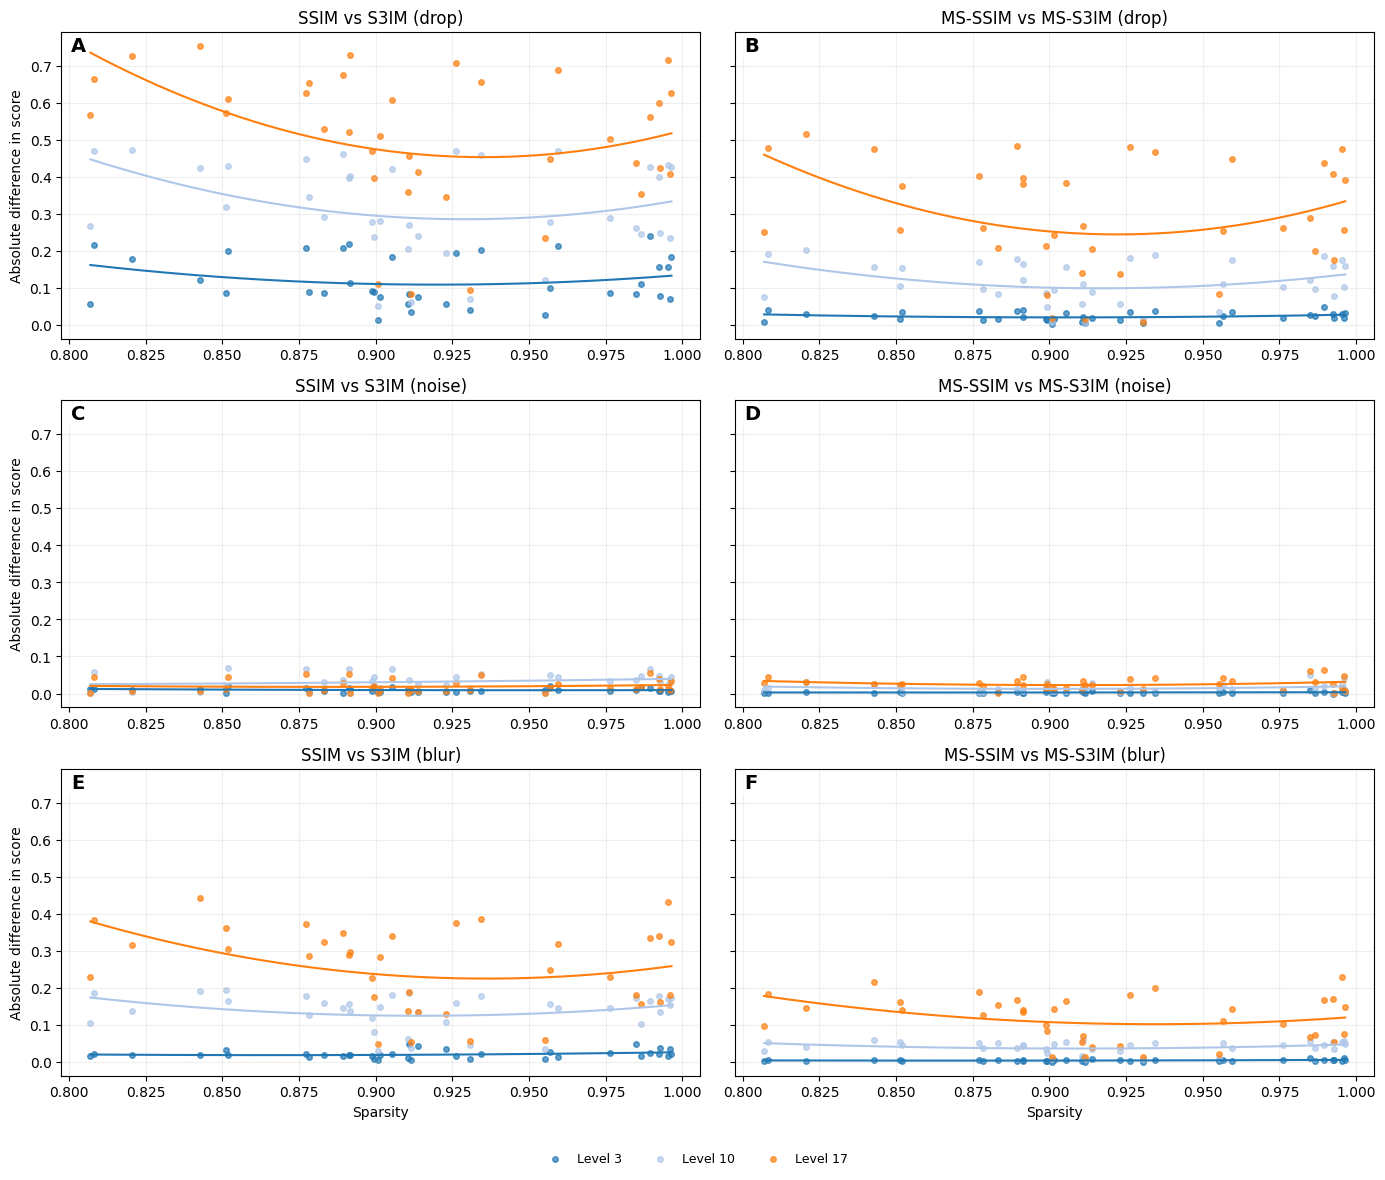

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


# ---- your absolute_diff + compute_differences as given (kept) ----
def absolute_diff(base_vals, roi_vals, mode="raw", eps=1e-6):
    base_vals = np.asarray(base_vals, float)
    roi_vals  = np.asarray(roi_vals,  float)
    raw = np.abs(roi_vals - base_vals)
    if mode == "raw":
        return raw
    if mode == "headroom_abs":
        up = roi_vals >= base_vals
        denom = np.empty_like(base_vals)
        denom[up]  = np.maximum(1.0 - base_vals[up], eps)
        denom[~up] = np.maximum(base_vals[~up], eps)
        return raw / denom
    if mode == "spd_abs":
        return np.abs(2*(roi_vals - base_vals) / np.clip(roi_vals + base_vals, eps, None))
    if mode == "logit_abs":
        p_b = np.clip(base_vals, eps, 1 - eps)
        p_r = np.clip(roi_vals,  eps, 1 - eps)
        logit = lambda p: np.log(p) - np.log(1 - p)
        return np.abs(logit(p_r) - logit(p_b))
    if mode == "asin_abs":
        tr = lambda p: np.arcsin(np.sqrt(np.clip(p, eps, 1 - eps)))
        return np.abs(tr(roi_vals) - tr(base_vals))
    raise ValueError("unknown mode")

PAIR_ORDER = ["SSIM vs S3IM", "MS-SSIM vs MS-S3IM"]

def compute_differences(scores_dict, sparsity_vec, relative=True,
                        sparsity_key='ssim',  # unused now
                        use_true_sparsity=True,
                        exclude_indices=(22, 2)):
    diffs = {}
    pairs = [
        ("ssim",   "s3im",   "SSIM vs S3IM"),
        ("msssim", "mss3im", "MS-SSIM vs MS-S3IM"),
    ]
    for (m1, m2, label) in pairs:
        diffs[label] = {"sparsity": [], "diff": [], "level": []}
        # use your current level sampling pattern
        for level in list(scores_dict[m1].keys())[3::7]:
            base_vals = np.asarray(scores_dict[m1][level], float)
            roi_vals  = np.asarray(scores_dict[m2][level], float)
            s_vals    = np.asarray(sparsity_vec, float)
            # drop specified indices robustly
            if exclude_indices:
                n0 = min(len(base_vals), len(roi_vals), len(s_vals))
                idx = np.arange(n0)
                keep = ~np.isin(idx, [i for i in exclude_indices if i < n0])
                base_vals = base_vals[:n0][keep]
                roi_vals  = roi_vals[:n0][keep]
                s_vals    = s_vals[:n0][keep]
            # align lengths
            n = min(len(base_vals), len(roi_vals), len(s_vals))
            if n == 0: 
                continue
            base_vals = base_vals[:n]
            roi_vals  = roi_vals[:n]
            s_vals    = s_vals[:n]
            # (your sparsity is already "true sparsity": 1 - mean(mask))
            diff_vals = abs(base_vals - roi_vals)
            diffs[label]["sparsity"].extend(s_vals.tolist())
            diffs[label]["diff"].extend(diff_vals.tolist())
            diffs[label]["level"].extend([level]*n)
    return diffs

# ---- helpers for consistent colors + panel tags ----
def _level_color_map(levels):
    levels = sorted(levels)
    cmap = plt.get_cmap('tab20')
    return {lvl: cmap(i % 20) for i, lvl in enumerate(levels)}

def _panel_tag(ax, label, x=0.015, y=0.985):
    ax.text(x, y, label, transform=ax.transAxes,
            ha='left', va='top', fontsize=14, fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=2))

# ---- NEW: one figure with 6 subplots A..F ----
def plot_all_six(diffs_drop, diffs_noise, diffs_blur, poly_deg=2):
    """
    Rows: Dropout, Noise, Blur
    Cols: SSIM vs S3IM | MS-SSIM vs MS-S3IM
    Adds per-level polynomial fits. Shared legend at the bottom. Panels A..F.
    """
    row_titles = ["(drop)", "(noise)", "(blur)"]
    dist_diffs = [diffs_drop, diffs_noise, diffs_blur]

    fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharey=True)
    panel_labels = ['A','B','C','D','E','F']
    pl_idx = 0
    legend_handles = {}
    all_levels_union = set()

    # First pass: gather union of levels across all panels for a stable legend
    for diffs in dist_diffs:
        for d in diffs.values():
            all_levels_union.update(np.unique(d["level"]))
    all_levels_union = sorted(all_levels_union)
    color_map = _level_color_map(all_levels_union)

    for r, diffs in enumerate(dist_diffs):
        for c, label in enumerate(PAIR_ORDER):
            ax = axes[r, c]
            data = diffs[label]
            x = np.array(data["sparsity"], float)
            y = np.array(data["diff"], float)
            levels = np.array(data["level"])

            for lvl in all_levels_union:
                mask = (levels == lvl)
                if not np.any(mask):
                    continue
                x_lvl = x[mask]
                y_lvl = y[mask]

                sc = ax.scatter(x_lvl, y_lvl, s=16, alpha=0.7,
                                color=color_map[lvl], label=f"Level {lvl}")
                if lvl not in legend_handles:
                    legend_handles[lvl] = sc

                # polynomial fit per level if enough unique x
                if np.unique(x_lvl).size >= (poly_deg + 1):
                    coeffs = np.polyfit(x_lvl, y_lvl, deg=poly_deg)
                    xs = np.linspace(x_lvl.min(), x_lvl.max(), 300)
                    ax.plot(xs, np.polyval(coeffs, xs), linewidth=1.5, color=color_map[lvl])

            # titles, labels, panel tag
            ax.set_title(f"{label} {row_titles[r]}")
            if r == 2:   # bottom row
                ax.set_xlabel("Sparsity")
            if c == 0:   # first col
                ax.set_ylabel("Absolute difference in score")
            ax.grid(True, alpha=0.2)
            _panel_tag(ax, panel_labels[pl_idx]); pl_idx += 1

    # Shared legend across all levels
    if legend_handles:
        fig.legend([legend_handles[lvl] for lvl in all_levels_union if lvl in legend_handles],
                   [f"Level {lvl}" for lvl in all_levels_union if lvl in legend_handles],
                   loc="lower center", ncol=min(8, len(all_levels_union)),
                   bbox_to_anchor=(0.5, 0.015), frameon=False, fontsize=9)

    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.show()

# -----------------------
# Build the six-panel fig
# -----------------------
# sparsities2 already computed in your code:
# sparsities2 = np.array([1 - calculate_single_mask(x).mean() for x in greyscaleImages])
sparsities2 = np.array([1 - calculate_single_mask(x).mean() for x in greyscaleImages])

diffs_drop  = compute_differences(scores_drop,  sparsities2, relative=True, exclude_indices=(np.argmin(sparsities2), np.argmin(np.delete(sparsities2, np.argmin(sparsities2)))))
diffs_noise = compute_differences(scores_noise, sparsities2, relative=True, exclude_indices=(np.argmin(sparsities2), np.argmin(np.delete(sparsities2, np.argmin(sparsities2)))))
diffs_blur  = compute_differences(scores_blur,  sparsities2, relative=True, exclude_indices=(np.argmin(sparsities2), np.argmin(np.delete(sparsities2, np.argmin(sparsities2)))))

plot_all_six(diffs_drop, diffs_noise, diffs_blur, poly_deg=2)


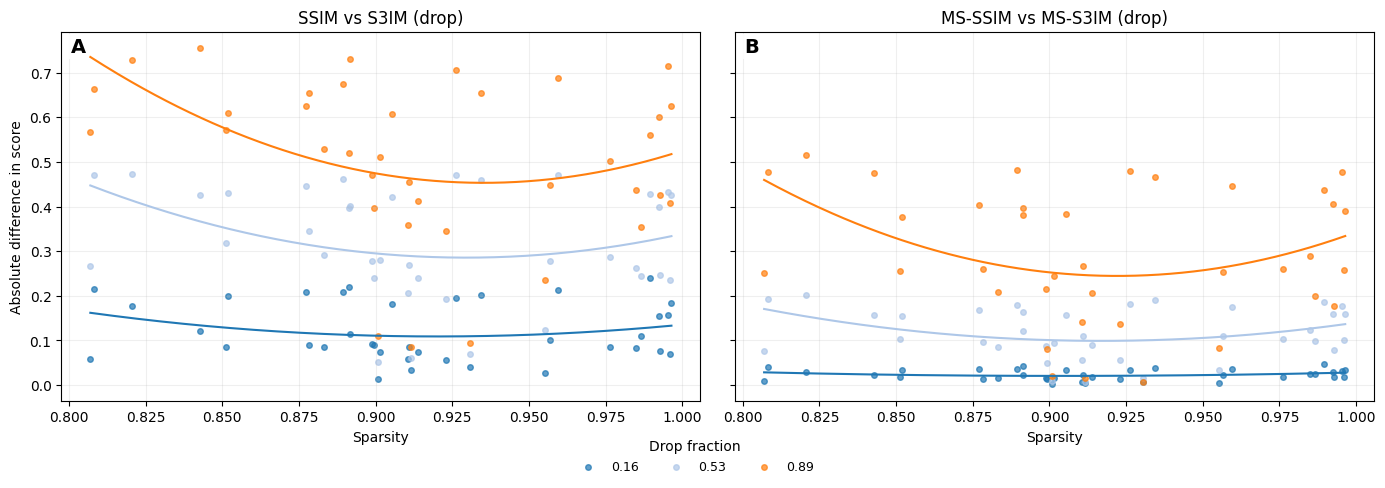

In [ ]:
# === Only the Pixel Dropout (top row) panels A–B, legend shows actual drop fractions ===
def plot_pixel_drop(diffs_drop, drop_fractions, poly_deg=2):
    """
    Cols: SSIM vs S3IM | MS-SSIM vs MS-S3IM
    Adds per-level polynomial fits. Panels A..B.
    Legend labels use the *drop_fractions[level]* value (2 decimals).
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    panel_labels = ['A', 'B']
    legend_handles = {}
    all_levels_union = set()

    # Gather union of levels for a stable legend
    for d in diffs_drop.values():
        all_levels_union.update(np.unique(d["level"]))
    # keep only levels that exist in drop_fractions' index range
    all_levels_union = sorted([lvl for lvl in all_levels_union if int(lvl) < len(drop_fractions)])
    color_map = _level_color_map(all_levels_union)

    # Order legend by actual fraction (low->high)
    legend_order = sorted(all_levels_union, key=lambda l: float(drop_fractions[int(l)]))

    for c, label in enumerate(PAIR_ORDER):
        ax = axes[c]
        data = diffs_drop[label]
        x = np.array(data["sparsity"], float)
        y = np.array(data["diff"], float)
        levels = np.array(data["level"], int)

        for lvl in all_levels_union:
            m = (levels == int(lvl))
            if not np.any(m):
                continue
            x_lvl = x[m]
            y_lvl = y[m]

            frac = float(drop_fractions[int(lvl)])
            legend_text = f"{frac:.2f}"

            sc = ax.scatter(x_lvl, y_lvl, s=16, alpha=0.7,
                            color=color_map[lvl], label=legend_text)
            # only store one handle per fraction label
            if legend_text not in legend_handles:
                legend_handles[legend_text] = sc

            # polynomial fit per level if enough unique x
            if np.unique(x_lvl).size >= (poly_deg + 1):
                coeffs = np.polyfit(x_lvl, y_lvl, deg=poly_deg)
                xs = np.linspace(x_lvl.min(), x_lvl.max(), 300)
                ax.plot(xs, np.polyval(coeffs, xs), linewidth=1.5, color=color_map[lvl])

        ax.set_title(f"{label} (drop)")
        ax.set_xlabel("Sparsity")
        if c == 0:
            ax.set_ylabel("Absolute difference in score")
        ax.grid(True, alpha=0.2)
        _panel_tag(ax, panel_labels[c])

    # Shared legend with fraction labels (sorted by fraction)
    if legend_handles:
        ordered_labels = [f"{float(drop_fractions[int(lvl)]):.2f}" for lvl in legend_order]
        ordered_handles = [legend_handles[lbl] for lbl in ordered_labels if lbl in legend_handles]
        fig.legend(ordered_handles, ordered_labels,
                   title="Drop fraction", loc="lower center",
                   ncol=min(8, len(ordered_labels)),
                   bbox_to_anchor=(0.5, 0.02), frameon=False, fontsize=9)

    plt.tight_layout(rect=[0, 0.07, 1, 1])
    plt.show()

# --- call for pixel dropout only ---
# pass your 1D array/list `drop_fractions` where index == level
plot_pixel_drop(diffs_drop, drop_fractions, poly_deg=2)



In [ ]:
diffs_drop

{'SSIM vs S3IM': {'sparsity': [0.8832311039226123,
   0.8987696298554664,
   0.9925123631271348,
   0.8914938584841798,
   0.806985360610586,
   0.9306269668611351,
   0.9261984611330154,
   0.996150248812778,
   0.8520145308729375,
   0.9926777215673913,
   0.9866163012417385,
   0.8894888873960697,
   0.9138534200776152,
   0.8513324273068794,
   0.8771645161457015,
   0.9007849358460926,
   0.9593890005632522,
   0.996455128437001,
   0.9896237578739039,
   0.901554886083537,
   0.9953234566114955,
   0.8427854629261209,
   0.8912716580800851,
   0.9342855223518104,
   0.9567174282628579,
   0.8783840346425933,
   0.9106392653951292,
   0.9551671928854532,
   0.9850040564492375,
   0.80827722342509,
   0.9108924705067719,
   0.8993793891039122,
   0.9116934254517645,
   0.820524082906588,
   0.9762969010794805,
   0.9053271255018887,
   0.9229946413530454,
   0.8832311039226123,
   0.8987696298554664,
   0.9925123631271348,
   0.8914938584841798,
   0.806985360610586,
   0.930626966

In [ ]:
from scipy.ndimage import gaussian_filter
from skimage.util import random_noise

# Keep letters continuous across figures
next_lab = 'A'

original_img = greyscaleImages[0]
dropped = drop_pixels(original_img, 0.8)

# --- Dropout ---
plot_single_row_match_image_height(
    original_img=original_img,
    distorted_img=dropped,
    x_levels=drop_fractions,
    avg_scores=avg_scores_drop,
    xlabel="Drop Fraction",
    title_curves="Pixel Dropout — Metrics vs Drop Fraction",
    compute_metrics_fn=compute_metrics,
    width_ratio=(2.7, 2.8),
    invert_x=False,
    start_label= 'A'
)

# --- Blur ---
og_img = greyscaleImages[20]
blurred_img = gaussian_filter(og_img, sigma=2)

plot_single_row_match_image_height(
    original_img=og_img,
    distorted_img=blurred_img,
    x_levels=blur_levels,
    avg_scores=avg_scores_blur,
    xlabel="Sigma",
    title_curves="Gaussian Blur — Metrics vs Sigma",
    compute_metrics_fn=compute_metrics,
    width_ratio=(2.7, 2.8),
    invert_x=False,
    start_label= 'A'
)

# --- Noise ---
og_img2 = greyscaleImages[26]
noisy_img = random_noise(og_img2, mode='gaussian', var=0.02, clip=True, rng=42)

plot_single_row_match_image_height(
    original_img=og_img2,
    distorted_img=noisy_img,
    x_levels=avg_scores_noise['snr'],
    avg_scores=avg_scores_noise,
    xlabel="Signal-to-Noise Ratio (linear)",
    title_curves="Noise — Metrics vs SNR (higher is cleaner)",
    compute_metrics_fn=compute_metrics,
    width_ratio=(2.7, 2.8),
    invert_x=True,
    start_label= 'A'
)
avg_pas = {
    'ssim': avg_ssim_scores_PA, 'msssim': avg_msssim_scores_PA, 's3im': avg_s3im_scores_PA, 'mss3im': avg_mss3im_scores_PA, 'psnr': avg_psnr_scores_PA, 'mse': avg_mse_scores_PA
}
[25600,2560,  1280, 640, 384, 256, 128]

im = PA_from_base['Phantoms__PrintedPhantom_Rf_062323_234747']['PA1']
im2 = PA_from_base['Phantoms__PrintedPhantom_Rf_062323_234747']['PA4']
plot_single_row_match_image_height(
    original_img=im,
    distorted_img=im2,
    x_levels=[25600,2560,  1280, 640, 384, 256, 128],
    avg_scores=avg_pas,
    xlabel="Frames averaged",
    title_curves="Frame averaging — Metrics vs Frames averaged",
    compute_metrics_fn=compute_metrics,
    width_ratio=(2.7, 2.8),
    invert_x=True,
    start_label= 'A'
)
avg_pas

NameError: name 'plot_single_row_match_image_height' is not defined

In [ ]:
PA_from_base.keys()

dict_keys(['Small Animal__Tumor_Rf_110720_005952', 'Phantoms__PrintedPhantom_Rf_062323_234747', 'Small Animal__Tumor_Rf_111220_215952', 'Small Animal__Tumor_Rf_111220_224023', 'Small Animal__Tumor_Rf_110720_005835', 'Invivo__CarotidTest_Rf_022522_205204', 'Phantoms__PrintedPhantom_Rf_062423_000920', 'Invivo__BloodVesselDepth_Rf_061821_213520', 'Small Animal__Tumor_Rf_110720_010703', 'Phantoms__PrintedPhantom_Rf_062423_000336', 'Phantoms__PrintedPhantom_Rf_062323_232150', 'Small Animal__Tumor_Rf_111220_221229', 'Invivo__RadialArtery_RF_030320_010729', 'Phantoms__PrintedPhantom_Rf_062323_233838', 'Phantoms__PrintedPhantom_Rf_062423_001030', 'Small Animal__Tumor_Rf_111220_220935', 'Small Animal__Tumor_Rf_111220_222853', 'Small Animal__Tumor_Rf_110720_005432', 'Invivo__BloodVesselDepth_Rf_061821_214833', 'Small Animal__Tumor_Rf_110720_010244', 'Phantoms__PrintedPhantom_Rf_062323_192200', 'Invivo__BloodvesselDepth_Rf_061821_180645', 'Phantoms__PrintedPhantom_Rf_062323_233206', 'Invivo__Bloo

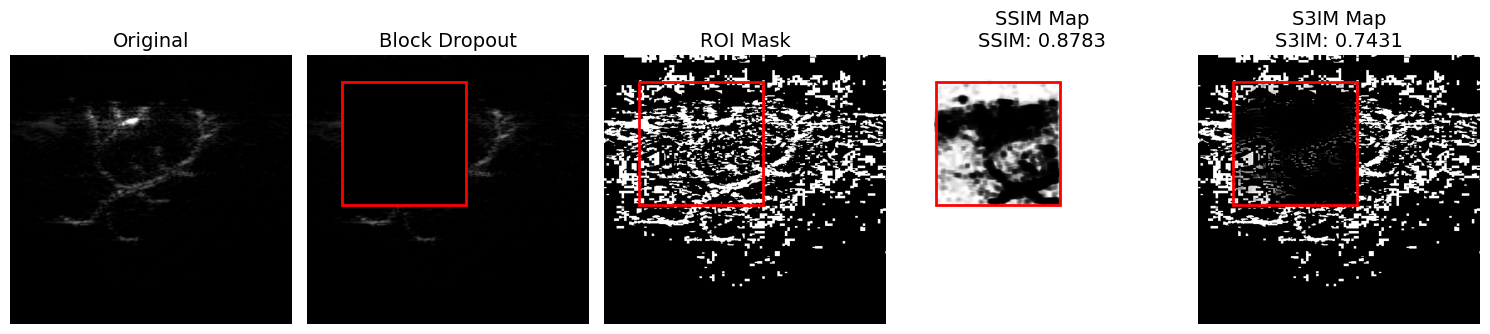

In [ ]:
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# Apply dropout
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(original_img, block_dropped_img, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "ROI Mask", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    original_img, 
    block_dropped_img, 
    s3im_mask,
    ssim_map, 
    s3im_map
]

from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# Apply dropout
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(original_img, block_dropped_img, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "ROI Mask", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    original_img, 
    block_dropped_img, 
    s3im_mask,
    ssim_map, 
    s3im_map
]

# Plot in 2 rows (3 cols max)
fig, axes = plt.subplots(1, 5, figsize=(15, 8))
axes = axes.flatten()

for idx, (ax, title, img) in enumerate(zip(axes, titles, images)):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
    if idx != 0:
        rect = Rectangle((x, y), size, size, linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
    if idx == 3:
        ax.set_title(
            f"""{title}
SSIM: {SSIM_score:.4f}""",
            fontsize=14
        )
    elif title == "S3IM Map":
        ax.set_title(
            f"""{title}
S3IM: {S3IM_score:.4f}""",
            fontsize=14
        )
    else:
        ax.set_title(title, fontsize=14)

# Hide any extra subplot (if 6th is unused)
if len(images) < len(axes):
    for i in range(len(images), len(axes)):
        axes[i].axis("off")

plt.tight_layout()
plt.show()

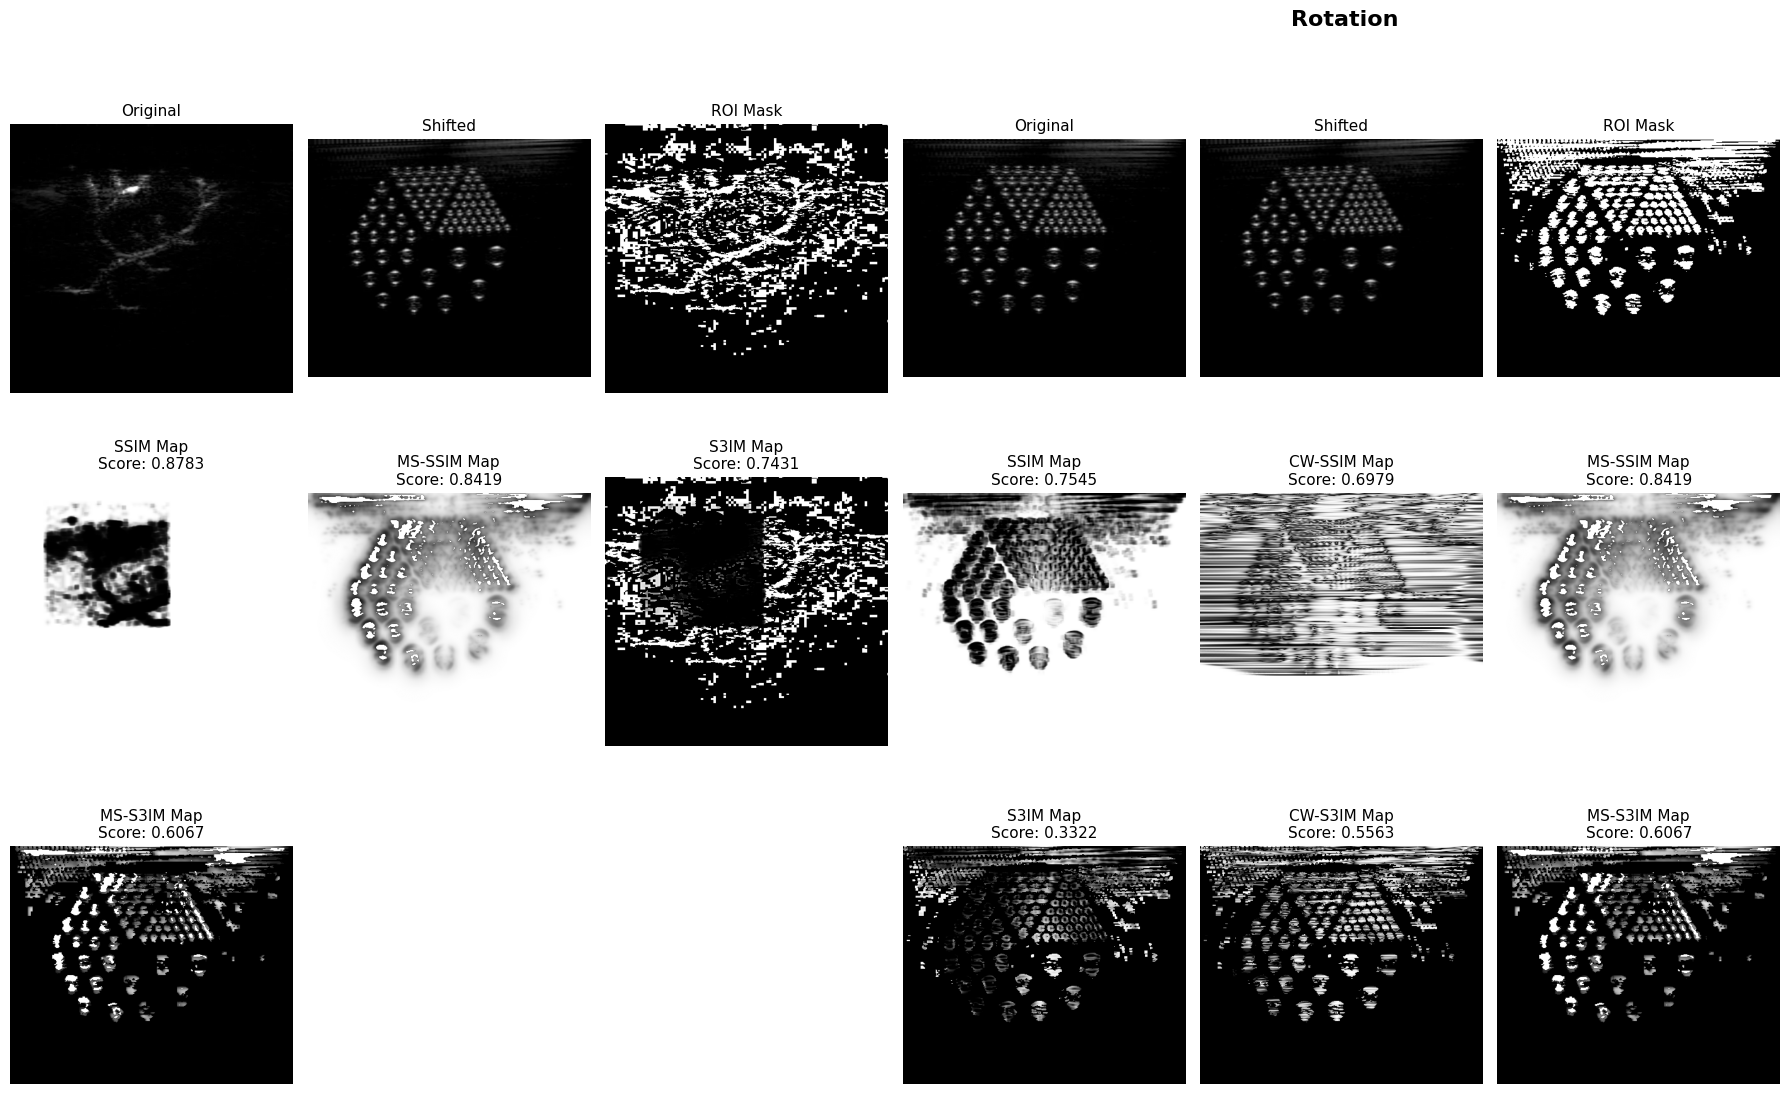

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def visualize_metric_maps(original_img, shifted_img,
                          SSIM_score, ssim_map,
                          ms_ssim_score, ms_ssim_map,
                          S3IM_score, s3im_mask, s3im_map,
                          ms_s3im_score, ms_s3im_map,
                          scene_title=""):
    """Package titles, images, and scores aligned for plotting."""
    titles = [
        "Original", 
        "Shifted", 
        "ROI Mask",
        "SSIM Map",
        "MS-SSIM Map",
        "S3IM Map",
        "MS-S3IM Map"
    ]
    scores = [None, None, None, SSIM_score, ms_ssim_score, S3IM_score, ms_s3im_score]
    images = [original_img, shifted_img, s3im_mask, ssim_map, ms_ssim_map, s3im_map, ms_s3im_map]
    return titles, images, scores, scene_title

# --- Build your two blocks (fill with your actual variables) ---
# Example:
# viz1 = visualize_metric_maps(orig1, shifted1,
#                              SSIM1, ssim_map1,
#                              MSSSIM1, msssim_map1,
#                              S3IM1, s3im_mask1, s3im_map1,
#                              MSS3IM1, mss3im_map1,
#                              scene_title="Scene A")
# viz2 = visualize_metric_maps(orig2, shifted2,
#                              SSIM2, ssim_map2,
#                              MSSSIM2, msssim_map2,
#                              S3IM2, s3im_mask2, s3im_map2,
#                              MSS3IM2, mss3im_map2,
#                              scene_title="Scene B")

# Replace these two lines with the real calls above:
viz1 = visualize_metric_maps(original_img, shifted_img,
                          SSIM_score, ssim_map,
                          ms_ssim_score, ms_ssim_map,
                          S3IM_score, s3im_mask, s3im_map,
                          ms_s3im_score, ms_s3im_map,
                          scene_title="")

# --- Plot: 3 rows × 6 cols (two 3-col blocks) ---
fig, axes = plt.subplots(3, 6, figsize=(18, 12))
axes = np.asarray(axes)

# Start with everything hidden; we’ll show only the used tiles
for ax in axes.ravel():
    ax.set_visible(False)

for col_idx, (titles, images, scores, block_title) in enumerate([viz1, viz2]):
    col_offset = col_idx * 3  # left block (0..2), right block (3..5)

    for idx, (title, img, score) in enumerate(zip(titles, images, scores)):
        row = idx // 3
        col = (idx % 3) + col_offset
        ax = axes[row, col]
        ax.set_visible(True)

        # If mask is boolean, imshow handles it fine; set limits for metric maps in [0,1]
        ax.imshow(img, cmap='gray', vmin=0, vmax=1)
        ax.axis('off')

        if score is not None:
            ax.set_title(f"{title}\nScore: {score:.4f}", fontsize=11)
        else:
            ax.set_title(title, fontsize=11)

    # Block title centered over the block (figure coords)
    # Center of this 3-col block among 6 total columns:
    x_center = (col_offset + 1.5) / 6.0
    fig.text(x_center, 0.95, block_title, ha='center', va='bottom',
             fontsize=16, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])  # leave room for block titles
plt.show()


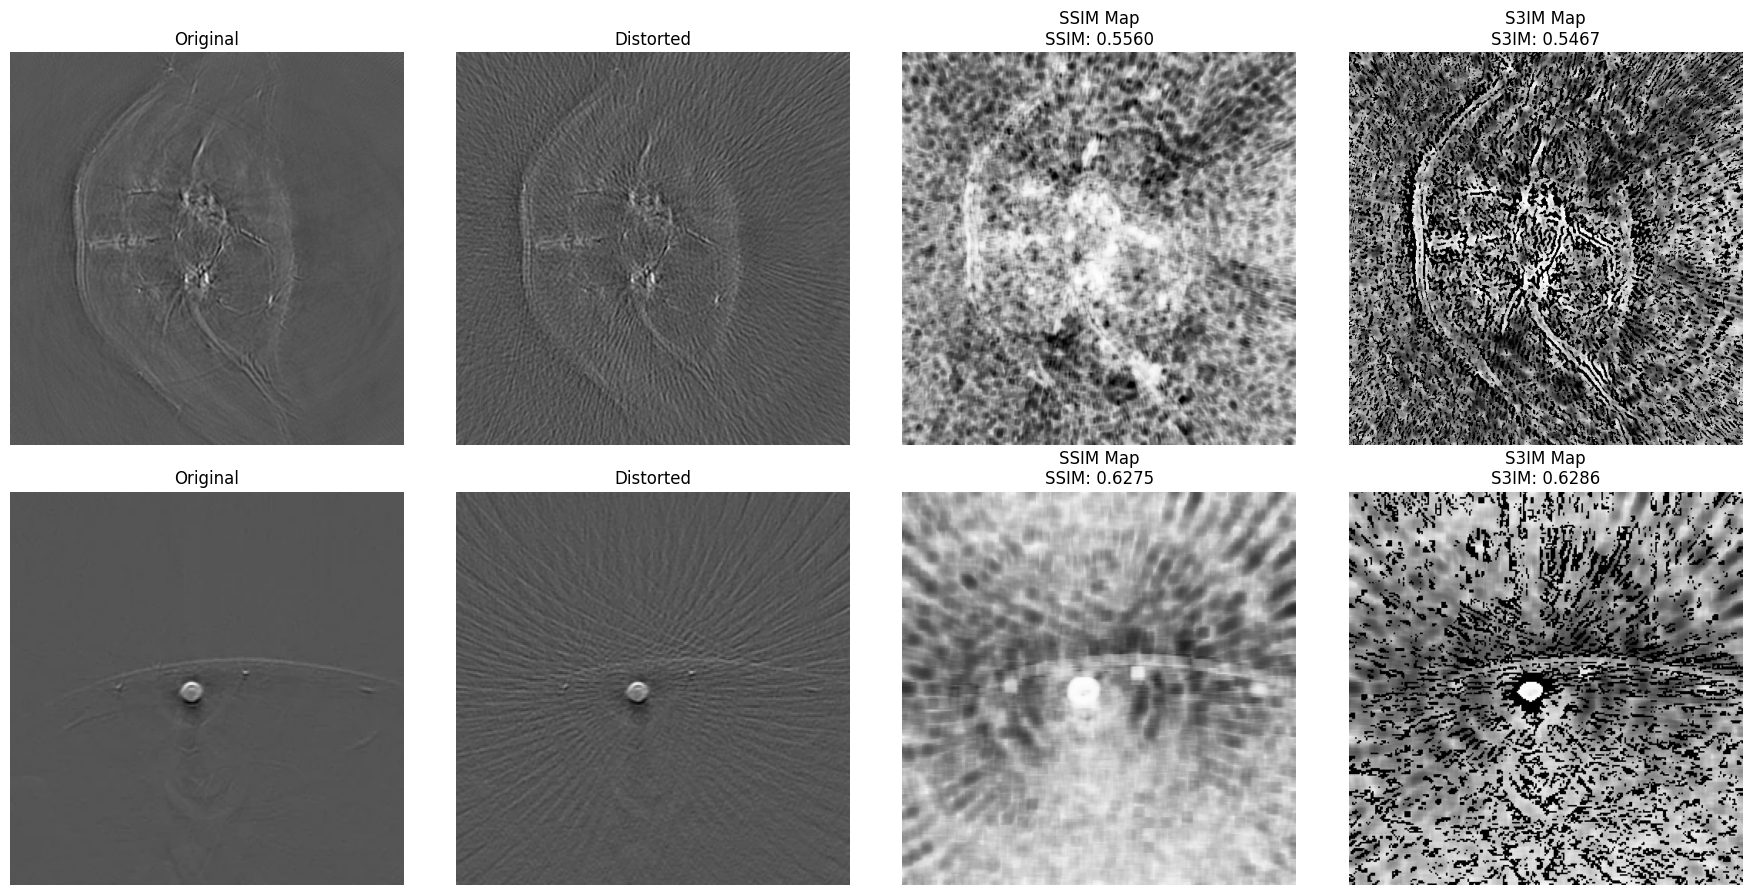

In [ ]:
from matplotlib import pyplot as plt
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_5005/KWave_Rf_090122_211601 PA1.webp") as img:
    original_img = img.convert('L')
    original_img = img_as_float(original_img)

# Apply dropout
block_dropped_mask = calculate_single_mask(original_img)
block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(original_img, block_dropped_img, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(original_img, block_dropped_img, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "ROI Mask", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    original_img, 
    block_dropped_img, 
    s3im_mask,
    ssim_map, 
    s3im_map
]

from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PIL_Image
from skimage.metrics import structural_similarity
from skimage.util import img_as_float

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_full.webp") as img:
    ref_img = img.convert('L')
    ref_img = img_as_float(ref_img)
    # mask2 = calculate_single_mask(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_2213/image_192_128.webp") as img:
    ref_img2 = img.convert('L')
    ref_img2 = img_as_float(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc_BP_slice0046.webp") as img:
    ref_img3 = img.convert('L')
    ref_img3 = img_as_float(ref_img3)
    # mask2 = calculate_single_mask(ref_img2)

with PIL_Image.open("./data/VARIED SPLIT V3 CURRENT/scene_3215/SWFD_semicircle_sc,ss32_BP_slice0046.webp") as img:
    ref_img4 = img.convert('L')
    ref_img4 = img_as_float(ref_img4)
# Apply dropout
# block_dropped_mask = calculate_single_mask(original_img)
# block_dropped_img, (x, y, size) = mask_square_over_roi(original_img, block_dropped_mask, 0.2)

# Compute SSIM and S3IM maps
SSIM_score, ssim_map = structural_similarity(ref_img, ref_img2, win_size=7, full=True, data_range=1.0)
S3IM_score, s3im_mask, s3im_map = s3im(ref_img, ref_img2, window_size=7)

SSIM_score2, ssim_map2 = structural_similarity(ref_img3, ref_img4, win_size=7, full=True, data_range=1.0)
S3IM_score2, s3im_mask2, s3im_map2 = s3im(ref_img3, ref_img4, window_size=7)

# Prepare visualization
titles = [
    "Original", 
    "Block Dropout", 
    "SSIM Map", 
    "S3IM Map"
]

images = [
    ref_img,
    ref_img2, 
    ssim_map, 
    s3im_map
]

# Titles for both sets
titles = ["Original", "Distorted", "SSIM Map", "S3IM Map"]

# First comparison
images1 = [ref_img, ref_img2, ssim_map, s3im_map]
scores1 = [None, None, SSIM_score, S3IM_score]

# Second comparison
images2 = [ref_img3, ref_img4, ssim_map2, s3im_map2]
scores2 = [None, None, SSIM_score2, S3IM_score2]

# Create subplot grid: 2 rows × 4 cols
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Plot first row
for idx, (ax, title, img, score) in enumerate(zip(axes[0], titles, images1, scores1)):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
    if score is not None:
        ax.set_title(f"{title}\n{title.split()[0]}: {score:.4f}", fontsize=12)
    else:
        ax.set_title(title, fontsize=12)

# Plot second row
for idx, (ax, title, img, score) in enumerate(zip(axes[1], titles, images2, scores2)):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
    if score is not None:
        ax.set_title(f"{title}\n{title.split()[0]}: {score:.4f}", fontsize=12)
    else:
        ax.set_title(title, fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
mapp = cw_ssim(greyscaleImages[1], greyscaleImages[1])
np.sum(mapp) / np.sum(mapp != 0)

1.0

In [ ]:
val, _, _ = s3im(greyscaleImages[1], greyscaleImages[1], SSIM_variant=cw_ssim)
val

1.0

In [ ]:
sensitivities_noise

{'ssim': {0: [0.33618921139526353,
   0.34123264382308716,
   0.3301432934233848,
   0.33980125982461673,
   0.34093809910138023,
   0.43808101530082316,
   0.3180617923821434,
   0.3697569747673355,
   0.3245727809672435,
   0.35731891958929096,
   0.38555387326309043,
   0.3325048186482981,
   0.3672662632609718,
   0.3233790997266418,
   0.31931748303784124,
   0.4303453407675732,
   0.3226504890992616,
   0.32870157452239834,
   0.3523891710891437,
   0.3322981205979775,
   0.33433926384489376,
   0.332143097060237,
   0.35030668823216327,
   0.3221647486810081,
   0.3669148765754267,
   0.3410259457727665,
   0.3408864245888001,
   0.33475265994553505,
   0.3433564662901317,
   0.3486892759884042,
   0.3730124690598856,
   0.32896511453655713,
   0.36509593373260507,
   0.3640366062247118,
   0.4366754685586428,
   0.3333781179109028,
   0.33835954092363024,
   0.3329440520052295,
   0.364439667422837],
  1: [0.34106728538283065,
   0.34623473664084664,
   0.33443227796753805,
   